- Herda EDA e Feature Selection do Ciclo 02
- Inclusao de Fine-Tuning de hiperparametros (Random/Grid/Bayesian Search)
- Validacao cruzada com K-Fold estratificado

# 1.0 Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Silencia so uma categoria (ex: avisos de depreciacao)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Silencia so os warnings de uma lib especifica (ex: sklearn/lightgbm)
warnings.filterwarnings("ignore", module="sklearn")


In [3]:
from pathlib import Path

import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import preprocessing as pp
from sklearn import metrics as mt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import VarianceThreshold
import sklearn.ensemble as en

from scipy import stats
from scipy.stats import gaussian_kde
from scipy.stats import pointbiserialr
from scipy.stats import chi2_contingency

from boruta import BorutaPy

import xgboost as xgb
from lightgbm import LGBMClassifier

In [4]:
# --- Imports do Ciclo 03: fine-tuning + cross-validation ---
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

import optuna

# 2.0 Loading Data

In [5]:
# Sobe a partir da pasta atual ate encontrar a raiz do projeto (onde esta pyproject.toml)
def project_root(start: Path = Path.cwd()) -> Path:
    for parent in [start, *start.parents]:
        if (parent / "pyproject.toml").exists():
            return parent
    raise FileNotFoundError("Raiz do projeto (pyproject.toml) nao encontrada")

ROOT = project_root()
DATA_PATH = ROOT / "data" / "HR-Employee-Attrition-balanced.csv"

df_raw = pd.read_csv(DATA_PATH)
df_raw

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,58,Yes,Travel_Rarely,601,Research & Development,7,4,Medical,1,1360,...,4,80,0,31,0,2,10,9,5,9
1,27,Yes,Travel_Frequently,1341,Human Resources,21,2,Human Resources,1,1950,...,1,80,0,0,2,3,0,0,0,0
2,50,Yes,Travel_Rarely,407,Sales,28,3,Marketing,1,2049,...,2,80,1,19,3,2,2,2,1,0
3,39,No,Non-Travel,439,Research & Development,9,3,Life Sciences,1,1132,...,3,80,0,9,2,2,5,4,0,3
4,32,No,Travel_Rarely,601,Sales,7,5,Marketing,1,1446,...,3,80,1,7,3,2,4,3,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1756,35,No,Travel_Rarely,750,Research & Development,28,3,Life Sciences,1,1596,...,4,80,2,10,3,2,10,9,6,8
1757,41,No,Travel_Rarely,447,Research & Development,5,3,Life Sciences,1,1814,...,1,80,0,11,3,1,3,2,1,2
1758,22,Yes,Travel_Frequently,1256,Research & Development,3,4,Life Sciences,1,1203,...,2,80,1,1,5,3,0,0,0,0
1759,29,No,Travel_Rarely,1378,Research & Development,13,2,Other,1,2053,...,1,80,1,10,2,3,4,3,0,3


# 3.0 Data Split - Train + Test

In [6]:
# Coluna alvo do problema de classificação.
TARGET_COLUMN = "Attrition"

X = df_raw.drop(columns=[TARGET_COLUMN])
y = df_raw[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

# Reconstroi os DataFrames completos de treino e teste.
df_train_total = X_train.join(y_train)
df_test = X_test.join(y_test)

print(f"Treino: {df_train_total.shape[0]} linhas")
print(f"Teste:  {df_test.shape[0]} linhas")
print("\nProporção da variável alvo (treino):")
print(y_train.value_counts(normalize=True))
print("\nProporção da variável alvo (teste):")
print(y_test.value_counts(normalize=True))

Treino: 1408 linhas
Teste:  353 linhas

Proporção da variável alvo (treino):
Attrition
No     0.700284
Yes    0.299716
Name: proportion, dtype: float64

Proporção da variável alvo (teste):
Attrition
No     0.699717
Yes    0.300283
Name: proportion, dtype: float64


## 3.1 Train Data Split - Train - Val

In [7]:
df_train_01 = df_train_total.copy()

# Convert response variable from categorial to numerical
df_train_01['Attrition'] = df_train_01["Attrition"].apply(lambda x: 1 if x == "Yes" else 0)

In [8]:
X_train_total = df_train_01.drop('Attrition', axis=1)
y_train_total = df_train_01['Attrition']

# Train and Validation Split
X_train, X_val, y_train, y_val = train_test_split(X_train_total, y_train_total, test_size=0.20, random_state=42, stratify=y_train_total)

# Reconstroi os DataFrames completos de treino e val.
df_train = X_train.join(y_train) # df_train com y de coluna tambem
df_val = X_val.join(y_val)

print(f"Treino: {df_train.shape[0]} linhas")
print(f"Teste:  {df_val.shape[0]} linhas")
print("\nProporção da variável alvo (treino):")
print(y_val.value_counts(normalize=True))
print("\nProporção da variável alvo (validação):")
print(y_val.value_counts(normalize=True))

Treino: 1126 linhas
Teste:  282 linhas

Proporção da variável alvo (treino):
Attrition
0    0.698582
1    0.301418
Name: proportion, dtype: float64

Proporção da variável alvo (validação):
Attrition
0    0.698582
1    0.301418
Name: proportion, dtype: float64


# 4.0 Data Cleaning

In [9]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 1126 entries, 1539 to 1111
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1126 non-null   int64
 1   BusinessTravel            1126 non-null   str  
 2   DailyRate                 1126 non-null   int64
 3   Department                1126 non-null   str  
 4   DistanceFromHome          1126 non-null   int64
 5   Education                 1126 non-null   int64
 6   EducationField            1126 non-null   str  
 7   EmployeeCount             1126 non-null   int64
 8   EmployeeNumber            1126 non-null   int64
 9   EnvironmentSatisfaction   1126 non-null   int64
 10  Gender                    1126 non-null   str  
 11  HourlyRate                1126 non-null   int64
 12  JobInvolvement            1126 non-null   int64
 13  JobLevel                  1126 non-null   int64
 14  JobRole                   1126 non-null   str  
 15  

- Dados já vieram tratados - Sem NA e sem colunas para conversão

# 5.0 Feature Engineering

In [10]:
# 1. Estabilidade e Fidelidade
for df_ in [df_train, df_val]:
    df_['CareerStability'] = df_['TotalWorkingYears'] / (df_['NumCompaniesWorked'] + 1)
    df_['LoyaltyRatio'] = df_['YearsAtCompany'] / (df_['TotalWorkingYears'] + 1e-6)

# 2. Renda Relativa (Mede frustração salarial por nível)
median_income_per_level = df_train.groupby('JobLevel')['MonthlyIncome'].transform('median')
df_train['IncomeRelativeToLevel'] = df_train['MonthlyIncome'] / median_income_per_level

median_income_test = df_val.groupby('JobLevel')['MonthlyIncome'].transform('median')
df_val['IncomeRelativeToLevel'] = df_val['MonthlyIncome'] / median_income_test

# 3. Impacto de Deslocamento e Estagnação
for df_ in [df_train, df_val]:
    df_['CommuteImpact'] = df_['DistanceFromHome'] / (df_['MonthlyIncome'] + 1e-6)
    df_['PromotionLag'] = df_['YearsSinceLastPromotion'] / (df_['YearsInCurrentRole'] + 1e-6)
    df_['ManagerTrust'] = df_['YearsWithCurrManager'] / (df_['YearsAtCompany'] + 1e-6)
    
# 4. Satisfação Consolidada
for df_ in [df_train, df_val]:
    df_['TotalSatisfactionScore'] = (df_['EnvironmentSatisfaction'] + 
                                     df_['JobSatisfaction'] + 
                                     df_['RelationshipSatisfaction'] + 
                                     df_['WorkLifeBalance'])

# 5. Risco: Horas Extras com Baixo Envolvimento
for df_ in [df_train, df_val]:
    df_['OverTimeRisk'] = df_.apply(lambda x: 1 if (x['OverTime'] == 'Yes') and (x['JobInvolvement'] < 3) else 0, axis=1)

# 6. Categórica: Ciclo de Vida
for df_ in [df_train, df_val]:
    df_['AgeGroup'] = df_['Age'].apply(lambda x: 'young' if x < 25 else ('adult' if x < 45 else 'senior'))

# 7. Estabilidade Profissional (Variáveis Refinadas)
for df_ in [df_train, df_val]:
    df_['Stability_Ratio'] = df_['YearsAtCompany'] / (df_['TotalWorkingYears'] + 1e-5)
    df_['Income_Age_Ratio'] = df_['MonthlyIncome'] / df_['Age']
    df_['Manager_Loyalty'] = df_['YearsWithCurrManager'] / (df_['YearsAtCompany'] + 1e-5)

df_train.fillna(0, inplace=True)
df_val.fillna(0, inplace=True)
print("✅ Feature Engineering concluída para Train e Val!")

✅ Feature Engineering concluída para Train e Val!


# 6.0 EDA

## 6.1 Univariate

### 6.1.1 Num attributes

In [11]:
# Atributos numéricos (exclui a variável alvo, que é categórica).
train_num_attributes = df_train.select_dtypes(include=["number"]).columns.tolist()

df_train_num = df_train[train_num_attributes].describe().T
df_train_num.style.background_gradient(cmap = 'Blues')

,count,mean,std,min,25%,50%,75%,max
Age,1126.000000,36.126110,9.225573,17.000000,29.250000,35.000000,42.000000,60.000000
DailyRate,1126.000000,800.674956,407.573816,97.000000,443.000000,791.000000,1167.750000,1496.000000
DistanceFromHome,1126.000000,9.475133,8.255735,0.000000,2.000000,7.000000,15.000000,29.000000
Education,1126.000000,2.838366,1.070237,0.000000,2.000000,3.000000,4.000000,5.000000
EmployeeCount,1126.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
EmployeeNumber,1126.000000,1045.992007,604.658897,0.000000,514.500000,1033.500000,1588.000000,2065.000000
EnvironmentSatisfaction,1126.000000,2.613677,1.173390,0.000000,2.000000,3.000000,4.000000,4.000000
HourlyRate,1126.000000,65.025755,20.498027,30.000000,47.000000,64.000000,83.000000,100.000000
JobInvolvement,1126.000000,2.580817,0.819835,0.000000,2.000000,3.000000,3.000000,4.000000
JobLevel,1126.000000,1.920959,1.142304,0.000000,1.000000,2.000000,2.000000,5.000000


Colunas sem relevancia (max = min):
- EmployeeCount
- StandardHours

In [12]:
# Dropando EmployeeCount e StandardHours dos dados de treino
df_train.drop(['EmployeeCount', 'StandardHours'], inplace=True, axis=1)

# Dropando EmployeeCount e StandardHours dos dados de treino
df_val.drop(['EmployeeCount', 'StandardHours'], inplace=True, axis=1)

In [13]:
train_num_attributes.remove('EmployeeCount')
train_num_attributes.remove('StandardHours')

In [14]:
train_num_attributes

['Age',
 'DailyRate',
 'DistanceFromHome',
 'Education',
 'EmployeeNumber',
 'EnvironmentSatisfaction',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobSatisfaction',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager',
 'Attrition',
 'CareerStability',
 'LoyaltyRatio',
 'IncomeRelativeToLevel',
 'CommuteImpact',
 'PromotionLag',
 'ManagerTrust',
 'TotalSatisfactionScore',
 'OverTimeRisk',
 'Stability_Ratio',
 'Income_Age_Ratio',
 'Manager_Loyalty']

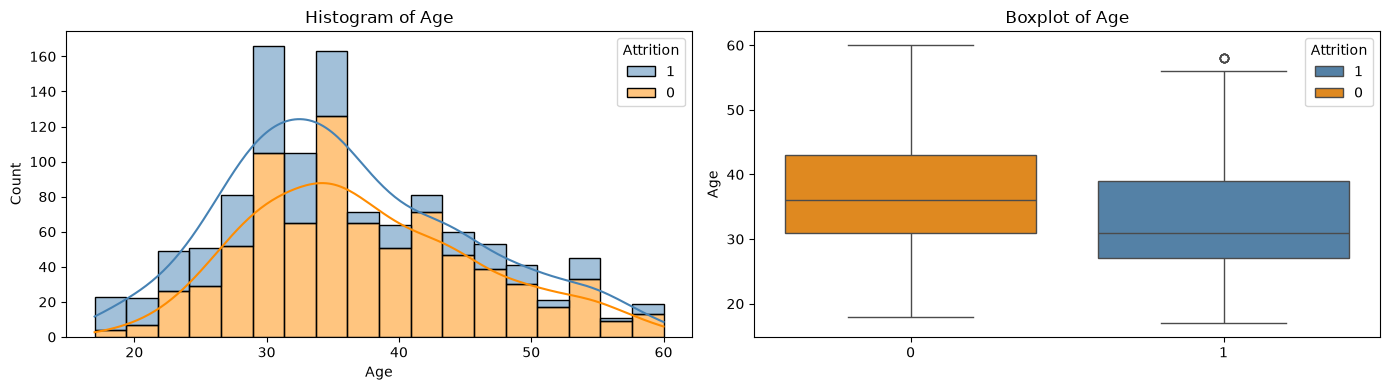

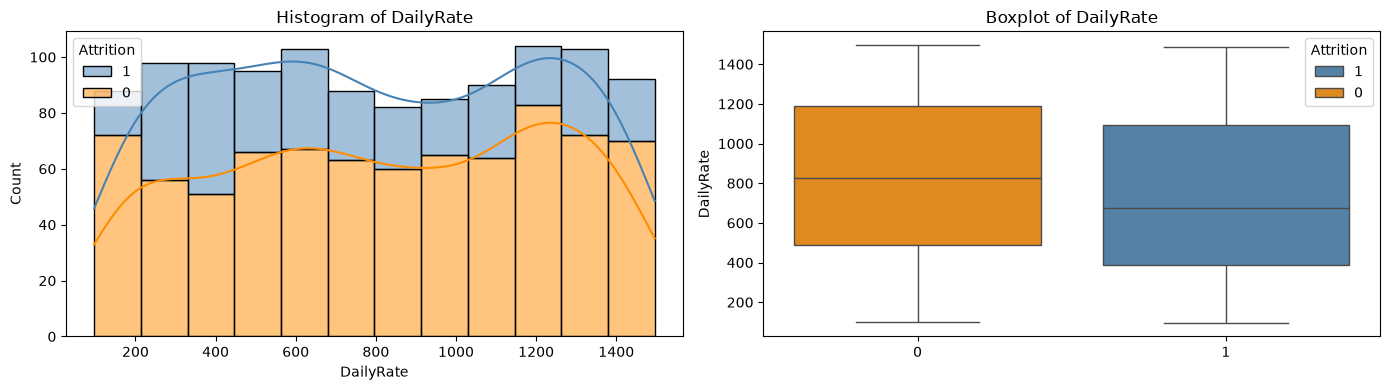

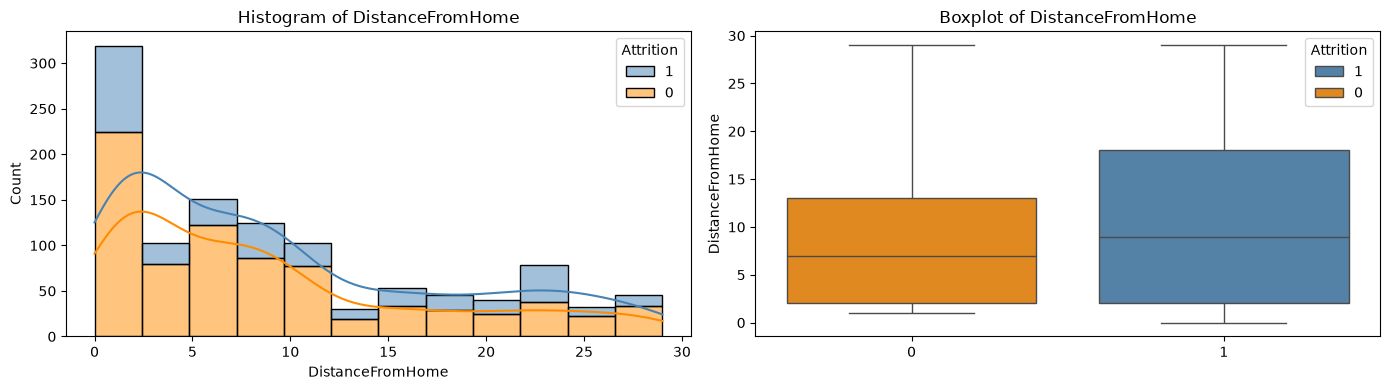

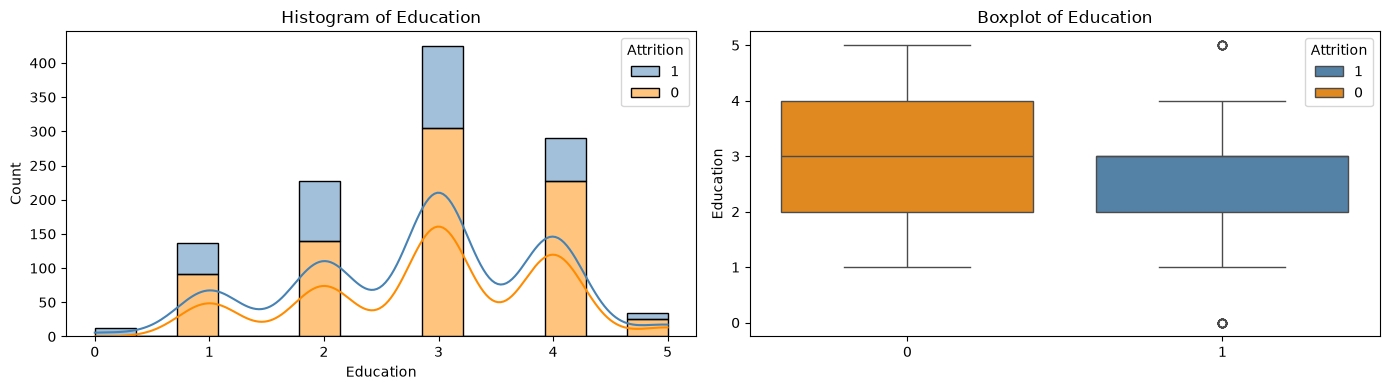

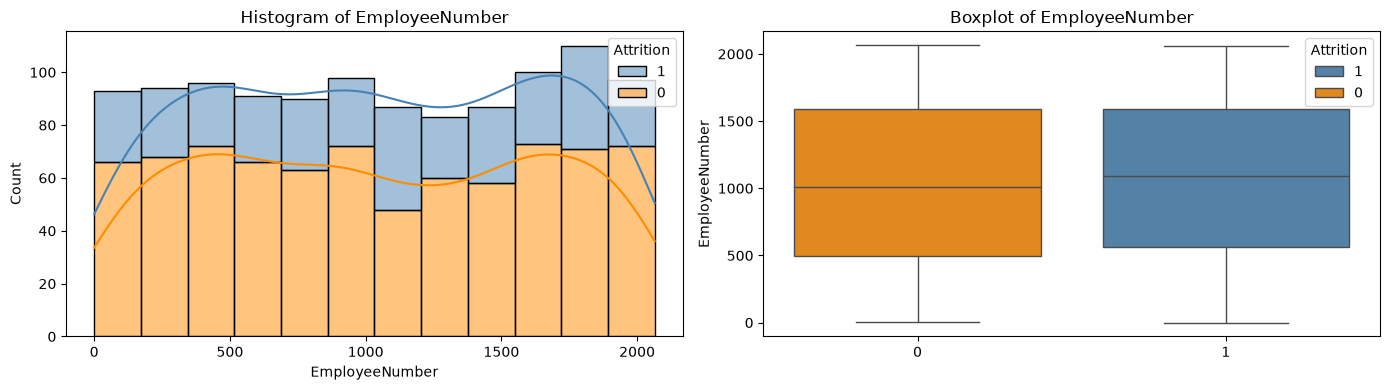

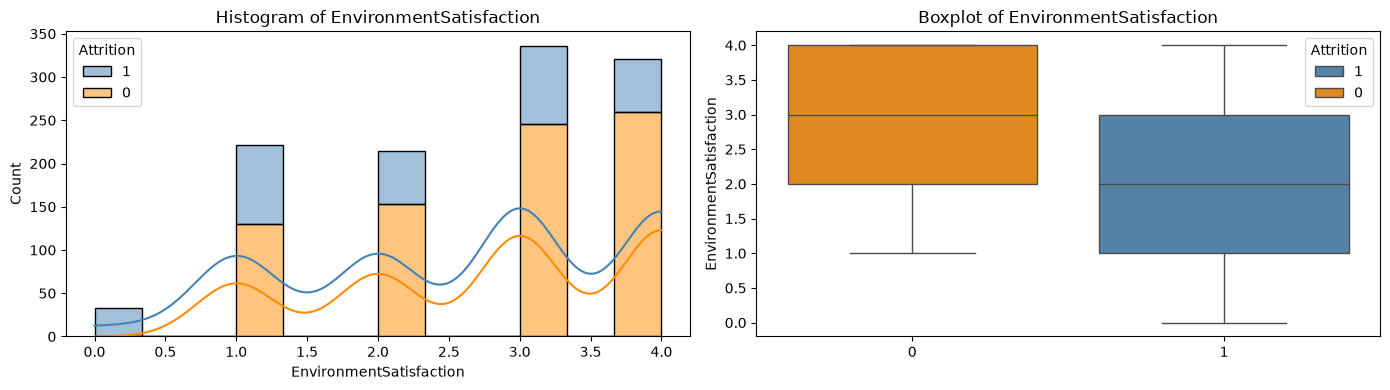

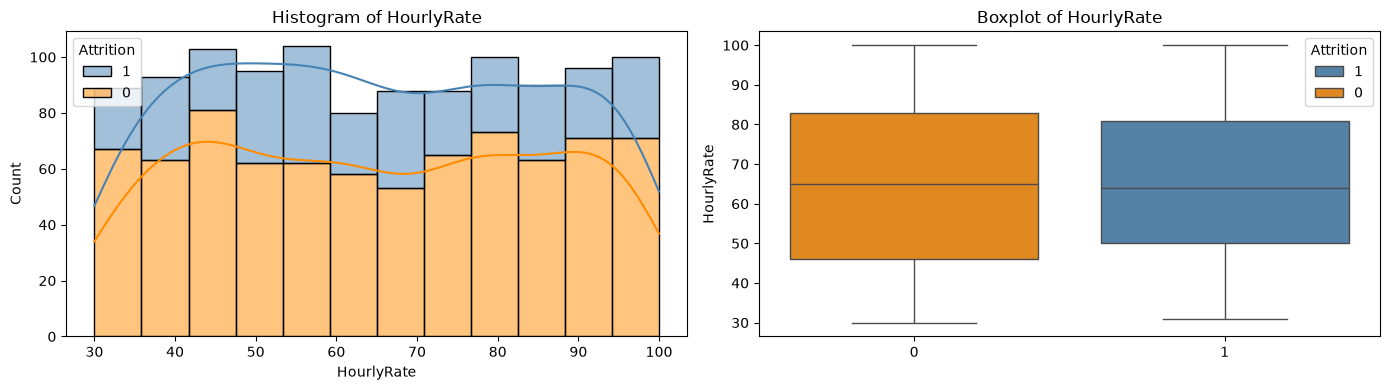

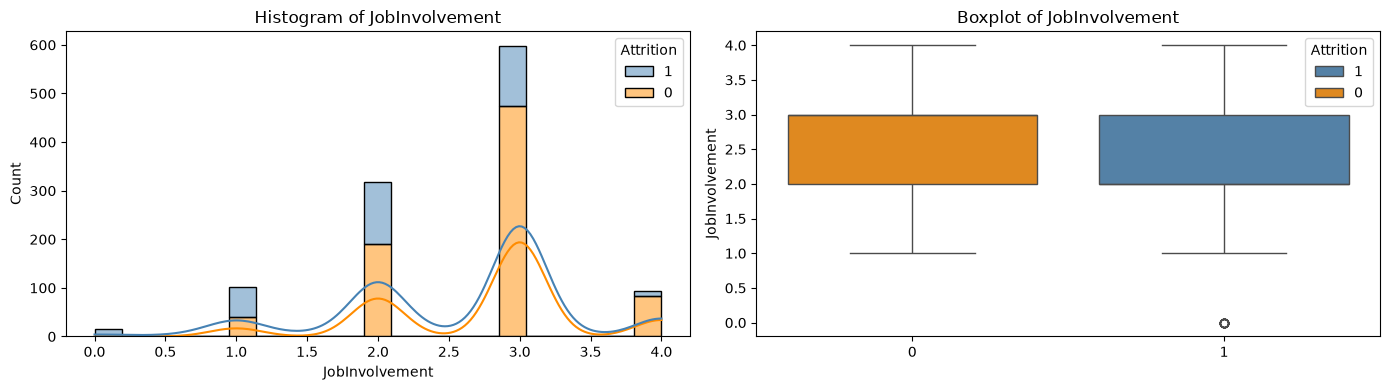

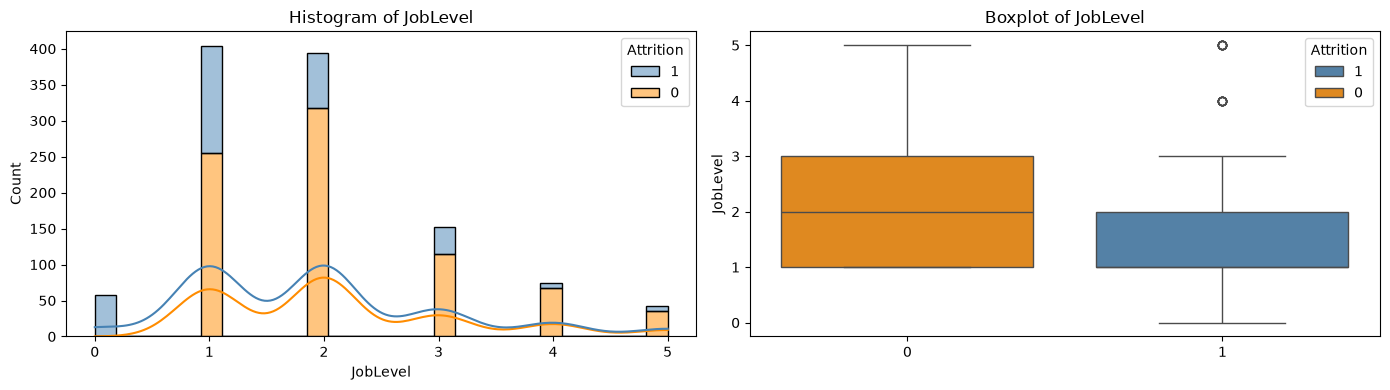

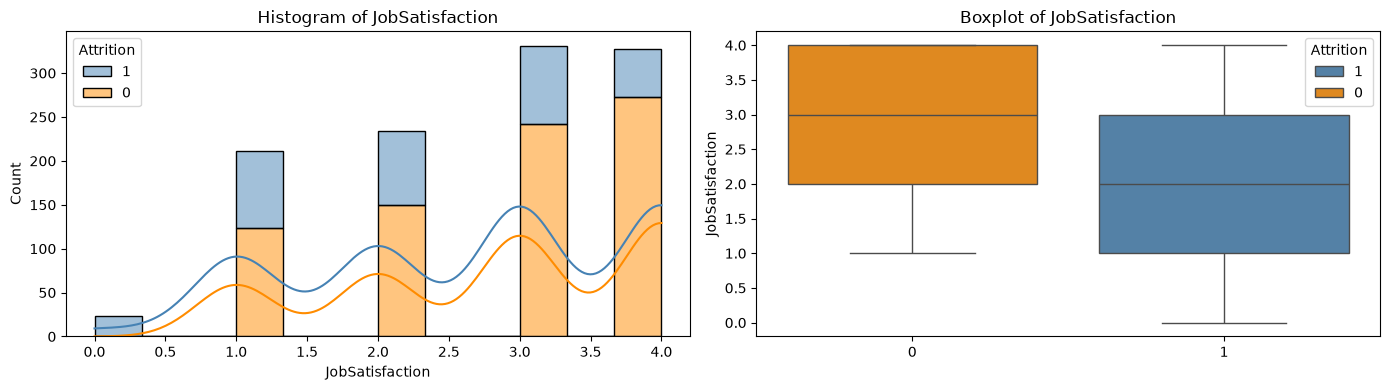

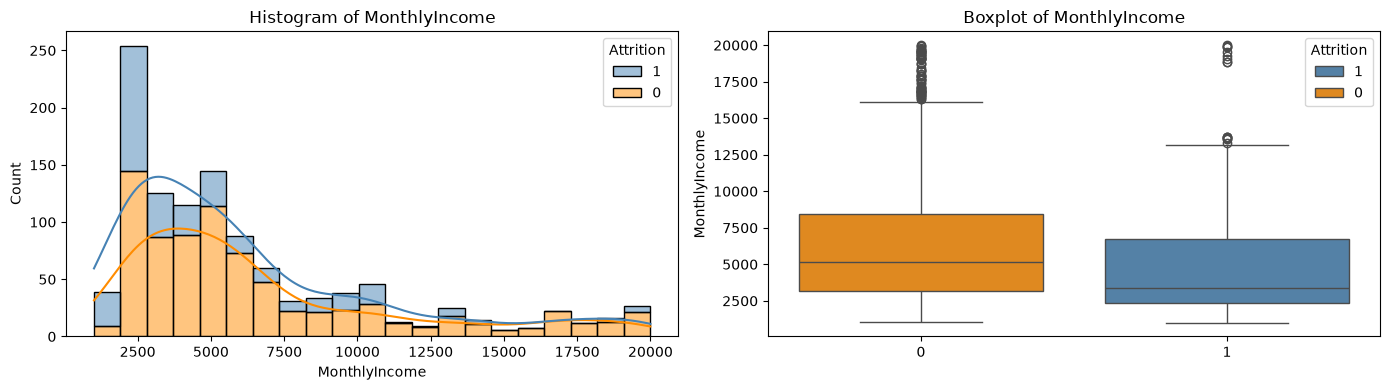

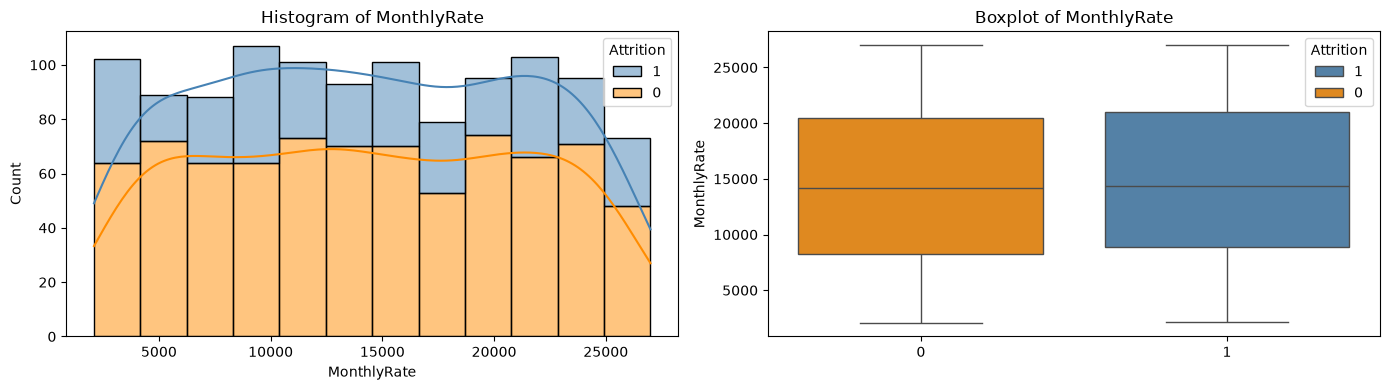

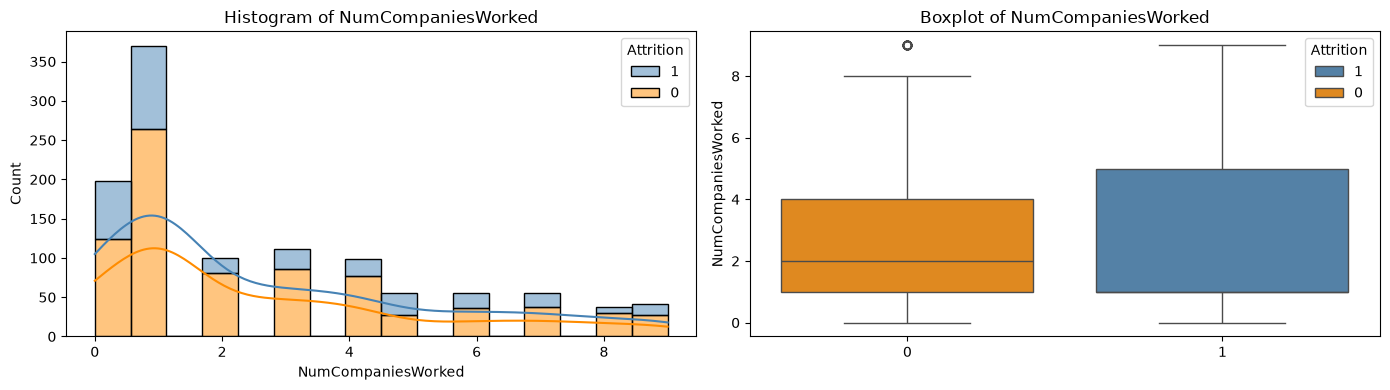

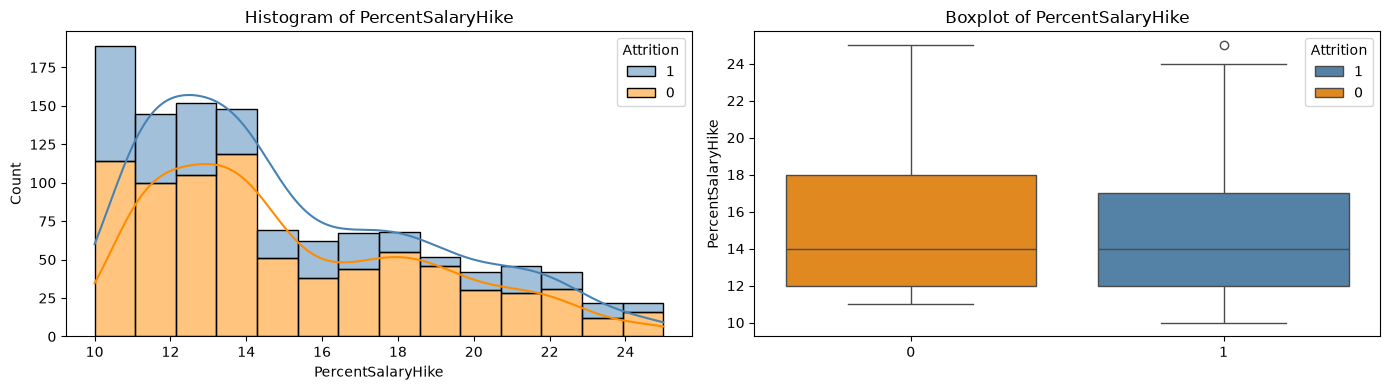

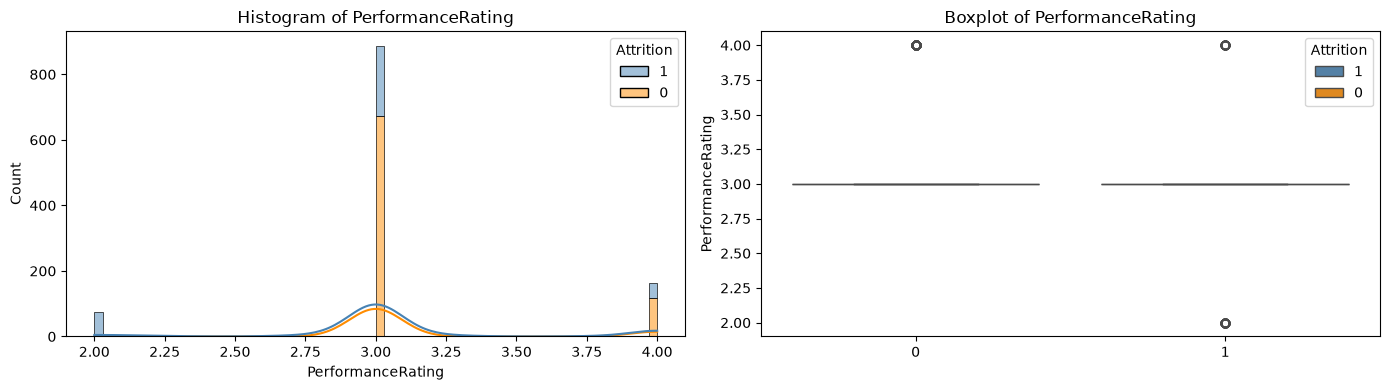

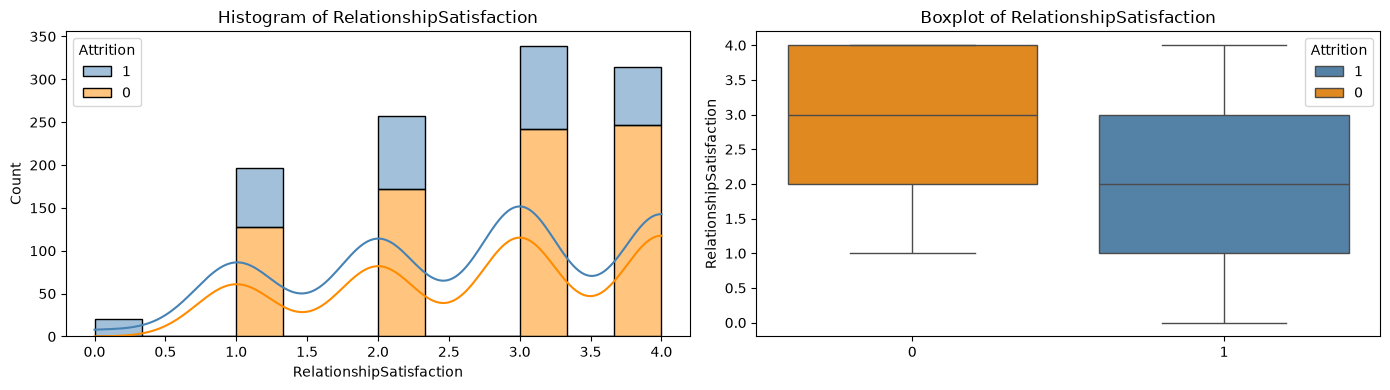

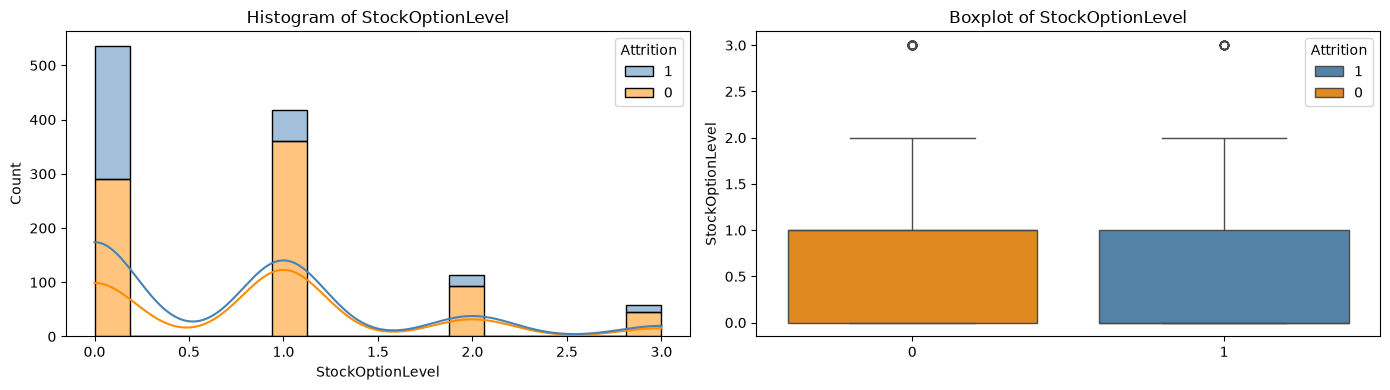

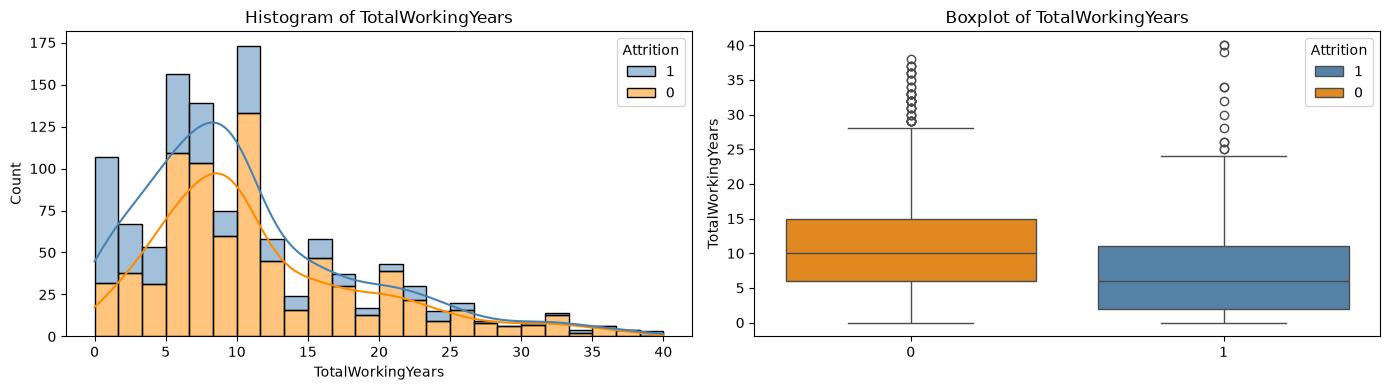

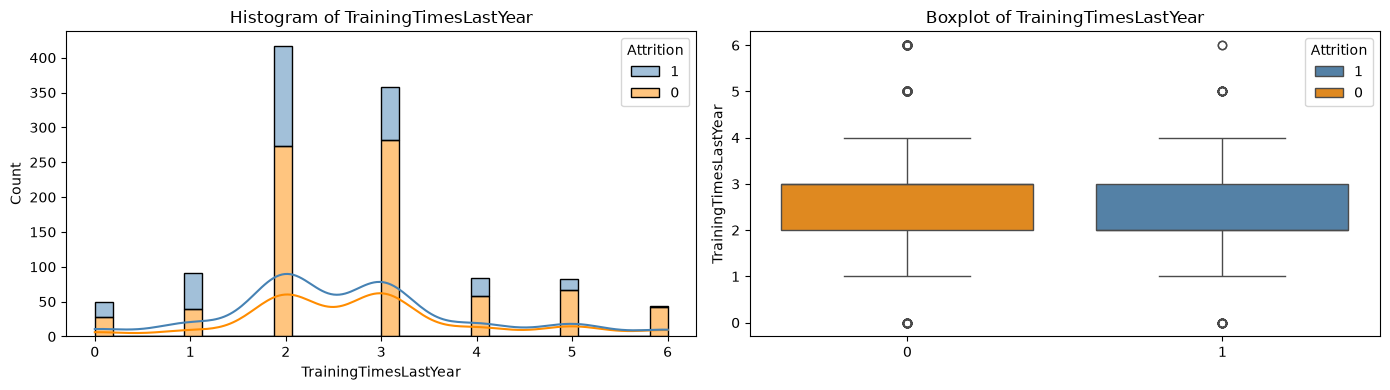

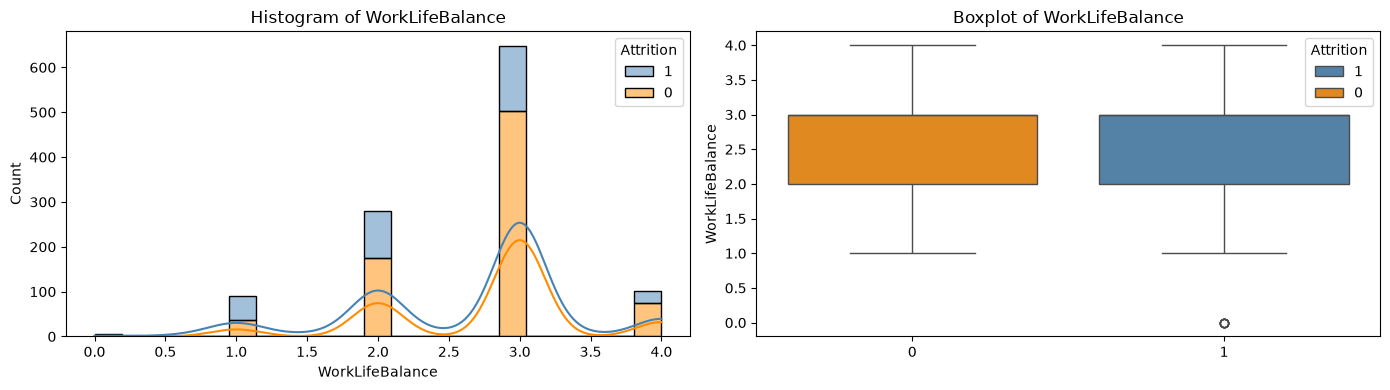

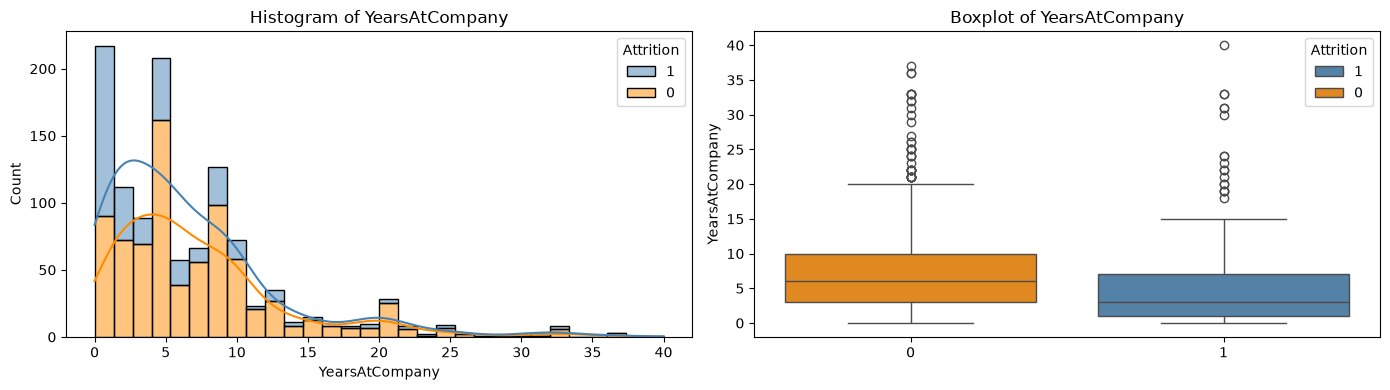

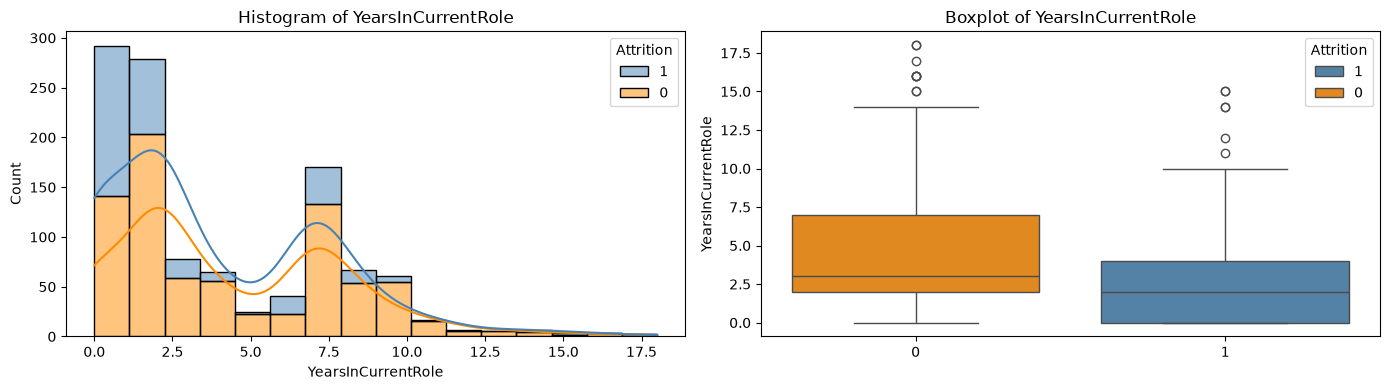

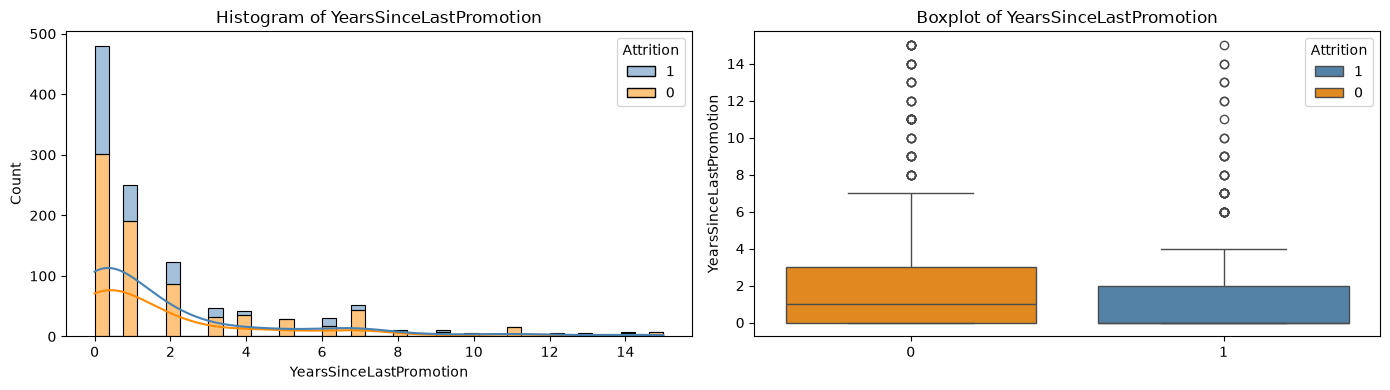

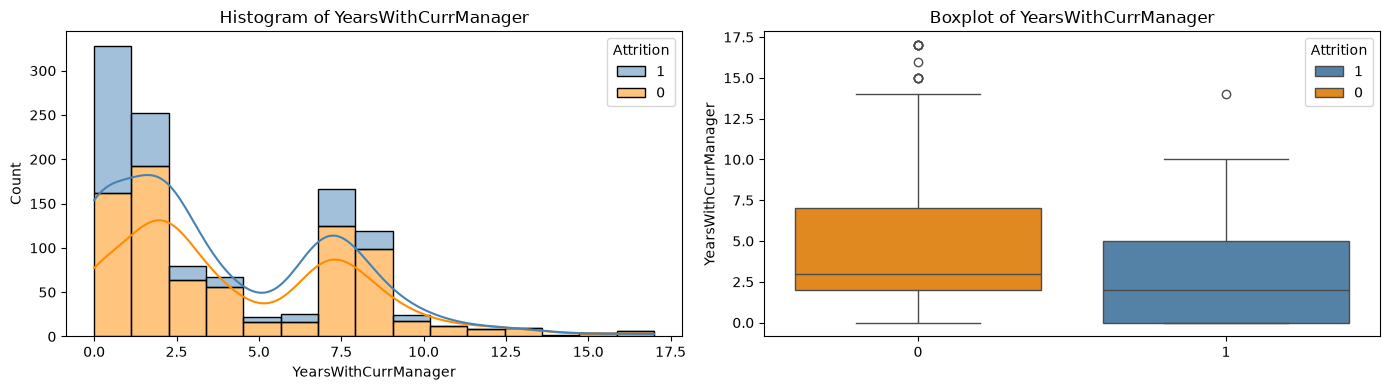

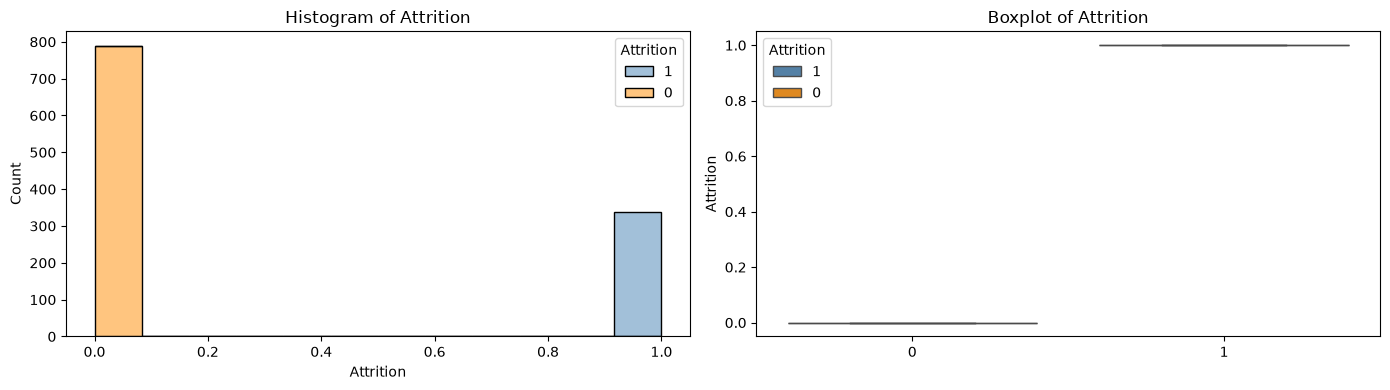

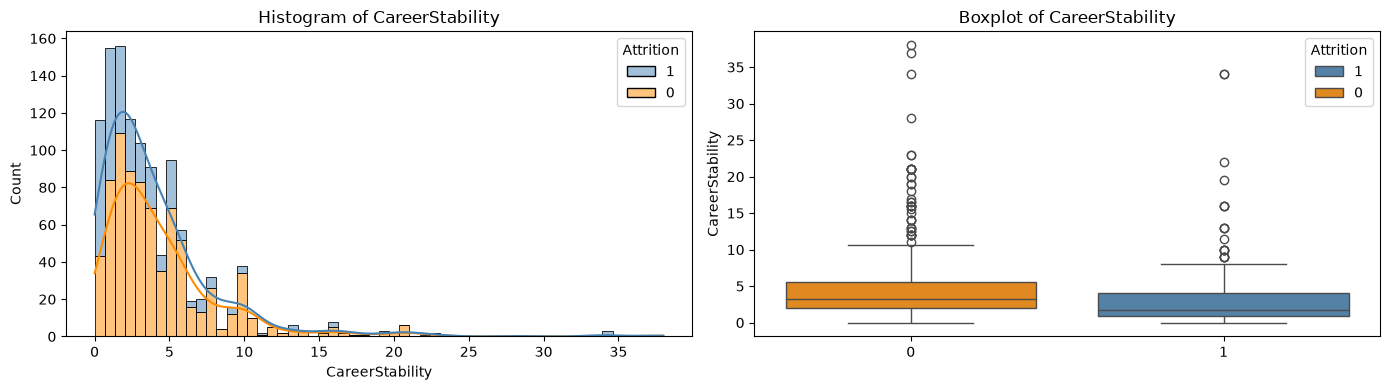

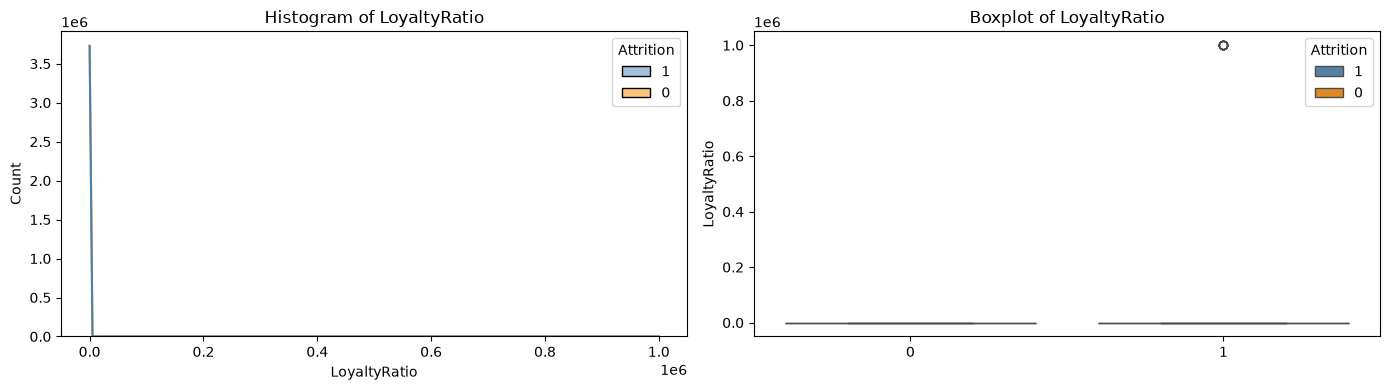

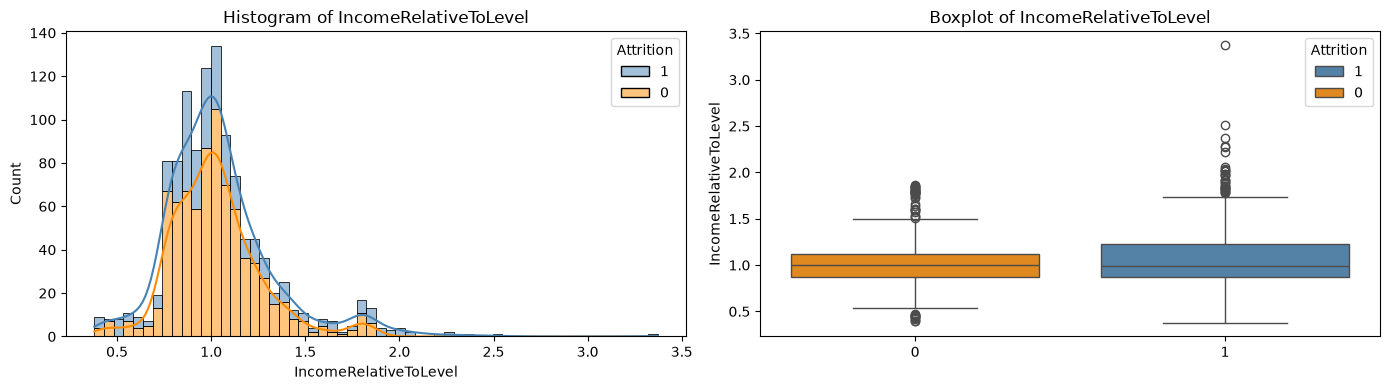

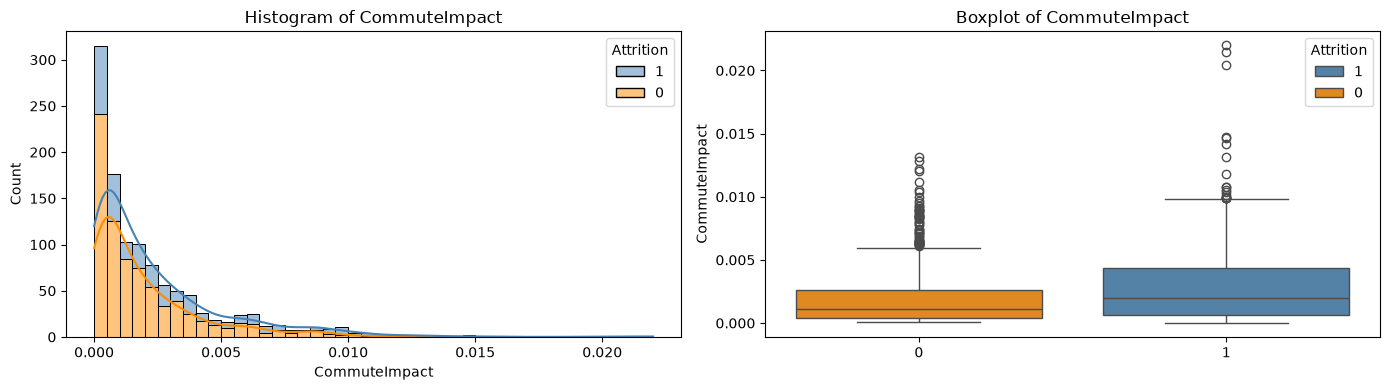

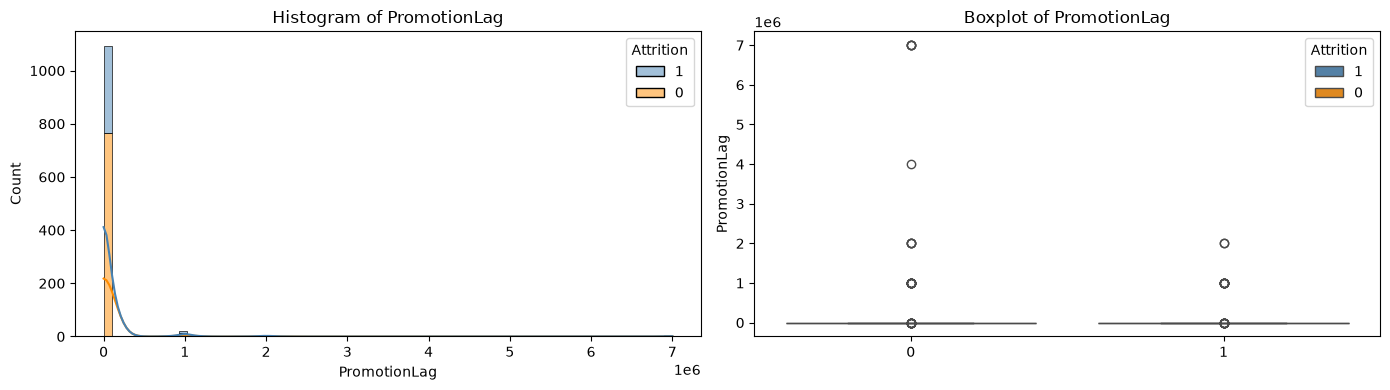

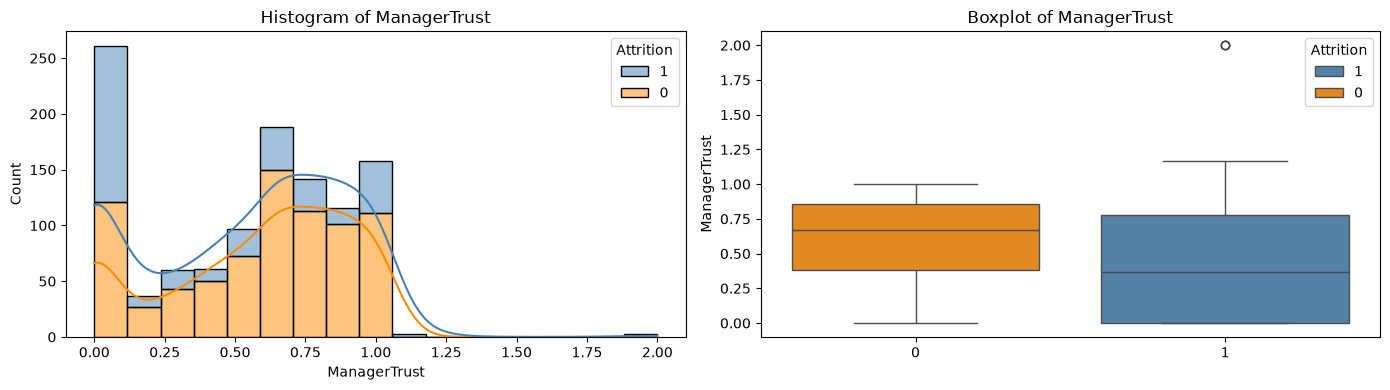

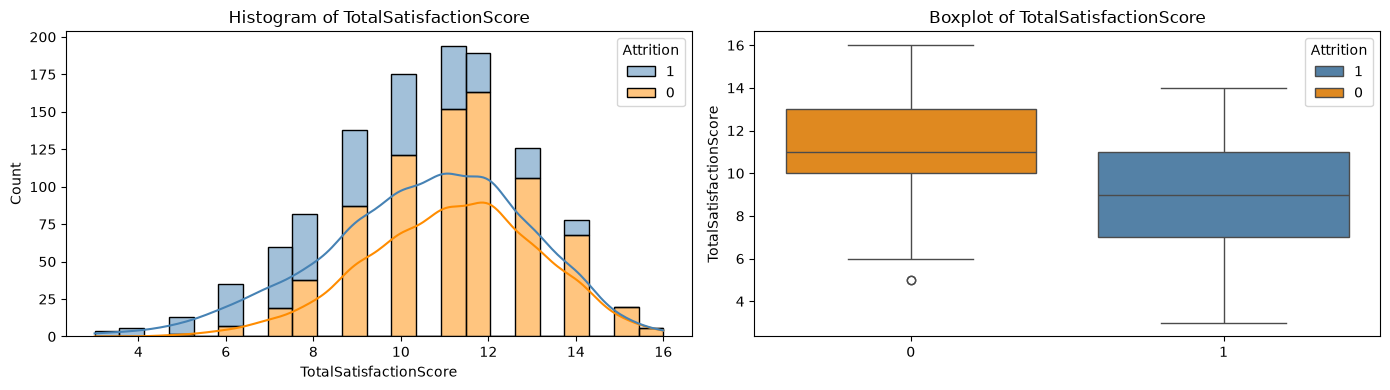

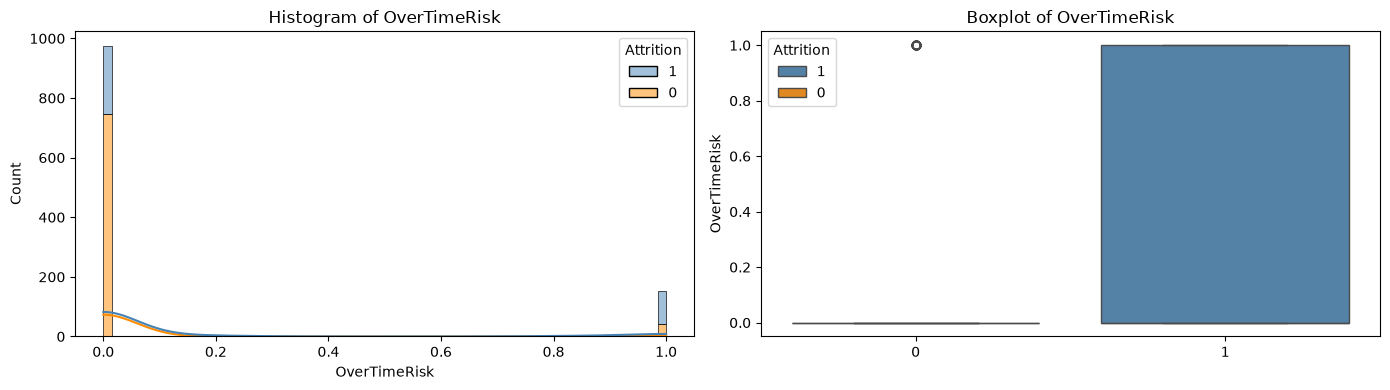

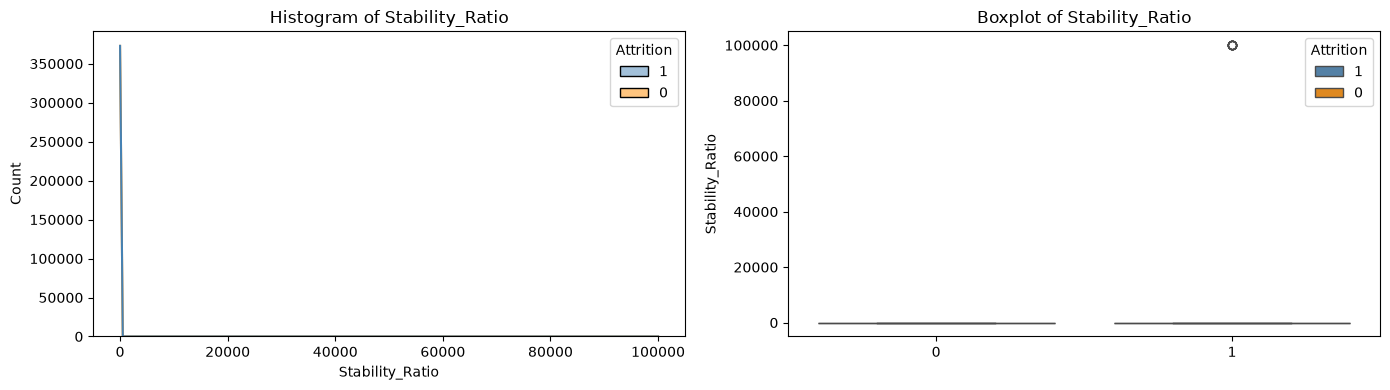

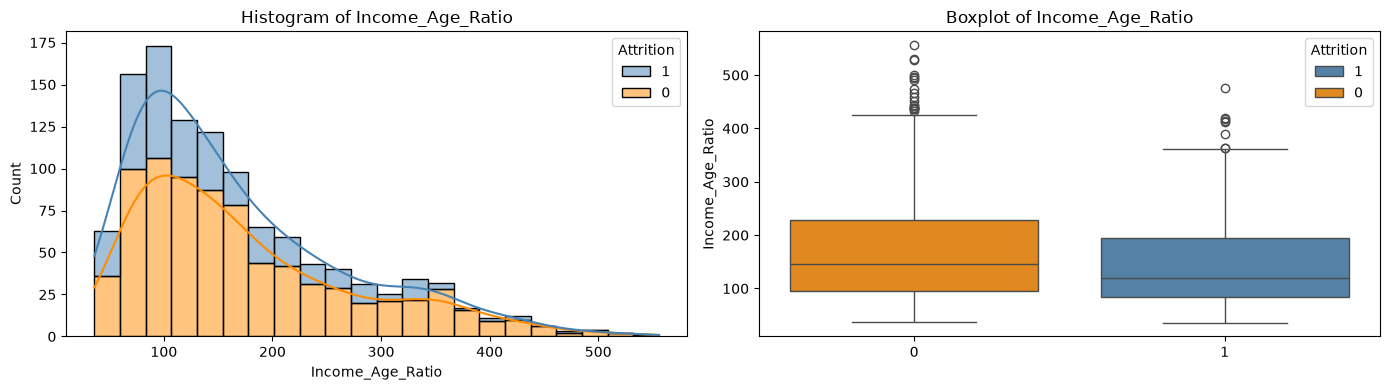

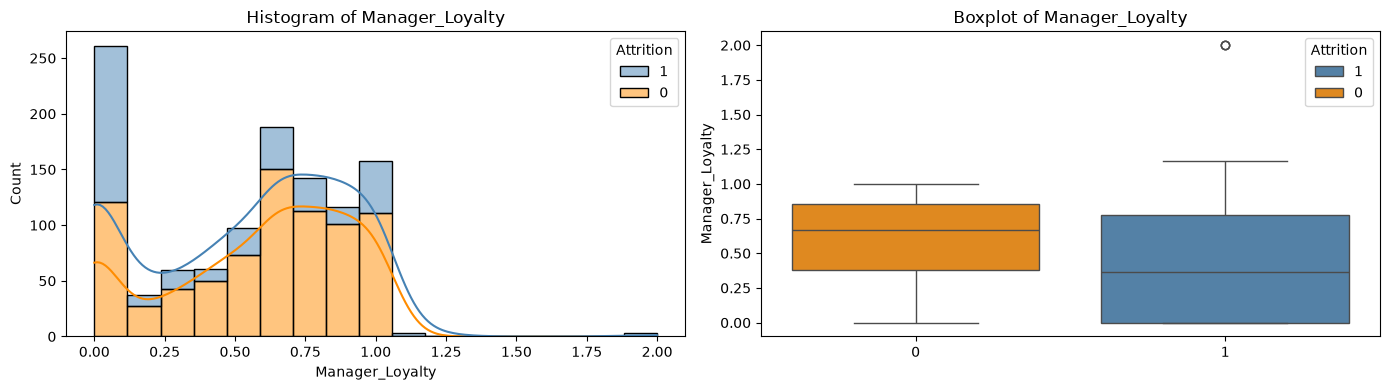

In [15]:
# Graphs

# Para cada atributo numérico: histograma empilhado por Attrition (com KDE)
# à esquerda e boxplot por Attrition à direita, no mesmo padrão de referência.
hue_order = [1, 0]                       # 1 = saiu, 0 = ficou
palette = {1: "steelblue", 0: "darkorange"}


for col in train_num_attributes:
    # KDE exige variância > 0. Colunas constantes (ex.: EmployeeCount,
    # StandardHours) quebrariam o gaussian_kde, então desligamos a curva.
    has_variance = df_train[col].nunique(dropna=True) > 1

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Esquerda: histograma empilhado por Attrition com curva KDE.
    sns.histplot(
        data=df_train,
        x=col,
        hue="Attrition",
        hue_order=hue_order,
        palette=palette,
        multiple="stack",
        kde=has_variance,
        ax=axes[0],
    )
    axes[0].set_title(f"Histogram of {col}")

    # Direita: boxplot por Attrition.
    sns.boxplot(
        data=df_train,
        x="Attrition",
        y=col,
        hue="Attrition",
        hue_order=hue_order,
        palette=palette,
        legend=True,
        ax=axes[1],
    )
    axes[1].set_title(f"Boxplot of {col}")
    axes[1].set_xlabel("")

    plt.tight_layout()
    plt.show()


#### 6.1.1.1 Num Stats (KS + Overlap + ROC AUC)

In [16]:
# ================================================
# Univariate Analysis: Separation + Outliers
# ================================================

y = LabelEncoder().fit_transform(df_train['Attrition'])   # No=0, Yes=1
num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()

results = []

for col in num_cols:
    series    = df_train[col].dropna()
    group_no  = df_train.loc[df_train['Attrition'] == 0,  col].dropna()
    group_yes = df_train.loc[df_train['Attrition'] == 1, col].dropna()

    # --- 1. Distribuição ---
    mean_no,  std_no  = group_no.mean(),  group_no.std()
    mean_yes, std_yes = group_yes.mean(), group_yes.std()

    # --- 2. Separação entre classes ---
    # KS Statistic
    ks_stat, ks_p = stats.ks_2samp(group_no, group_yes)

    # AUC Univariado
    X_col = df_train[[col]].fillna(df_train[col].median())
    try:
        model = LogisticRegression(max_iter=500).fit(X_col, y)
        auc   = roc_auc_score(y, model.predict_proba(X_col)[:, 1])
        auc   = max(auc, 1 - auc)   # garante AUC >= 0.5
    except Exception:
        auc = np.nan

    # Overlap Coefficient via KDE
    try:
        kde_no  = gaussian_kde(group_no)
        kde_yes = gaussian_kde(group_yes)
        x_range = np.linspace(series.min(), series.max(), 500)
        overlap = float(np.trapezoid(np.minimum(kde_no(x_range), kde_yes(x_range)), x_range))
    except Exception:
        overlap = np.nan

    # --- 3. Outliers (IQR method) ---
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR     = Q3 - Q1
    n_outliers = int(((series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)).sum())
    pct_outliers = n_outliers / len(series) * 100

    results.append({
        'Feature'        : col,
        'Mean (No)'      : round(mean_no, 2),
        'Mean (Yes)'     : round(mean_yes, 2),
        'Std (No)'       : round(std_no, 2),
        'Std (Yes)'      : round(std_yes, 2),
        'KS Stat'        : round(ks_stat, 4),
        'KS p-value'     : round(ks_p, 4),
        'AUC Univariado' : round(auc, 4),
        'Overlap Coef.'  : round(overlap, 4),
        'N Outliers'     : n_outliers,
        '% Outliers'     : round(pct_outliers, 2),
    })

df_train_analysis = pd.DataFrame(results).sort_values('AUC Univariado', ascending=False)

# --- Classificação automática por poder discriminativo ---
def classify(row):
    if row['AUC Univariado'] >= 0.65:
        return '🟢 Alta'
    elif row['AUC Univariado'] >= 0.55:
        return '🟡 Média'
    else:
        return '🔴 Baixa'

df_train_analysis['Discriminação'] = df_train_analysis.apply(classify, axis=1)

print("=" * 80)
print("UNIVARIATE ANALYSIS SUMMARY")
print("=" * 80)
df_train_analysis


UNIVARIATE ANALYSIS SUMMARY


,Feature,Mean (No),Mean (Yes),Std (No),Std (Yes),KS Stat,KS p-value,AUC Univariado,Overlap Coef.,N Outliers,% Outliers,Discriminação
24,Attrition,0.00,1.00,0.00,0.00,1.0000,0.0000,1.0000,NaN,0,0.00,🟢 Alta
31,TotalSatisfactionScore,11.20,9.11,1.95,2.41,0.3619,0.0000,0.7438,0.6459,10,0.89,🟢 Alta
7,JobInvolvement,2.76,2.16,0.71,0.91,0.3054,0.0000,0.6810,0.6397,15,1.33,🟢 Alta
8,JobLevel,2.12,1.45,1.09,1.12,0.2910,0.0000,0.6753,0.7145,118,10.48,🟢 Alta
25,CareerStability,4.51,2.94,4.32,3.91,0.2831,0.0000,0.6729,0.7293,59,5.24,🟢 Alta
16,StockOptionLevel,0.86,0.41,0.83,0.78,0.3624,0.0000,0.6722,0.4433,59,5.24,🟢 Alta
20,YearsAtCompany,7.34,4.85,6.21,6.13,0.2902,0.0000,0.6713,0.7086,68,6.04,🟢 Alta
23,YearsWithCurrManager,4.36,2.55,3.60,3.06,0.2873,0.0000,0.6678,0.6693,5,0.44,🟢 Alta
21,YearsInCurrentRole,4.45,2.66,3.57,3.10,0.2694,0.0000,0.6657,0.6833,3,0.27,🟢 Alta
17,TotalWorkingYears,11.67,8.07,7.72,7.54,0.2622,0.0000,0.6591,0.7416,51,4.53,🟢 Alta


In [17]:
# Lista das variáveis que tem Baixa discriminação
low_discrimination_train_num_univars = df_train_analysis[df_train_analysis['Discriminação'] == '🔴 Baixa']['Feature'].tolist()

### 6.1.2 Cat Attributes

In [18]:
# Atributos categóricos (object/str), incluindo a variável alvo 'Attrition'.
train_cat_attributes = df_train.select_dtypes(include=["object", "string"]).columns.tolist()

df_train[train_cat_attributes].describe().T

,count,unique,top,freq
BusinessTravel,1126,3,Travel_Rarely,794
Department,1126,3,Research & Development,693
EducationField,1126,6,Life Sciences,446
Gender,1126,2,Male,686
JobRole,1126,9,Sales Executive,266
MaritalStatus,1126,3,Married,509
Over18,1126,1,Y,1126
OverTime,1126,2,No,762
AgeGroup,1126,3,adult,810


- Over18 sem relevancia

#### 6.1.2.1 Cat Stats (Chi squared-Kramer-v and AUC)

In [19]:
from scipy.stats import chi2_contingency

# --- Cramér's V ---
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# --- Análise categórica ---
y = LabelEncoder().fit_transform(df_train['Attrition'])
cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != 'Attrition']

y = LabelEncoder().fit_transform(df_train['Attrition'])  # No=0, Yes=1
cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != 'Attrition']

results_cat = []

for col in cat_cols:
    series = df_train[col].fillna('Missing')

    # --- 1. Chi-Square ---
    contingency = pd.crosstab(series, df_train['Attrition'])
    chi2, p_value, _, _ = chi2_contingency(contingency)

    # --- 2. Cramér's V (Effect Size) ---
    cv = cramers_v(series, df_train['Attrition'])

    # --- 3. AUC Univariado ---
    X_enc = LabelEncoder().fit_transform(series).reshape(-1, 1)
    try:
        model = LogisticRegression(max_iter=300).fit(X_enc, y)
        auc   = roc_auc_score(y, model.predict_proba(X_enc)[:, 1])
        auc   = max(auc, 1 - auc)
    except Exception:
        auc = np.nan

    # --- 4. Taxa de Attrition por categoria ---
    attrition_rate = (
        df_train.groupby(col)['Attrition']
        .apply(lambda x: (x == 'Yes').mean())
        .to_dict()
    )

    results_cat.append({
        'Feature'            : col,
        'Chi2'               : round(chi2, 2),
        'p-value'            : round(p_value, 4),
        "Cramér's V"         : round(cv, 4),
        'AUC Univariado'     : round(auc, 4),
        'Taxa Attrition/Cat' : {k: f"{v:.0%}" for k, v in attrition_rate.items()},
    })

def classify_cat(row):
    if row['AUC Univariado'] >= 0.65:  return '🟢 Alta'
    elif row['AUC Univariado'] >= 0.55: return '🟡 Média'
    else:                               return '🔴 Baixa'

df_train_cat_analysis = pd.DataFrame(results_cat).sort_values('AUC Univariado', ascending=False)
df_train_cat_analysis['Discriminação'] = df_train_cat_analysis.apply(classify_cat, axis=1)

print("=" * 70)
print("CATEGORICAL UNIVARIATE ANALYSIS")
print("=" * 70)
df_train_cat_analysis[['Feature', 'Chi2', 'p-value', "Cramér's V", 'AUC Univariado', 'Discriminação']]


CATEGORICAL UNIVARIATE ANALYSIS


,Feature,Chi2,p-value,Cramér's V,AUC Univariado,Discriminação
7,OverTime,125.62,0.0000,0.3328,0.6716,🟢 Alta
5,MaritalStatus,72.41,0.0000,0.2502,0.6376,🟡 Média
4,JobRole,92.74,0.0000,0.2744,0.5728,🟡 Média
1,Department,21.24,0.0000,0.1308,0.5513,🟡 Média
8,AgeGroup,46.87,0.0000,0.1997,0.5510,🟡 Média
3,Gender,2.23,0.1357,0.0330,0.5247,🔴 Baixa
0,BusinessTravel,30.40,0.0000,0.1589,0.5208,🔴 Baixa
2,EducationField,21.98,0.0005,0.1228,0.5077,🔴 Baixa
6,Over18,0.00,1.0000,NaN,0.5000,🔴 Baixa


In [20]:
# Lista das variáveis categóricas que tem Baixa discriminação
low_discrimination_train_cat_univars = df_train_cat_analysis[df_train_cat_analysis['Discriminação'] == '🔴 Baixa']['Feature'].tolist()

## 6.2 Bivariate Analysis

### 6.2.1 Num attributes

In [21]:
col_target = 'Attrition'

# Funciona tanto se Attrition for 'Yes'/'No' quanto 0/1
if df_train[col_target].dtype == object:
    y_binary = (df_train[col_target] == 'Yes').astype(int)
else:
    y_binary = df_train[col_target].astype(int)

num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c != col_target]   # não analisa o alvo contra ele mesmo

def classify_cat(row):
    if row['AUC Univariado'] >= 0.65:
        return '🟢 Alta'
    elif row['AUC Univariado'] >= 0.55:
        return '🟡 Média'
    else:
        return '🔴 Baixa'

resultados = []
for col in num_cols:
    # pula colunas constantes (ex.: EmployeeCount, StandardHours)
    if df_train[col].nunique(dropna=True) <= 1:
        print(f"[skip] {col}: coluna constante.")
        continue

    g_no  = df_train.loc[y_binary == 0, col].dropna()
    g_yes = df_train.loc[y_binary == 1, col].dropna()

    # KS entre as duas distribuições
    ks_stat, ks_p = stats.ks_2samp(g_no, g_yes)

    # correlação ponto-biserial (numérica vs binária)
    r_pb, p_pb = pointbiserialr(y_binary, df_train[col].fillna(df_train[col].median()))

    # AUC de uma regressão logística univariada
    X_col = df_train[[col]].fillna(df_train[col].median())
    model = LogisticRegression(max_iter=500).fit(X_col, y_binary)
    auc = roc_auc_score(y_binary, model.predict_proba(X_col)[:, 1])
    auc = max(auc, 1 - auc)   # garante AUC >= 0.5 (direção não importa aqui)

    resultados.append({
        'Feature': col,
        'KS': ks_stat,
        'KS_p': ks_p,
        'r_pointbiserial': r_pb,
        'r_p': p_pb,
        'AUC Univariado': auc,
    })

df_train_bivariada = pd.DataFrame(resultados)

# aplica a classificação linha a linha
df_train_bivariada['Discriminação'] = df_train_bivariada.apply(classify_cat, axis=1)

df_train_bivariada = (
    df_train_bivariada
    .sort_values('AUC Univariado', ascending=False)
    .reset_index(drop=True)
)
df_train_bivariada


,Feature,KS,KS_p,r_pointbiserial,r_p,AUC Univariado,Discriminação
0,TotalSatisfactionScore,0.361924,4.748663e-28,-0.414594,5.284739e-48,0.743769,🟢 Alta
1,JobInvolvement,0.305363,5.720162e-20,-0.333055,1.425863e-30,0.680969,🟢 Alta
2,JobLevel,0.291049,3.724651e-18,-0.272372,1.326798e-20,0.675292,🟢 Alta
3,CareerStability,0.283084,3.457562e-17,-0.169098,1.135880e-08,0.672868,🟢 Alta
4,StockOptionLevel,0.362416,3.958531e-28,-0.245164,7.106346e-17,0.672163,🟢 Alta
5,YearsAtCompany,0.290226,4.695888e-18,-0.181961,7.723844e-10,0.671328,🟢 Alta
6,YearsWithCurrManager,0.287258,1.083388e-17,-0.233385,2.146780e-15,0.667844,🟢 Alta
7,YearsInCurrentRole,0.269364,1.383246e-15,-0.231159,4.005659e-15,0.665668,🟢 Alta
8,TotalWorkingYears,0.262162,8.879114e-15,-0.210016,1.087206e-12,0.659100,🟢 Alta
9,JobSatisfaction,0.228393,2.694224e-11,-0.261067,5.314711e-19,0.652116,🟢 Alta


In [22]:
# mais robusto: nao depende do emoji exato
low_discrimination_train_num_bivars = df_train_bivariada[
    df_train_bivariada['Discriminação'].str.contains('Baixa')
]['Feature'].tolist()


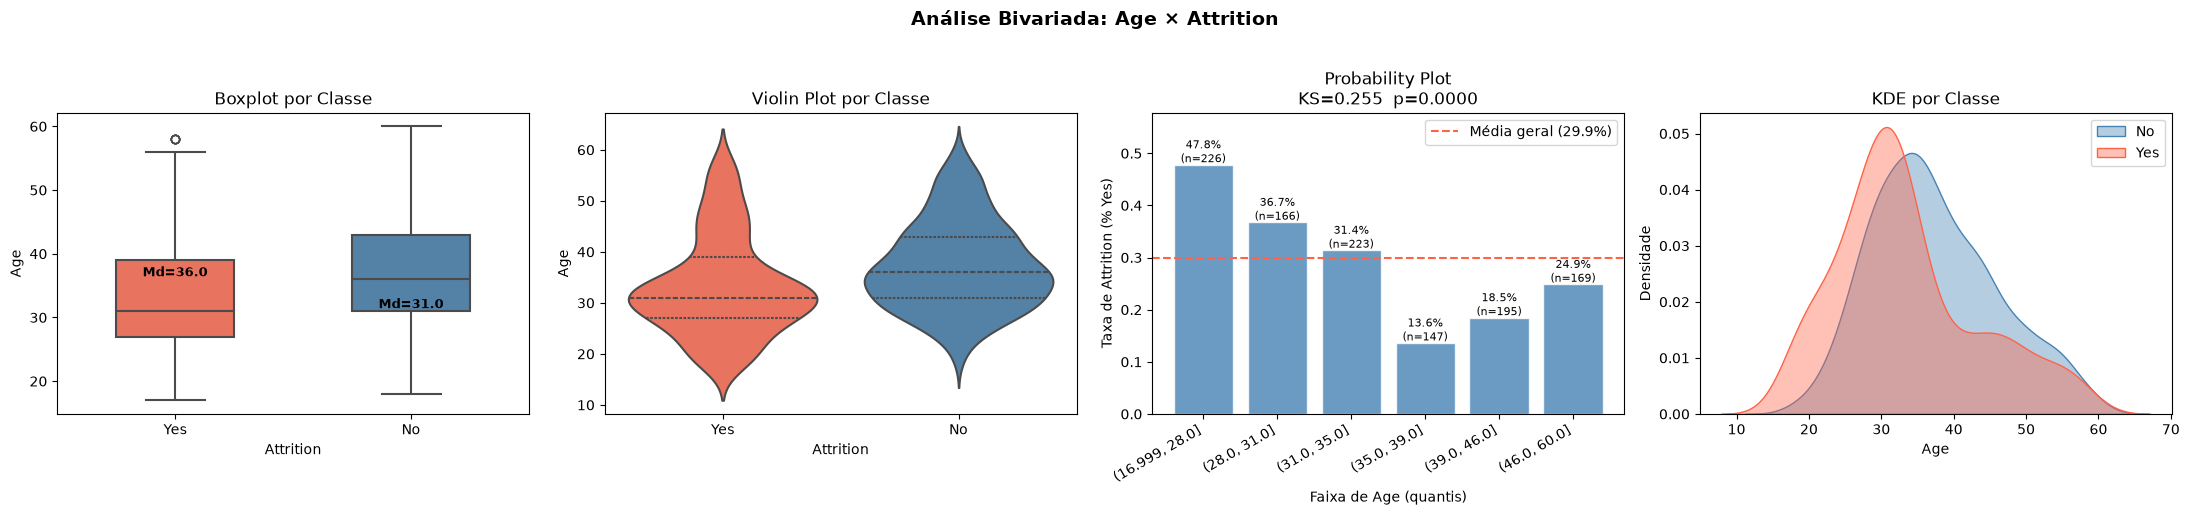

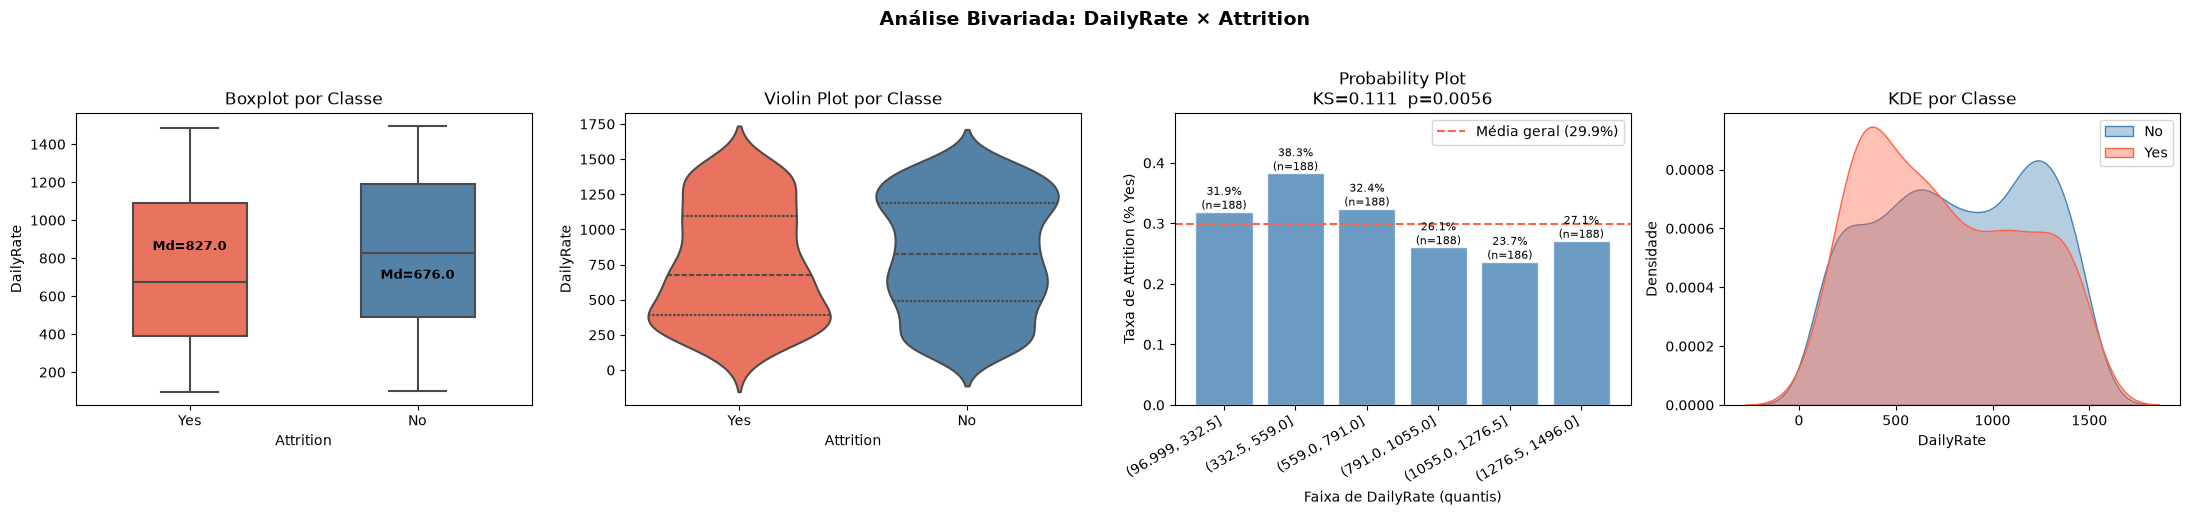

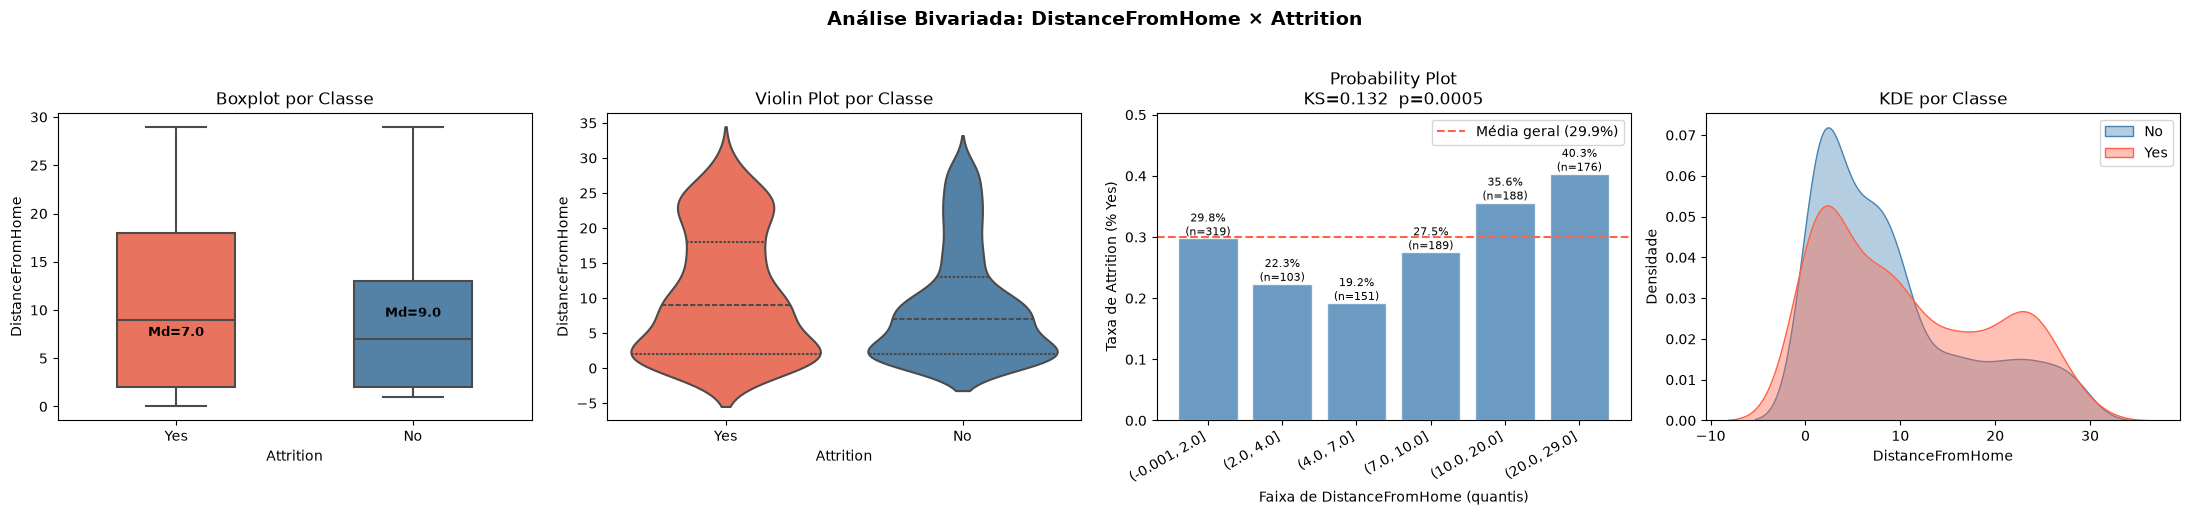

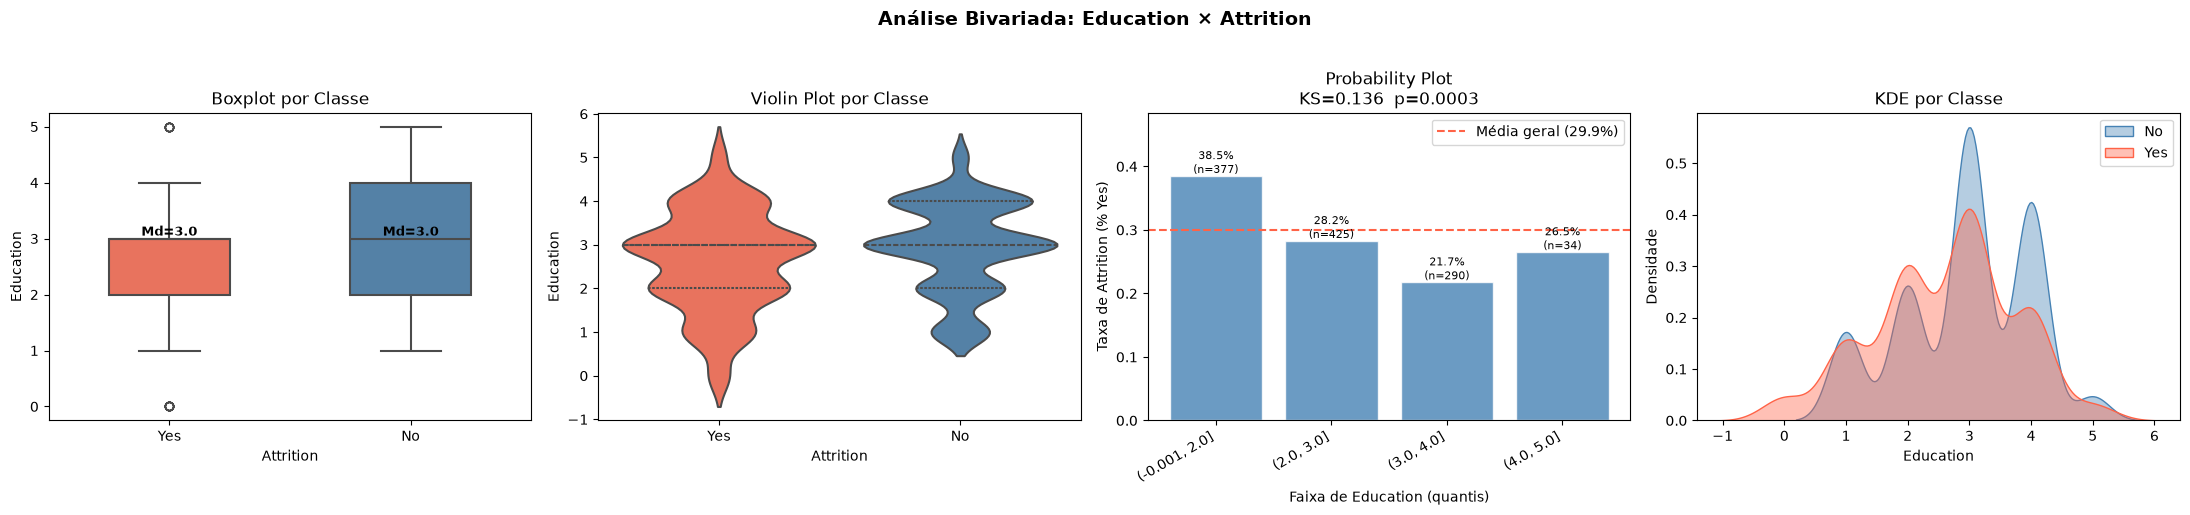

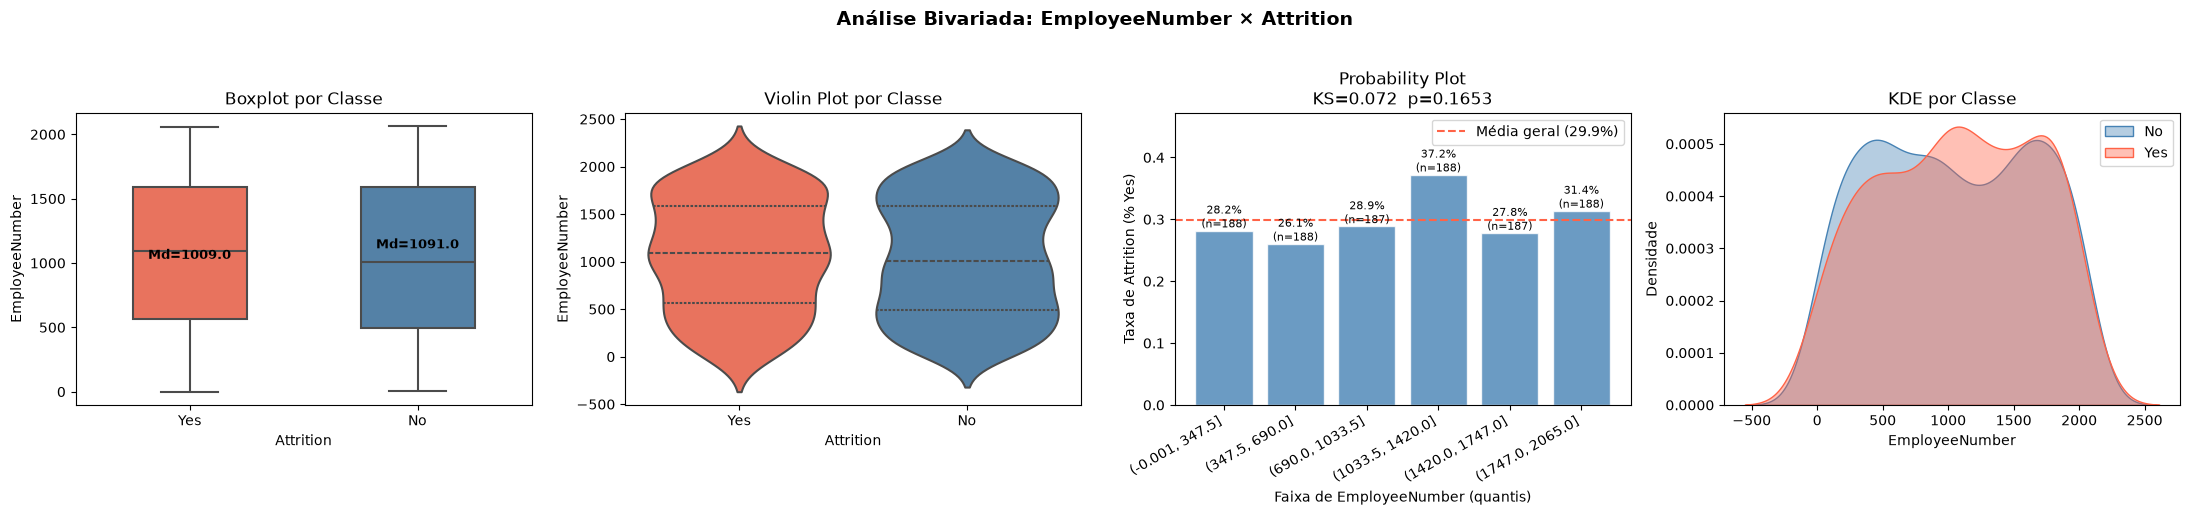

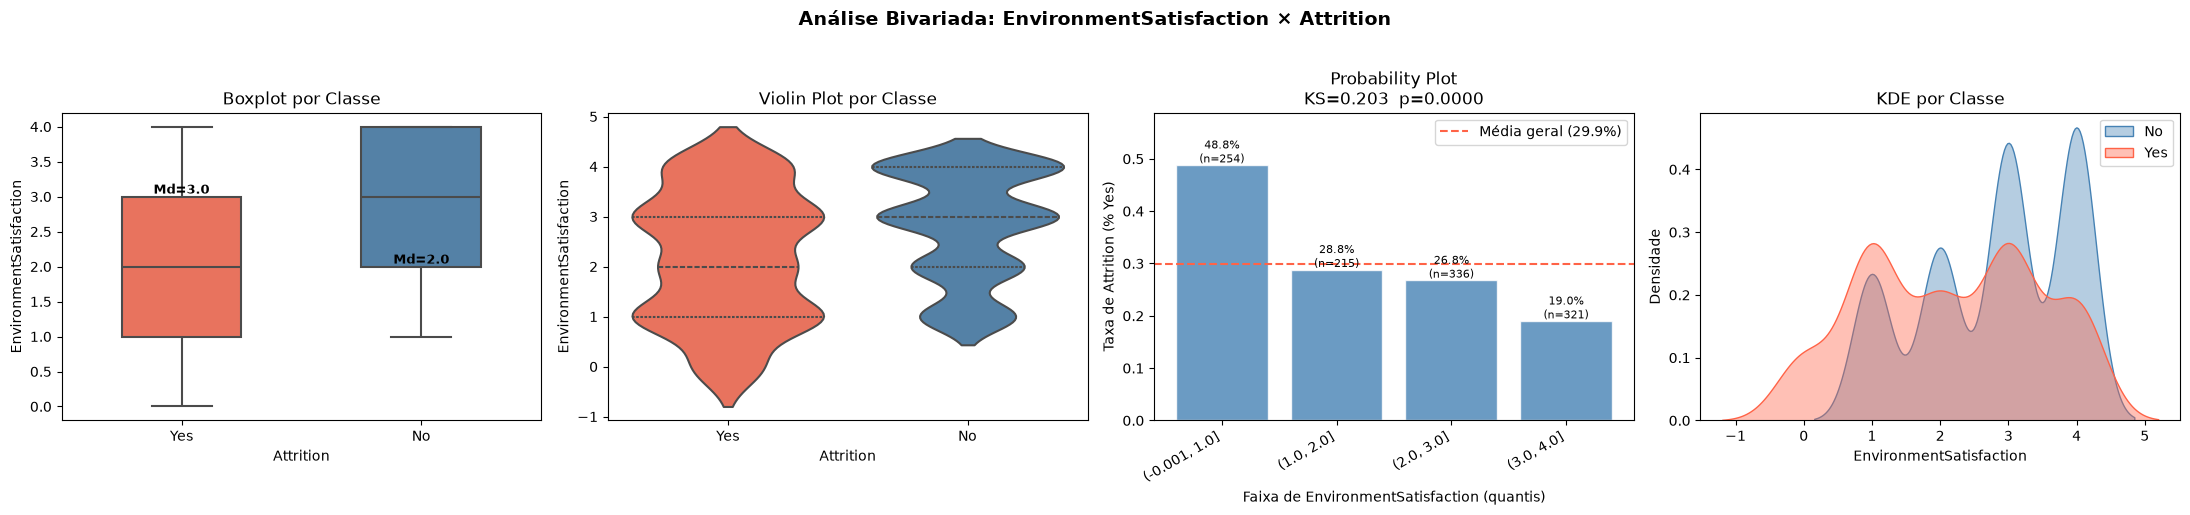

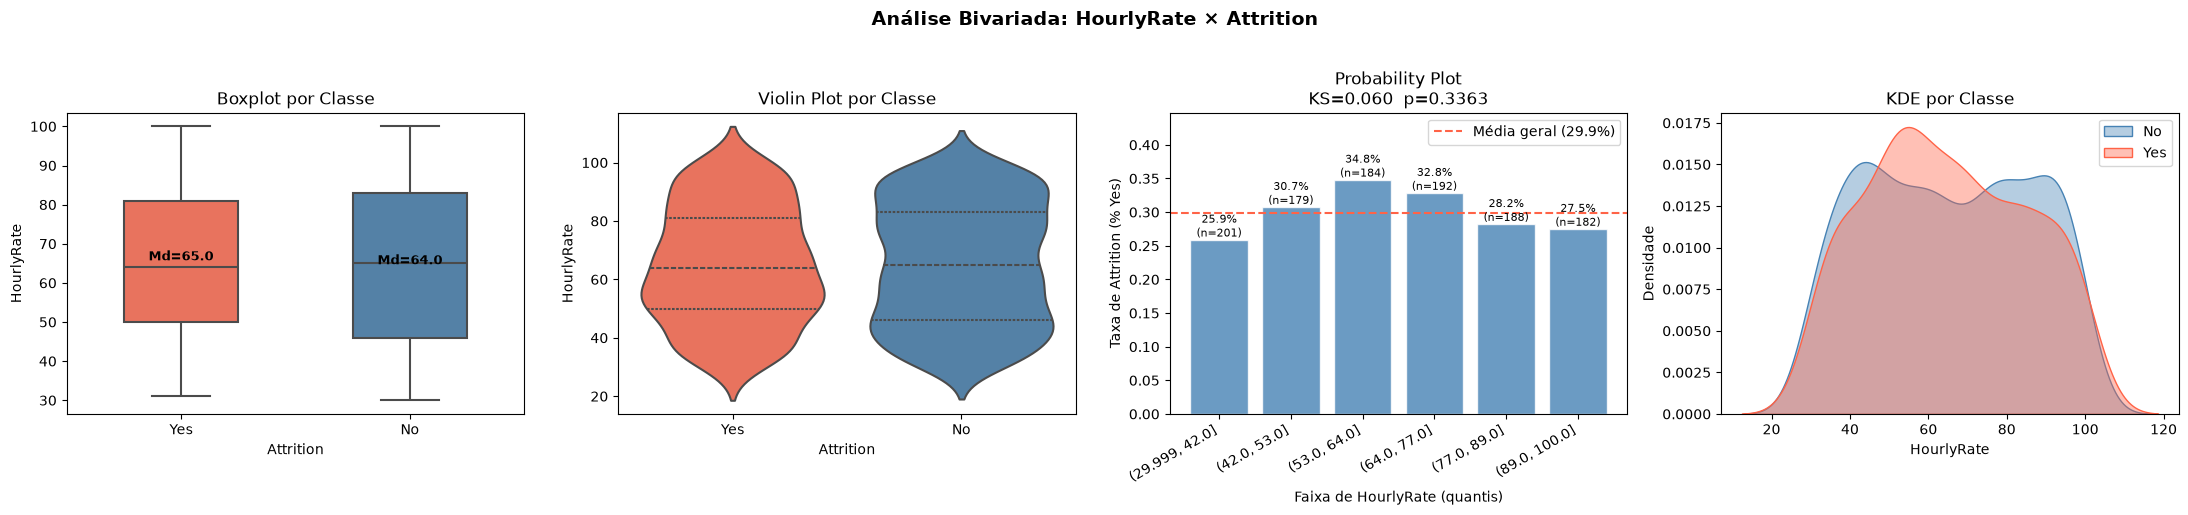

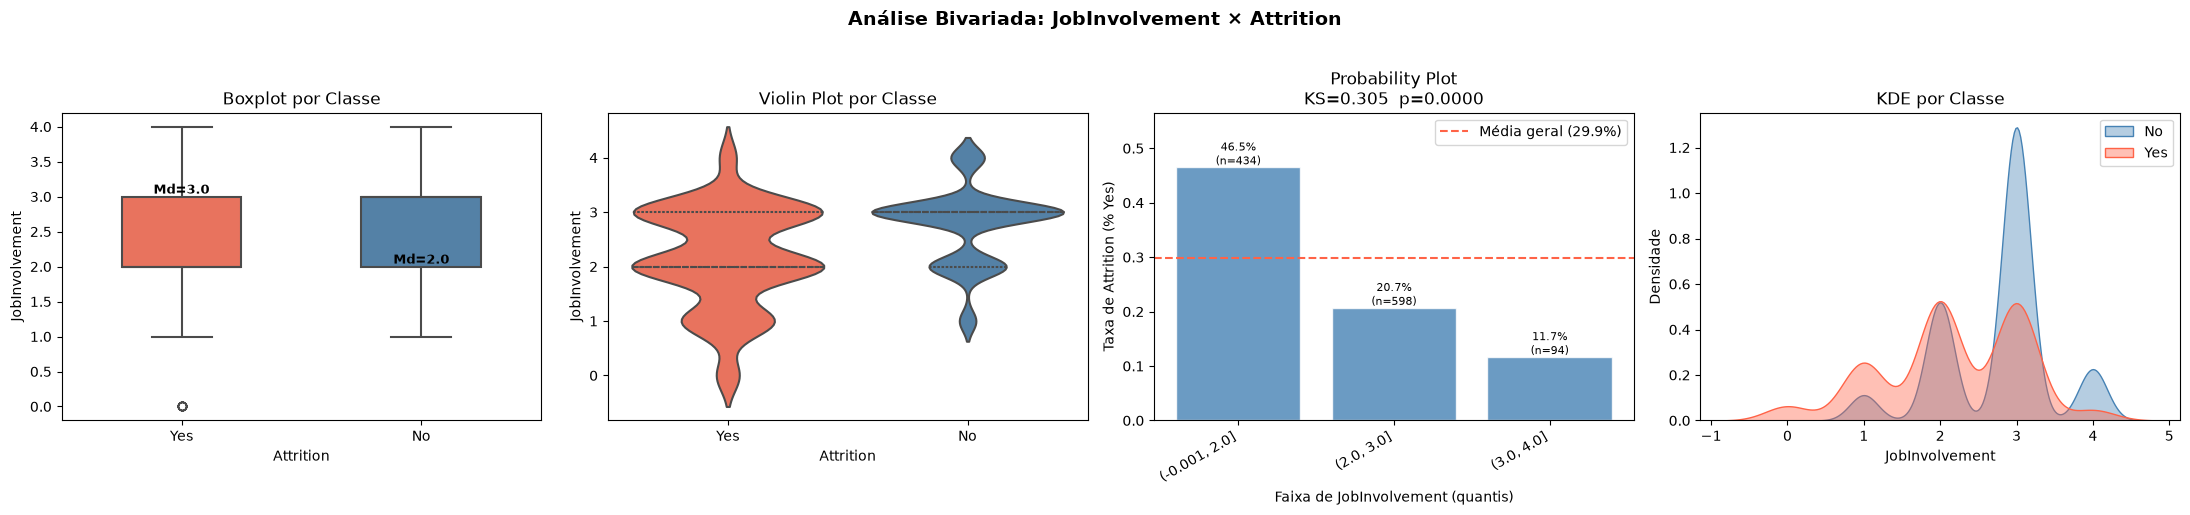

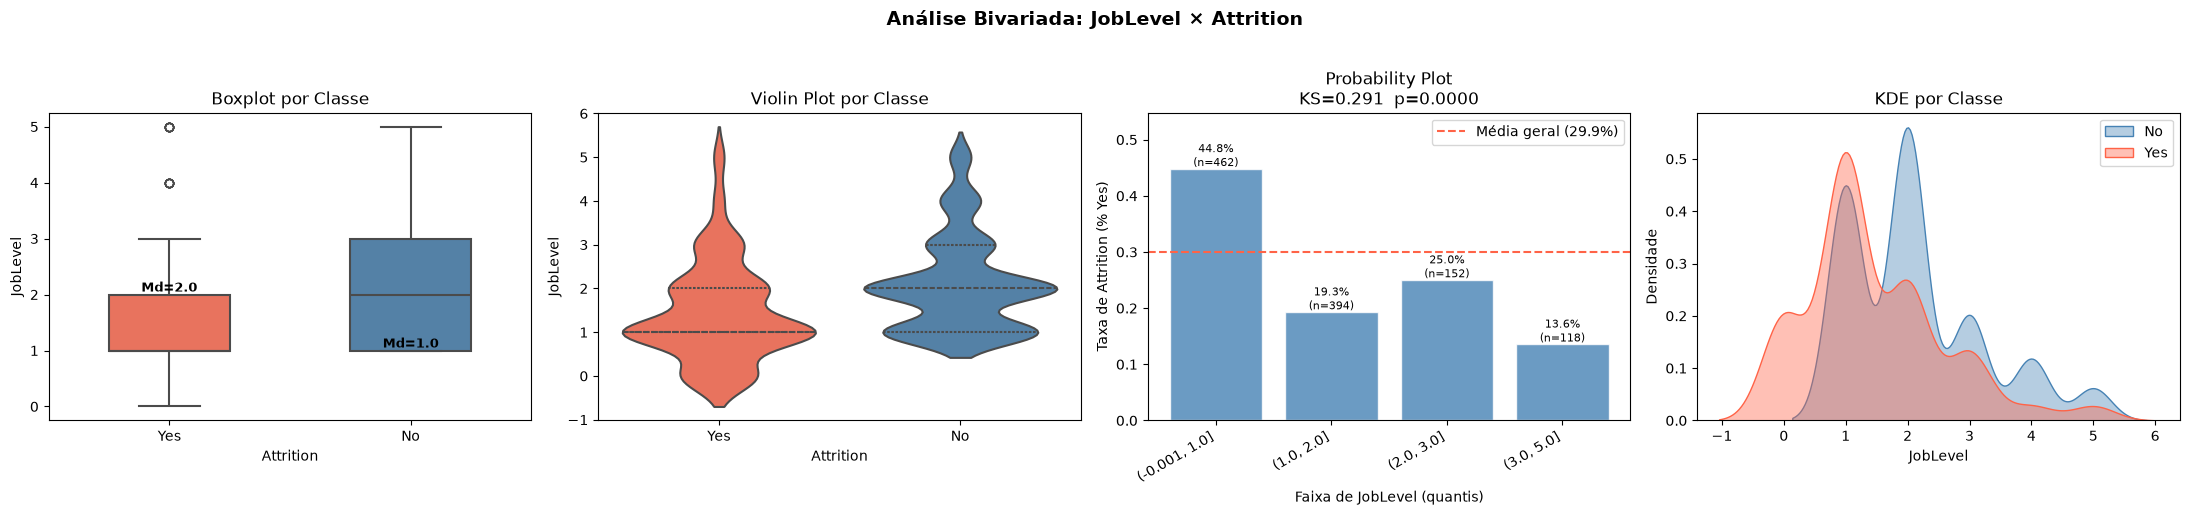

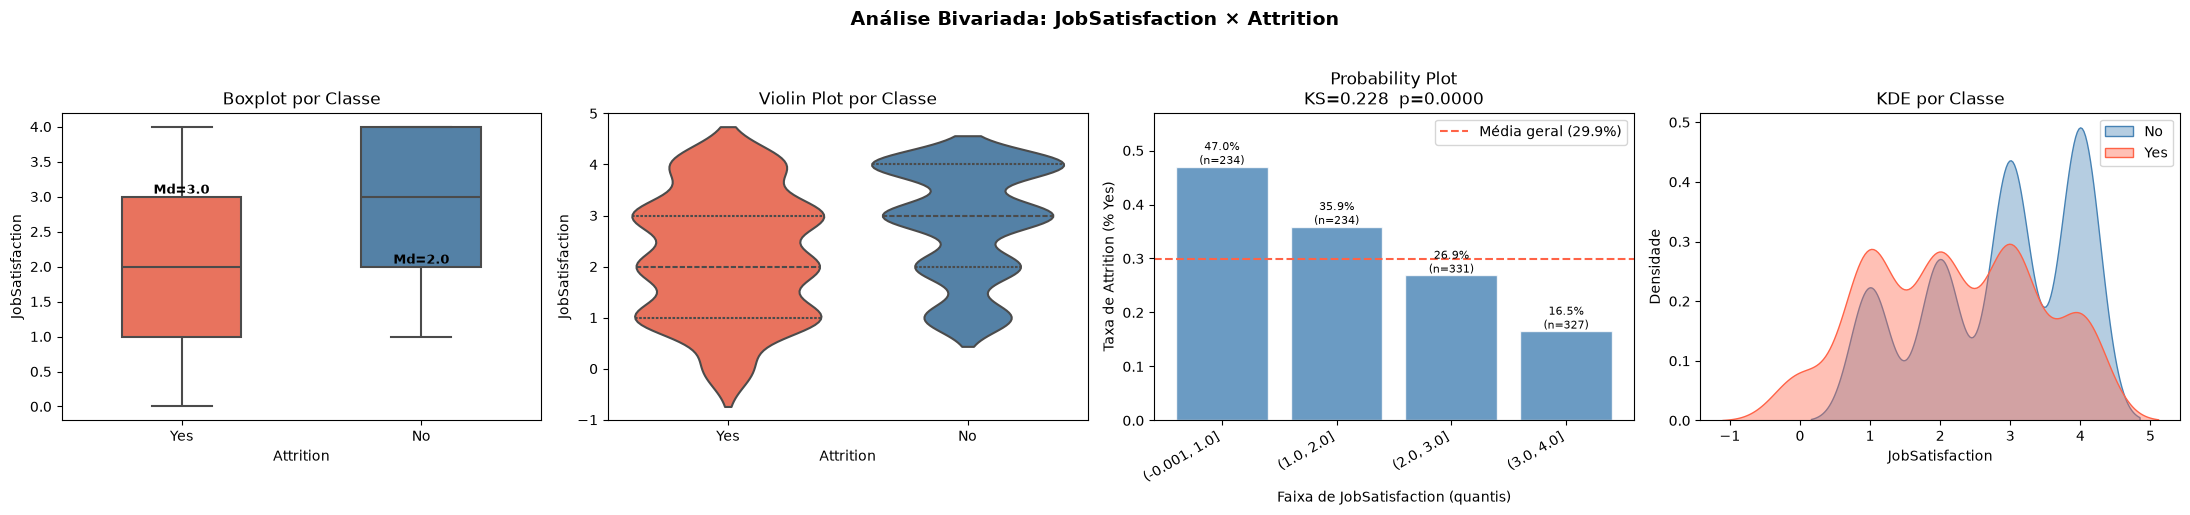

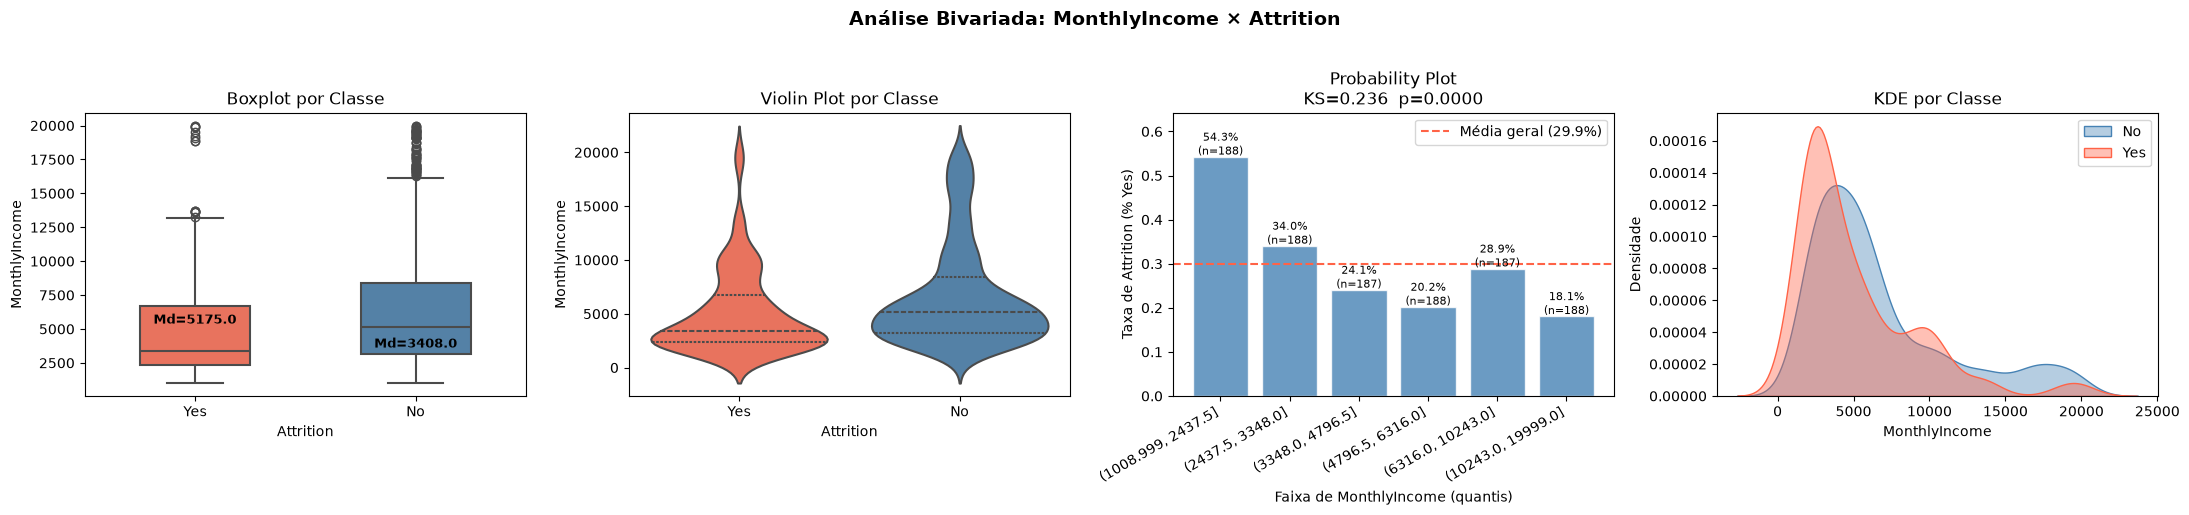

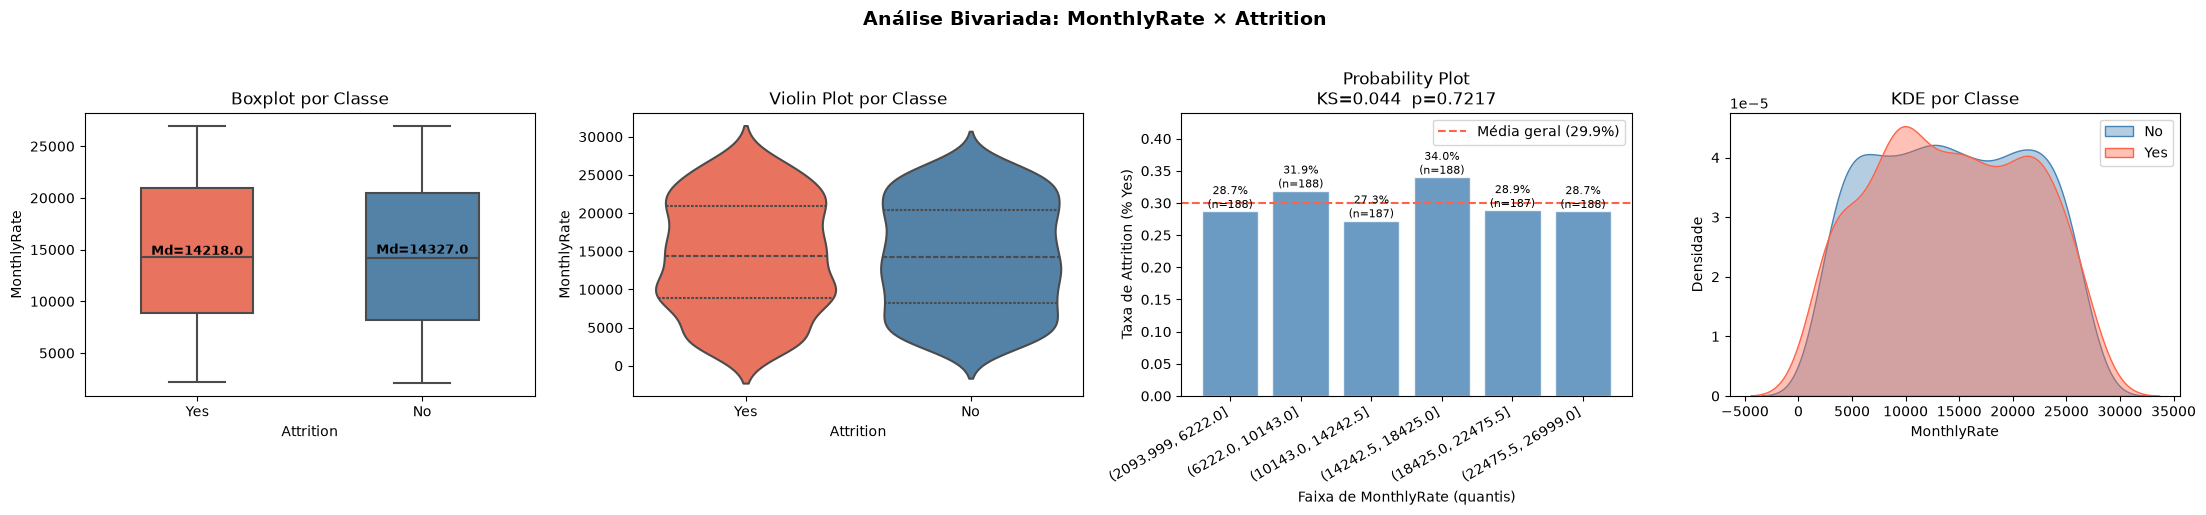

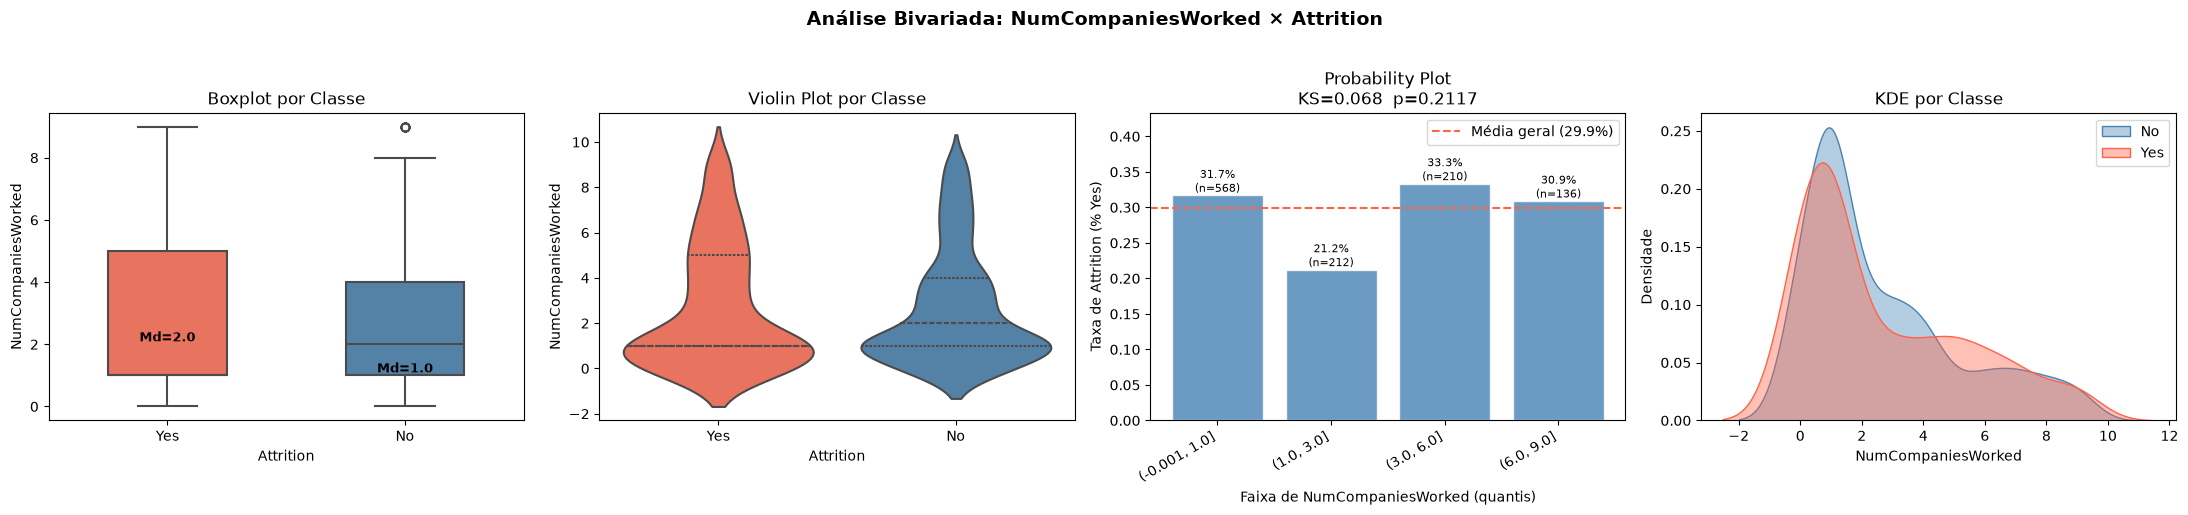

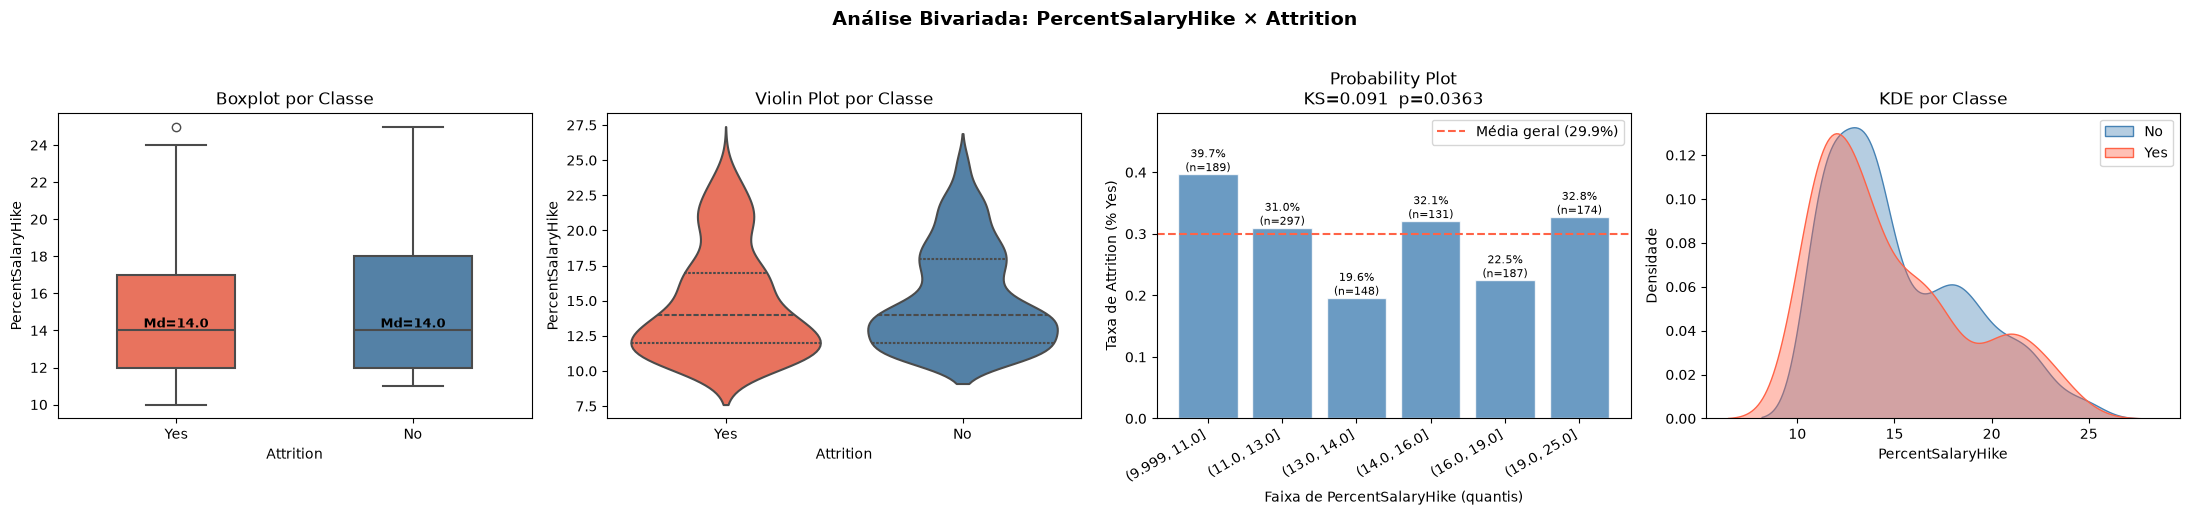

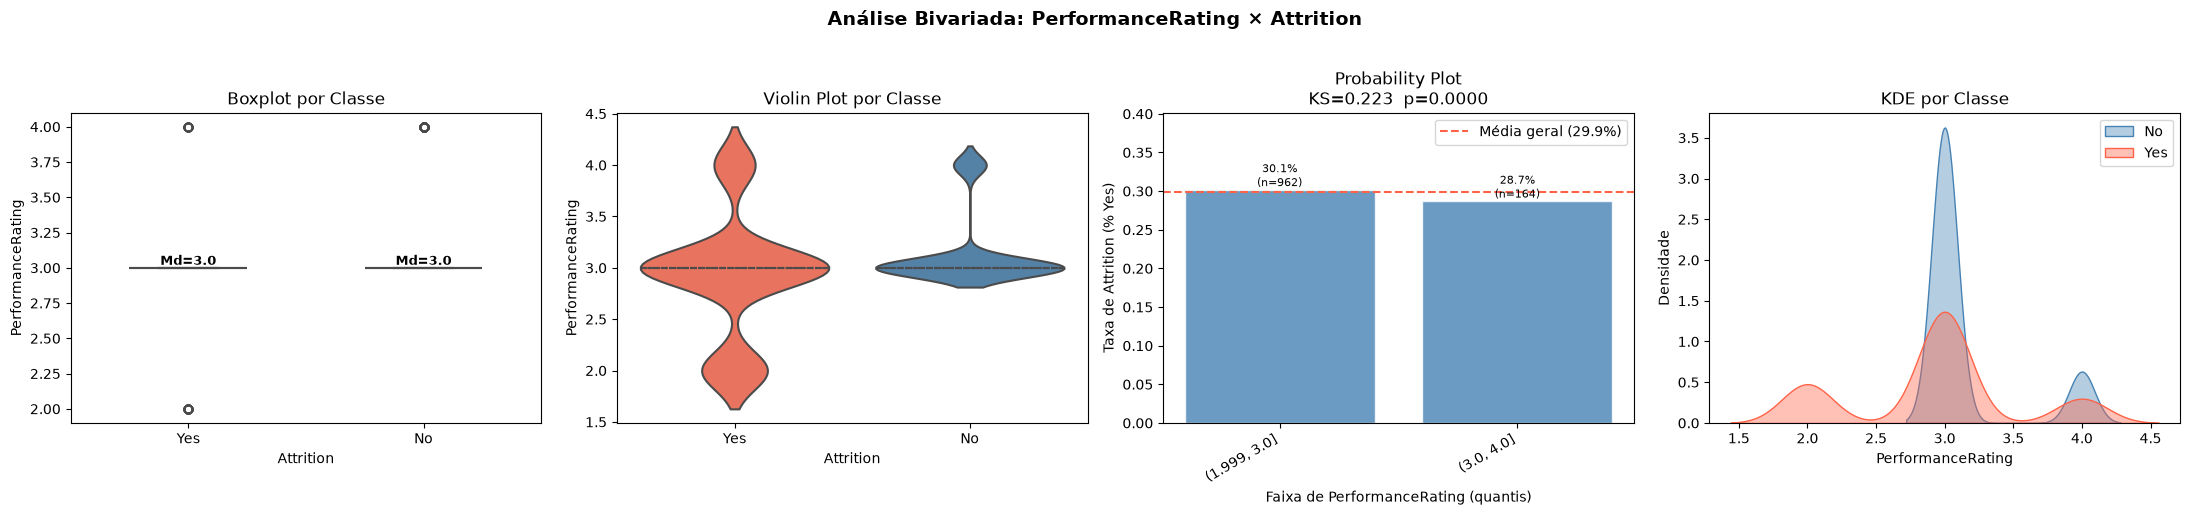

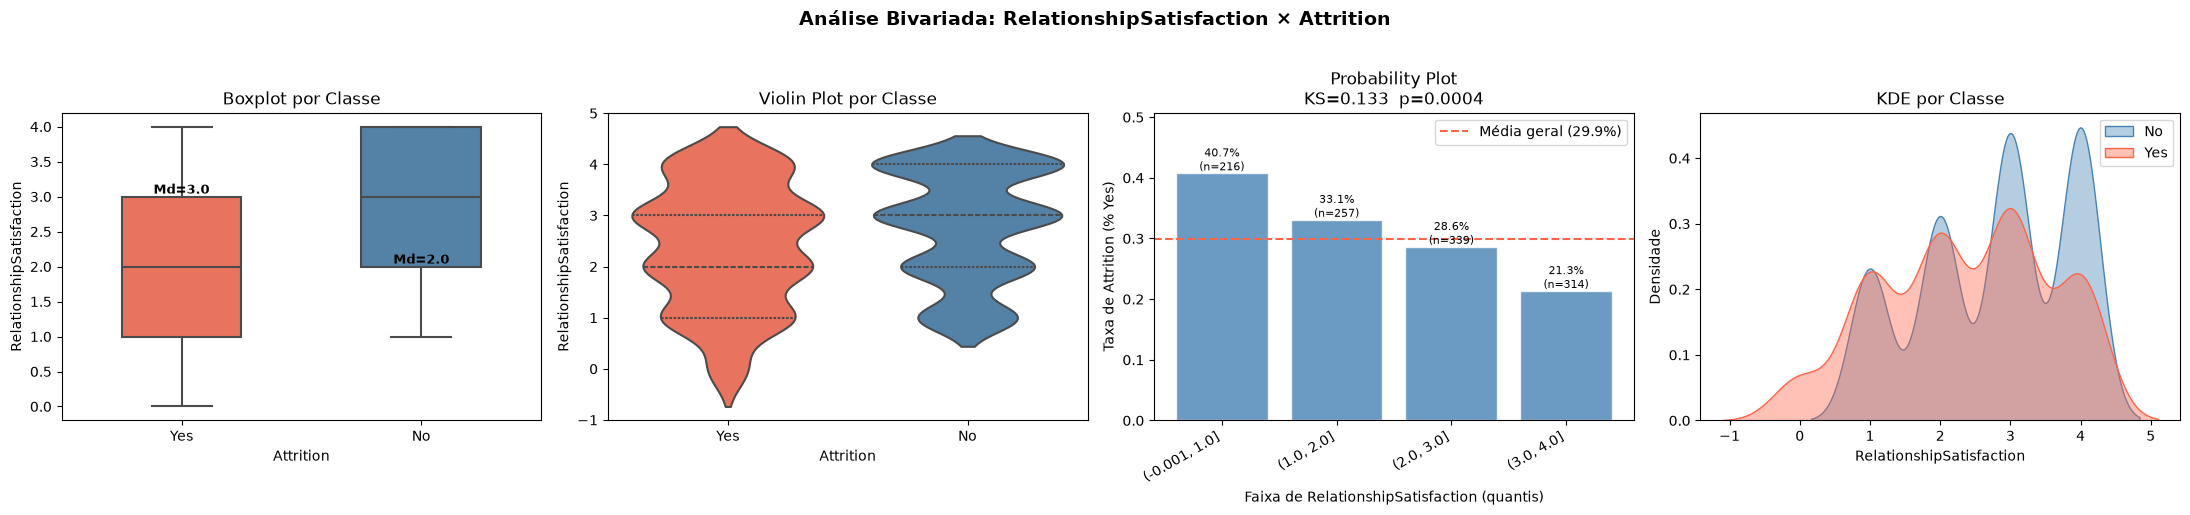

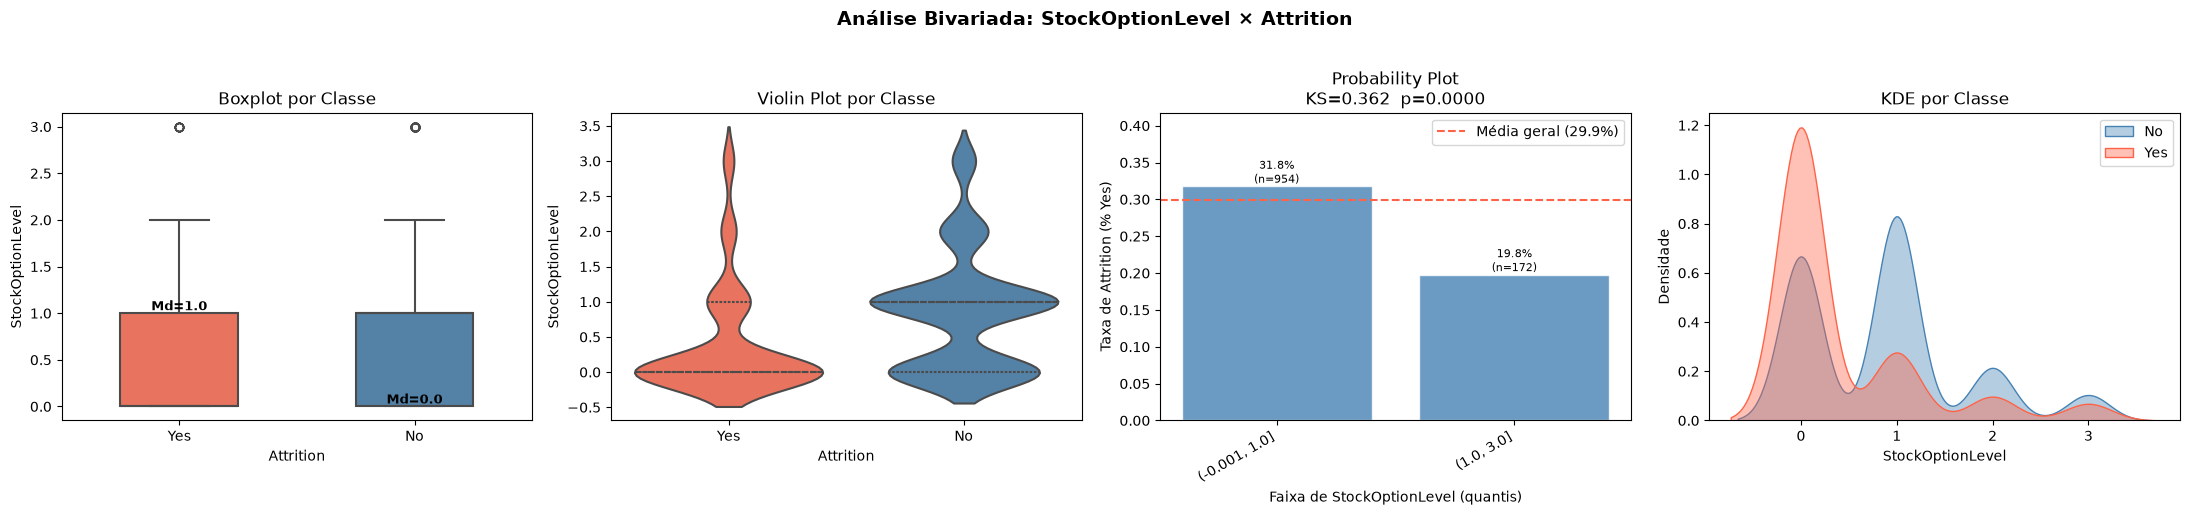

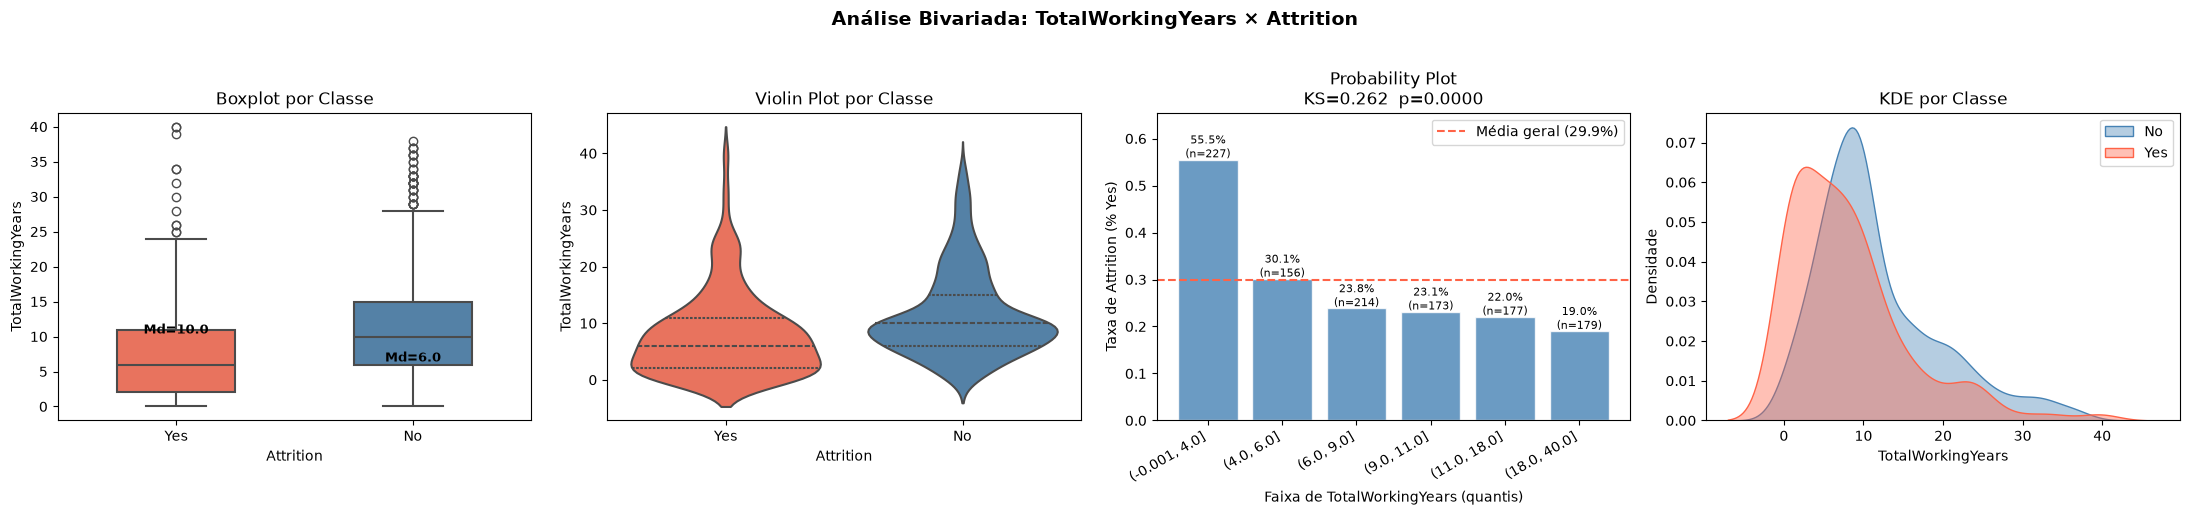

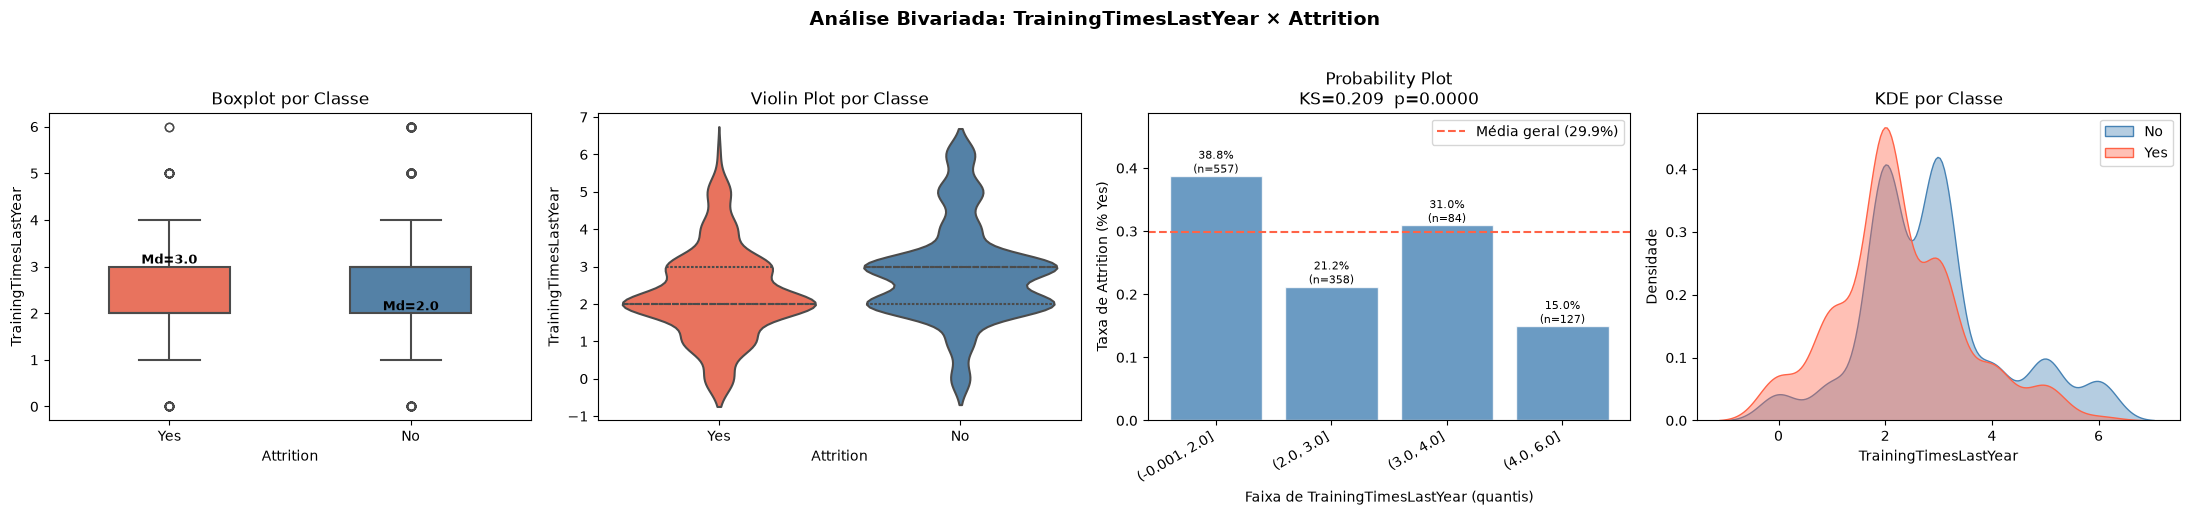

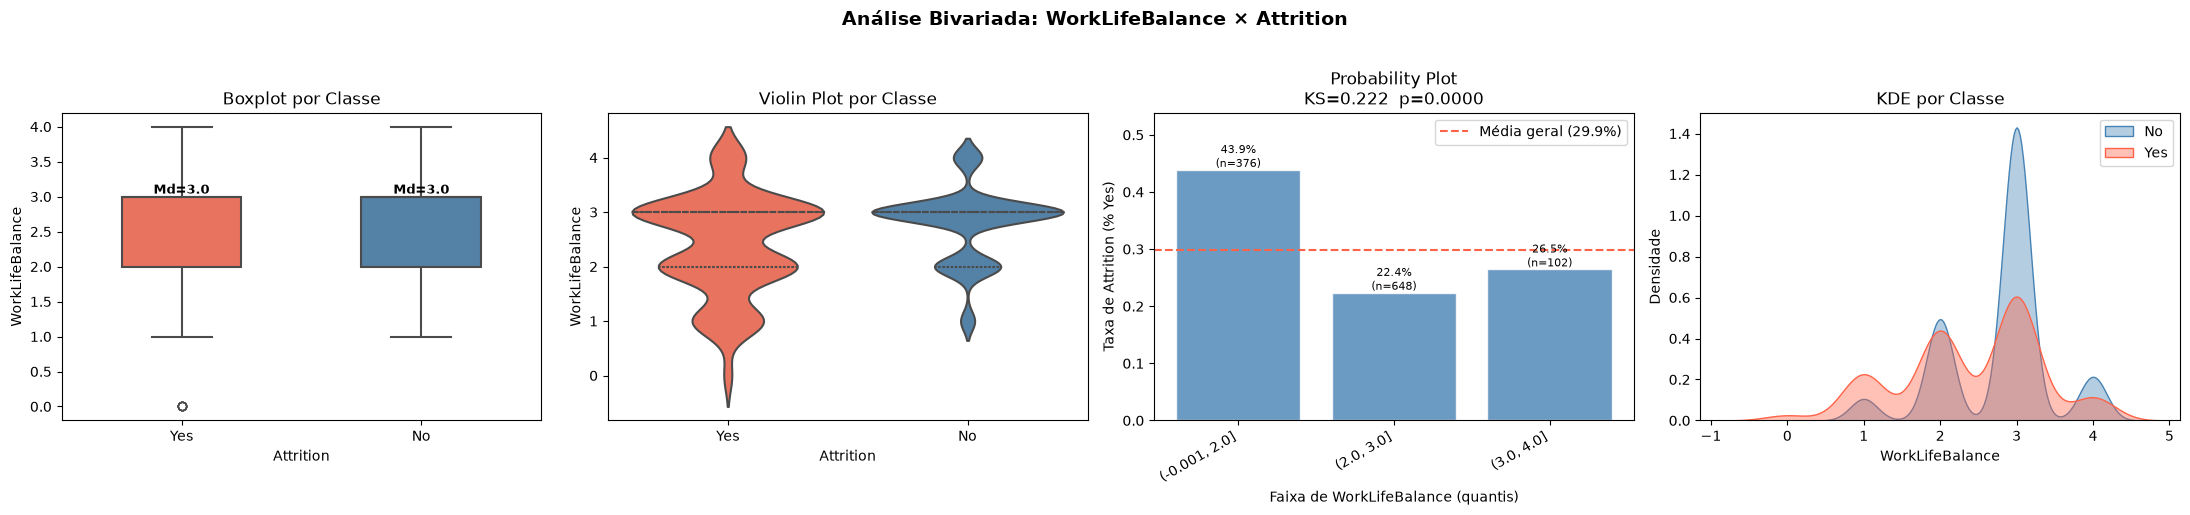

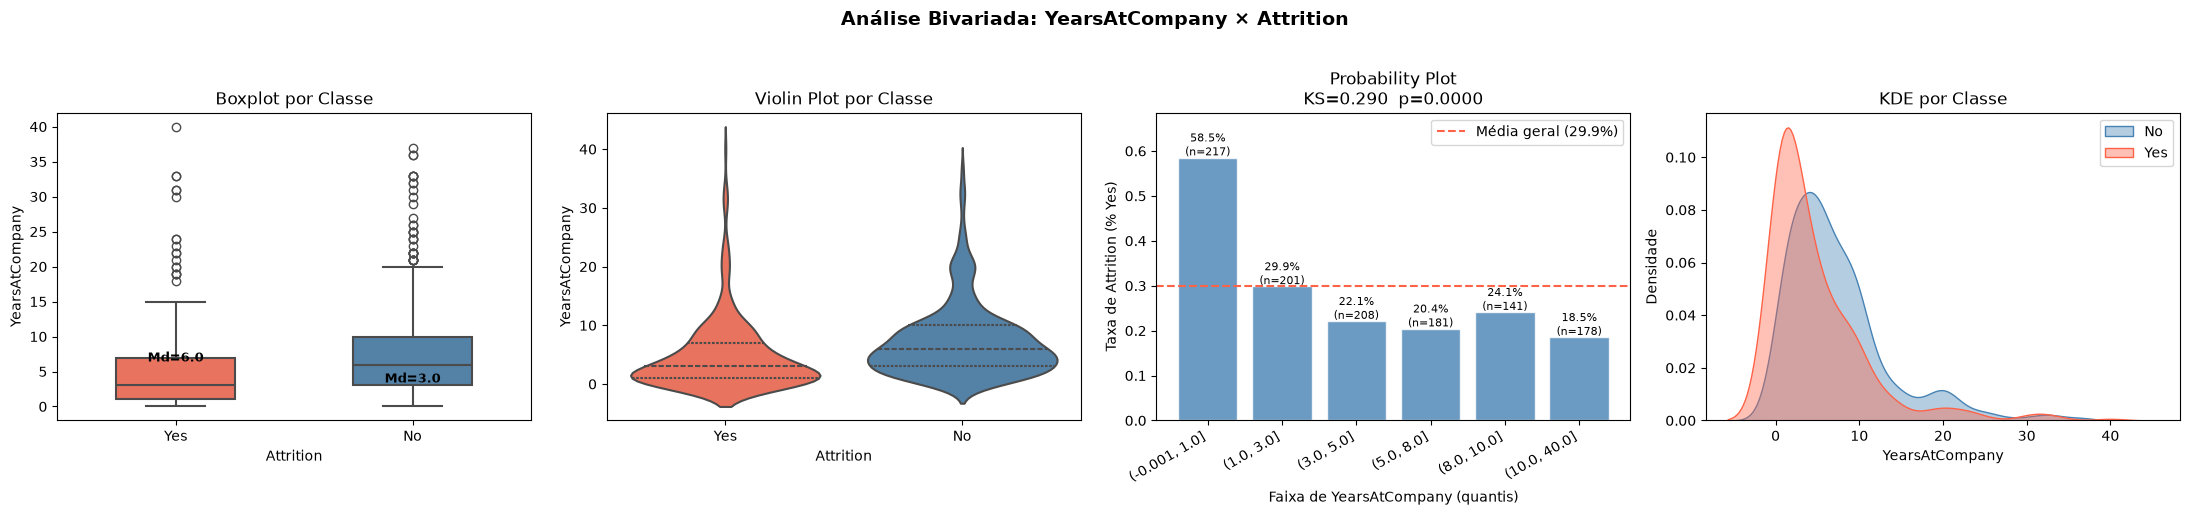

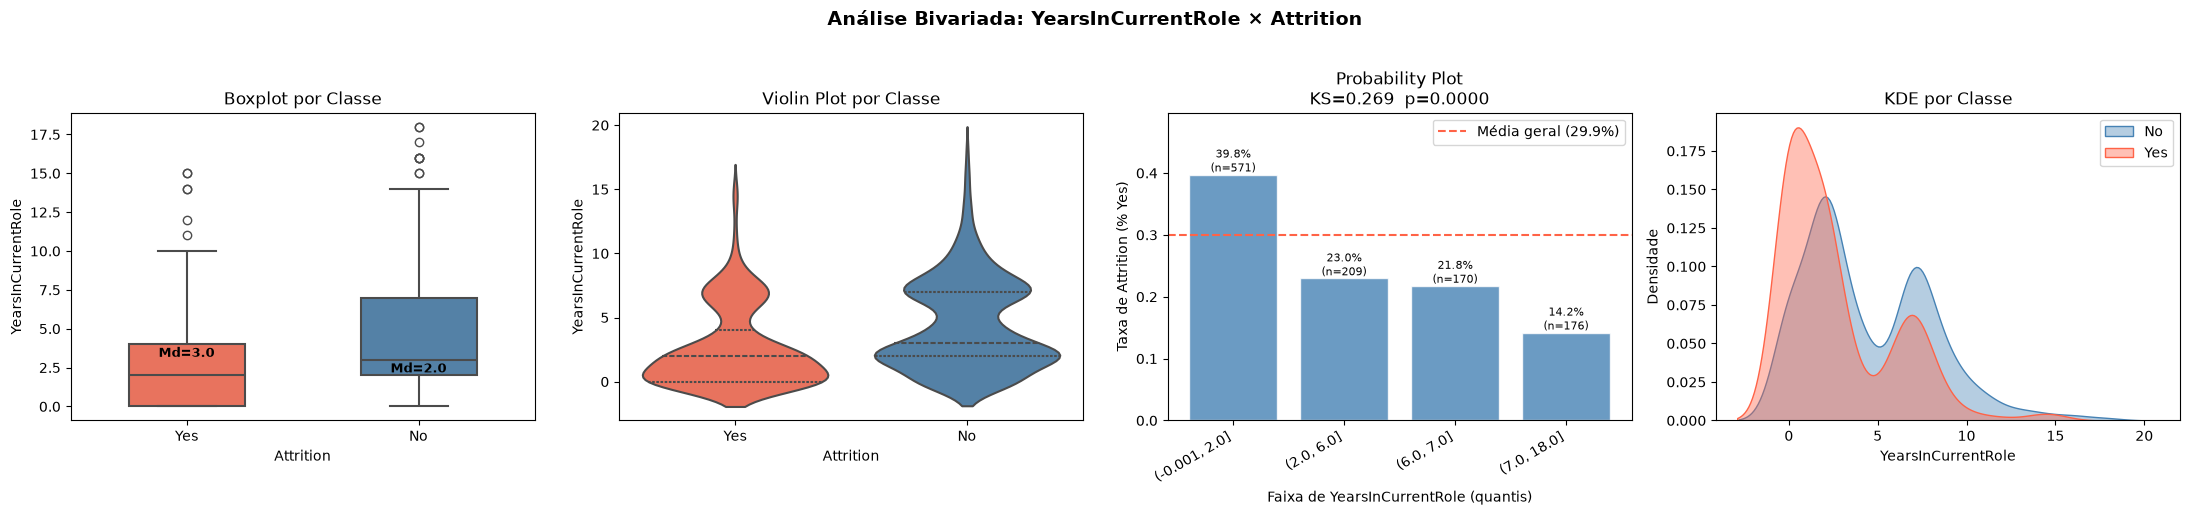

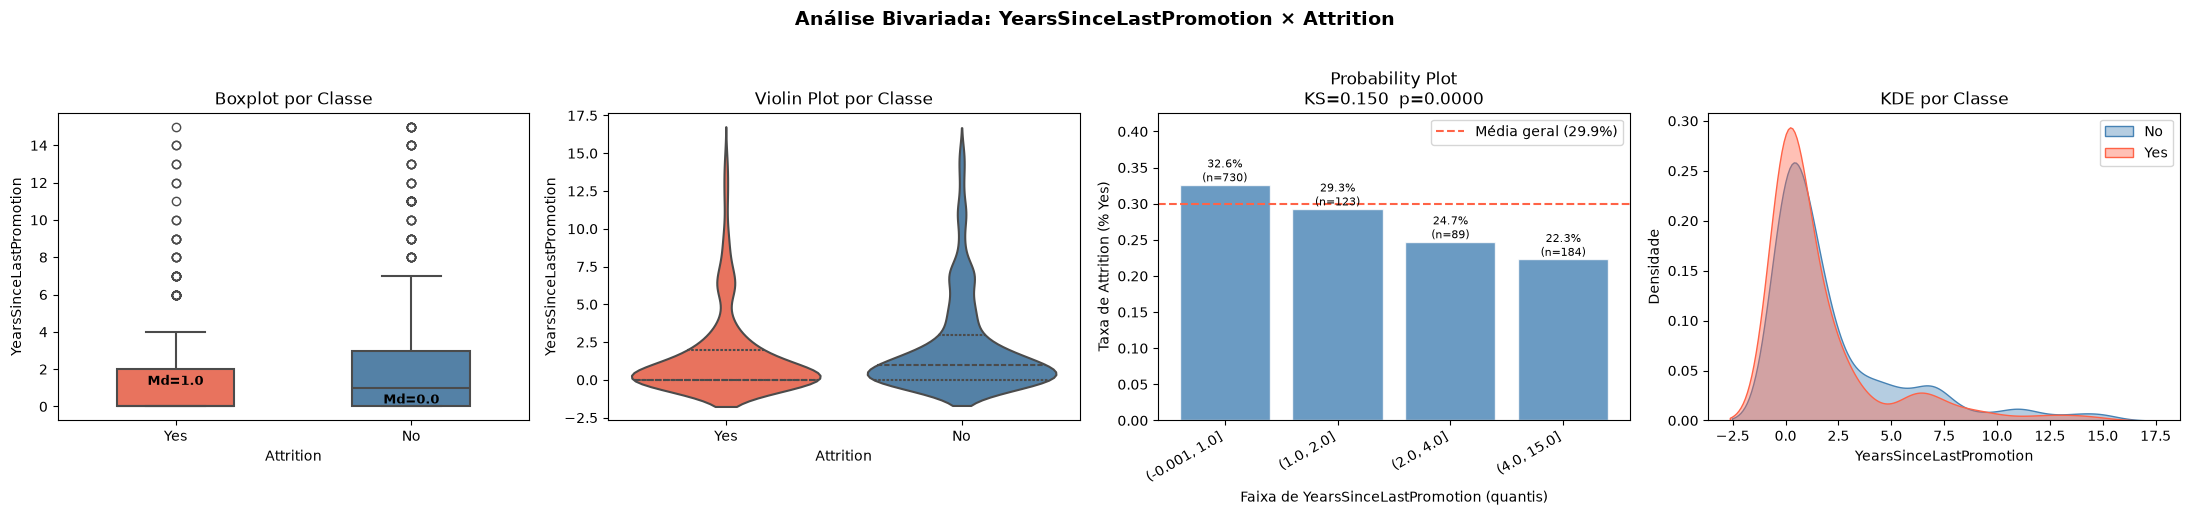

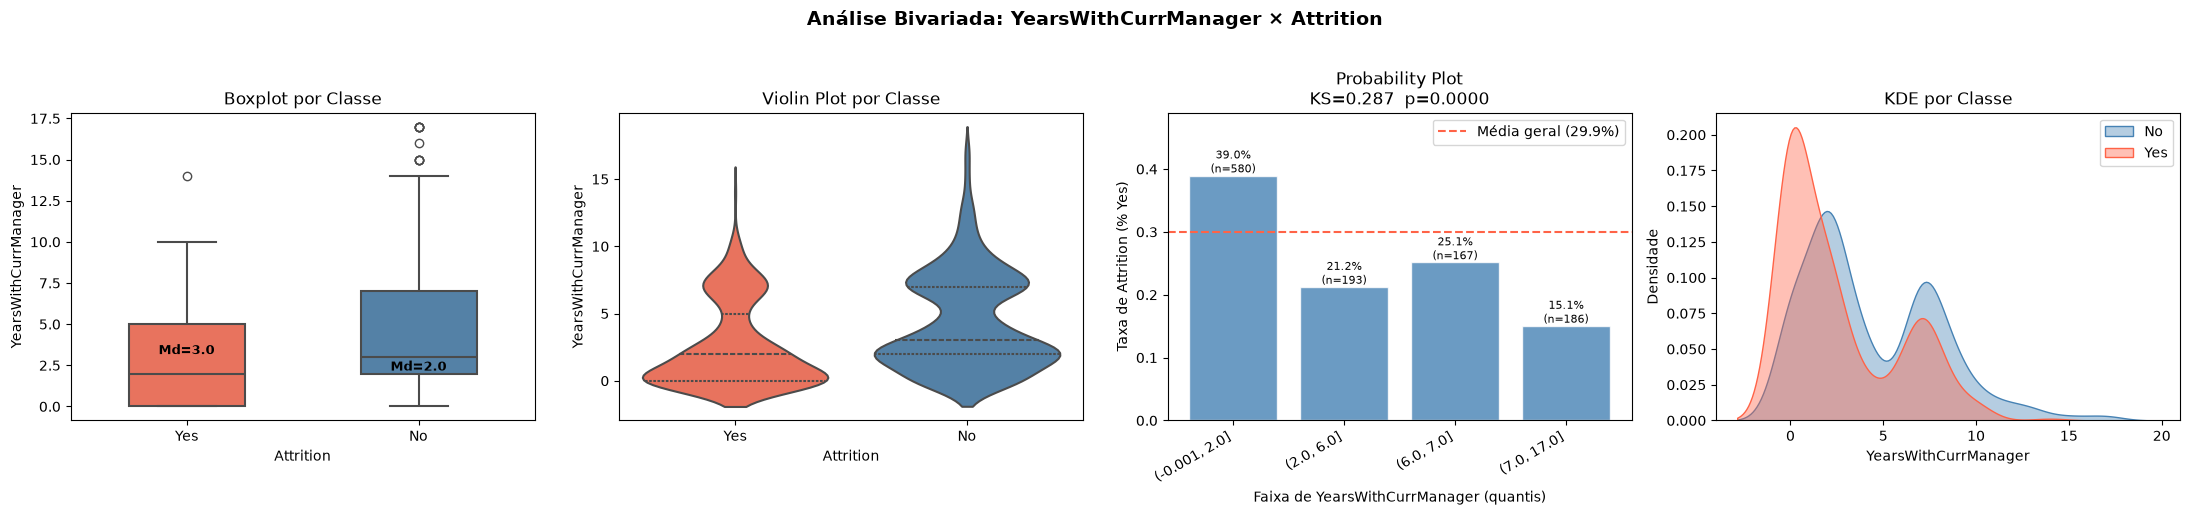

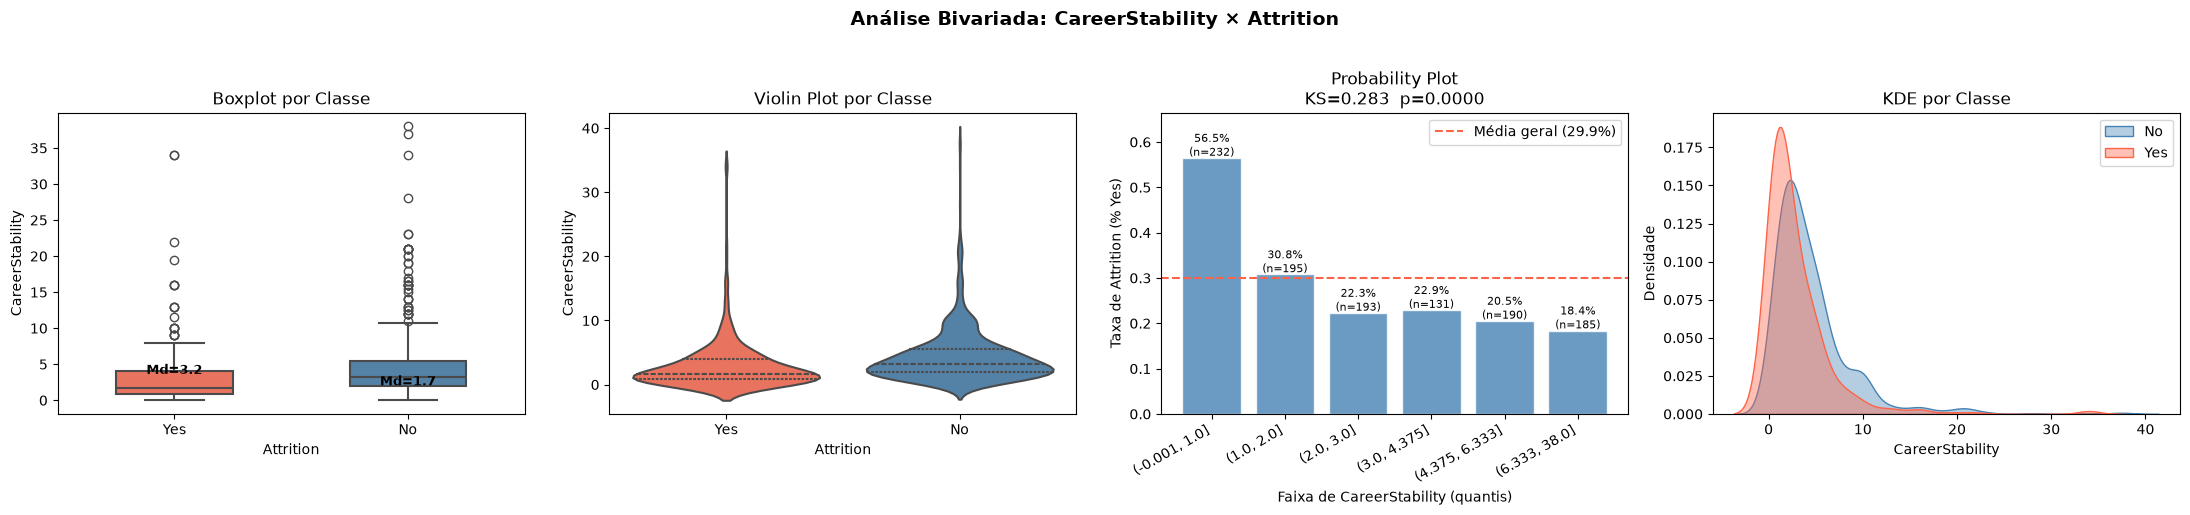

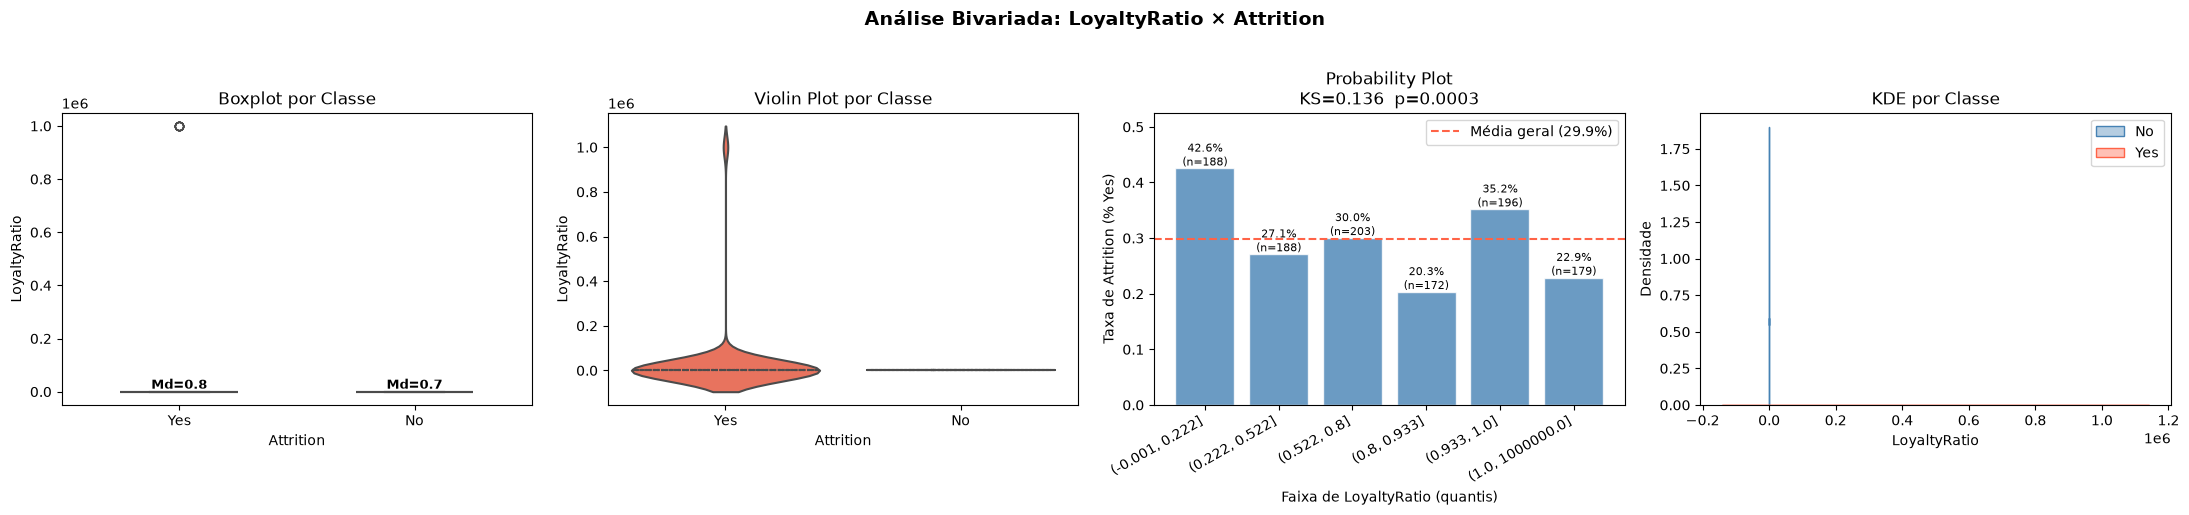

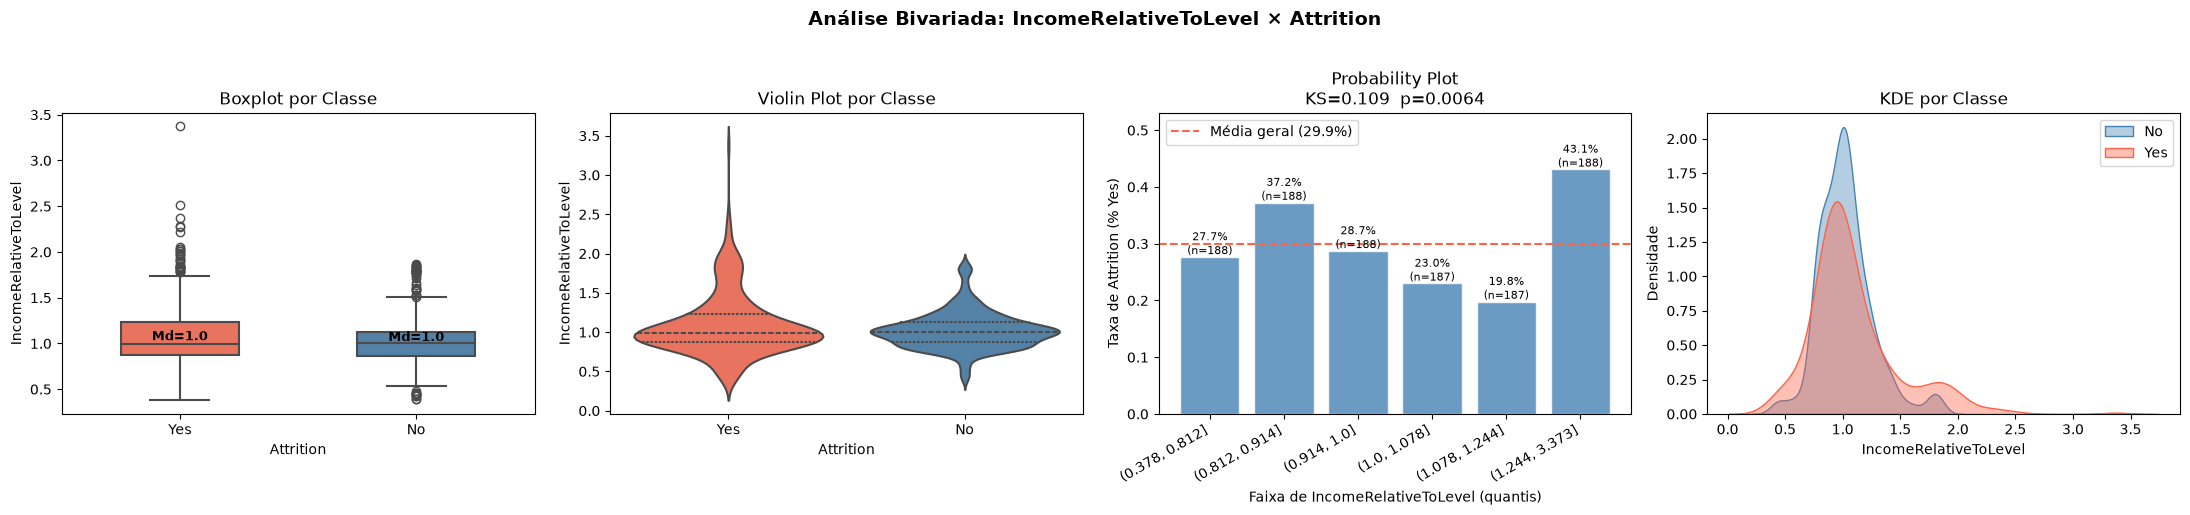

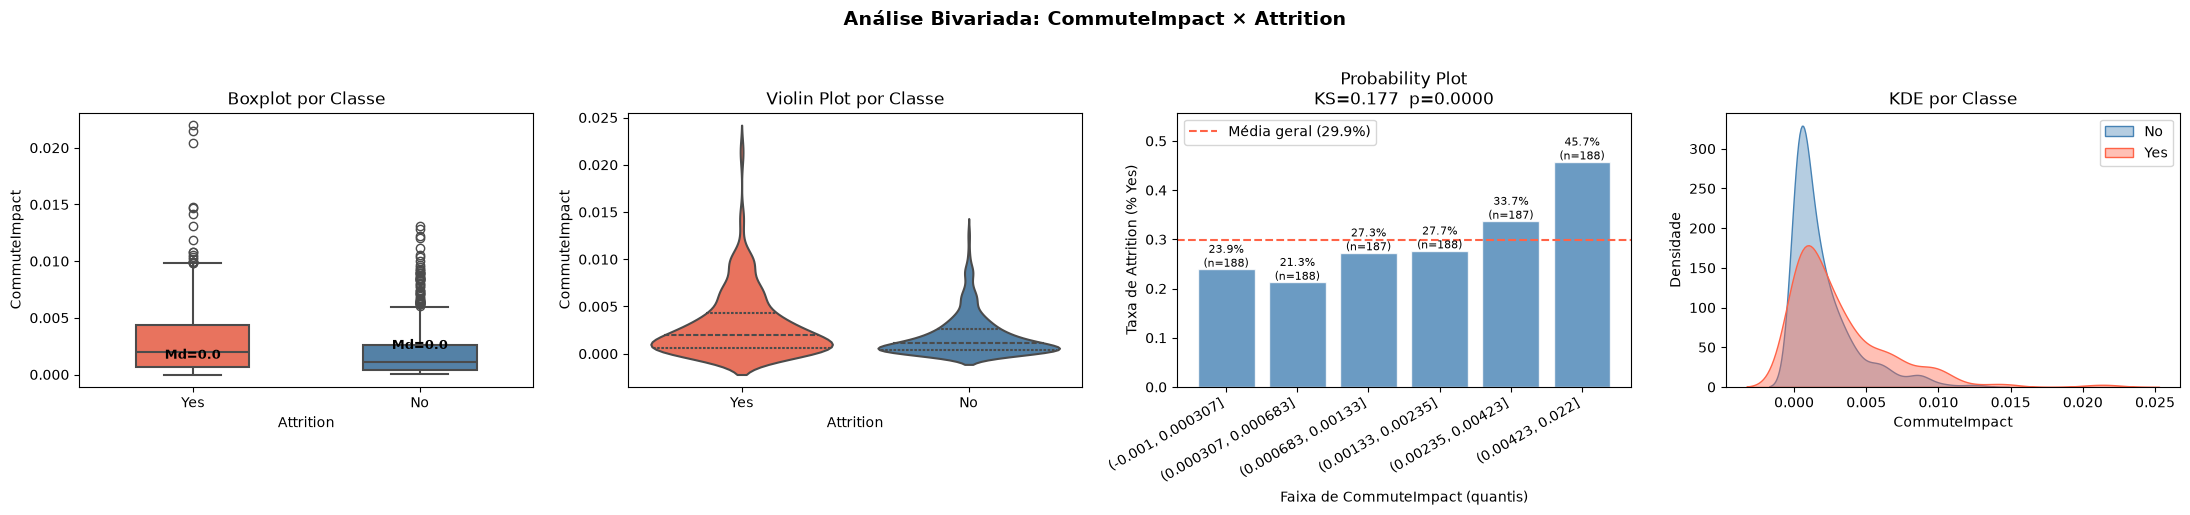

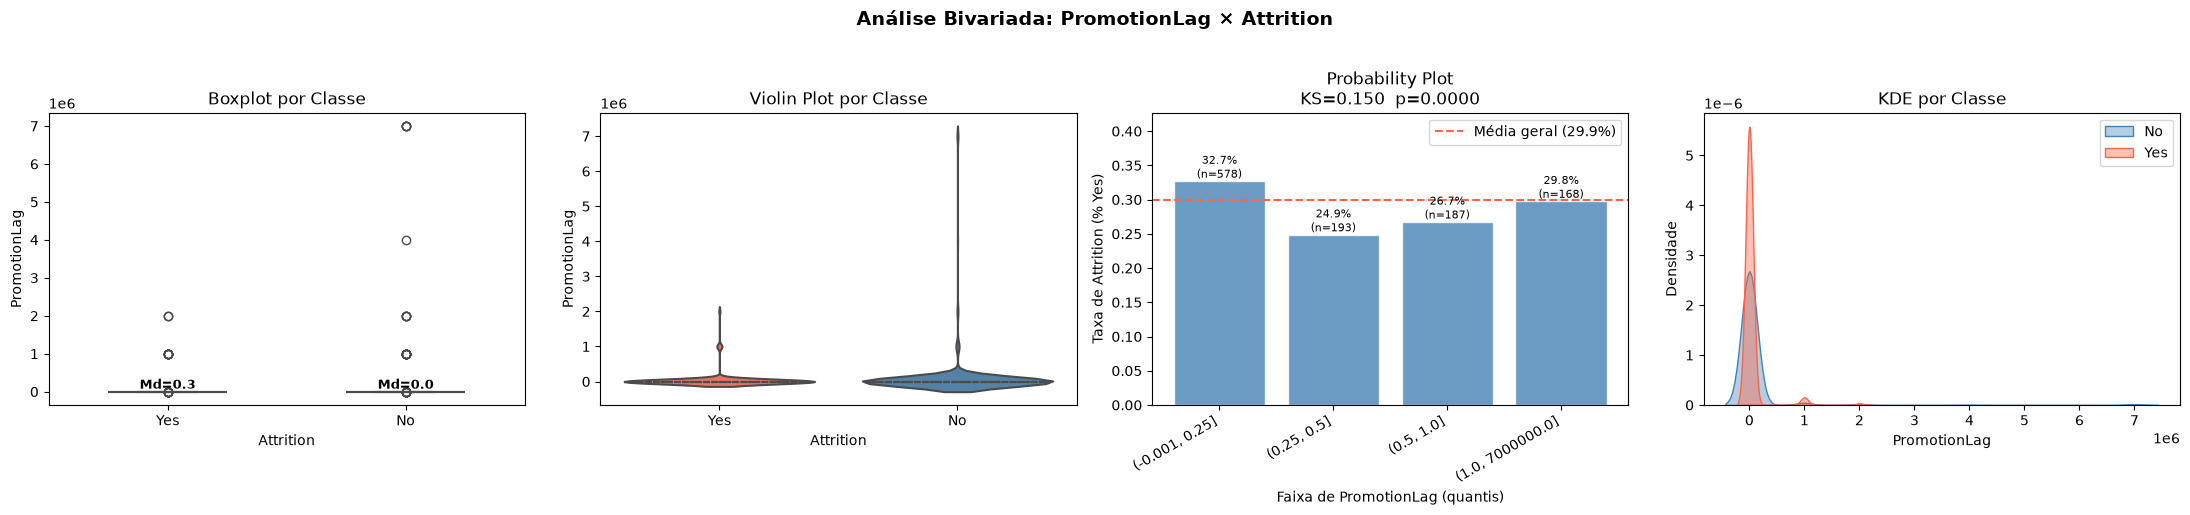

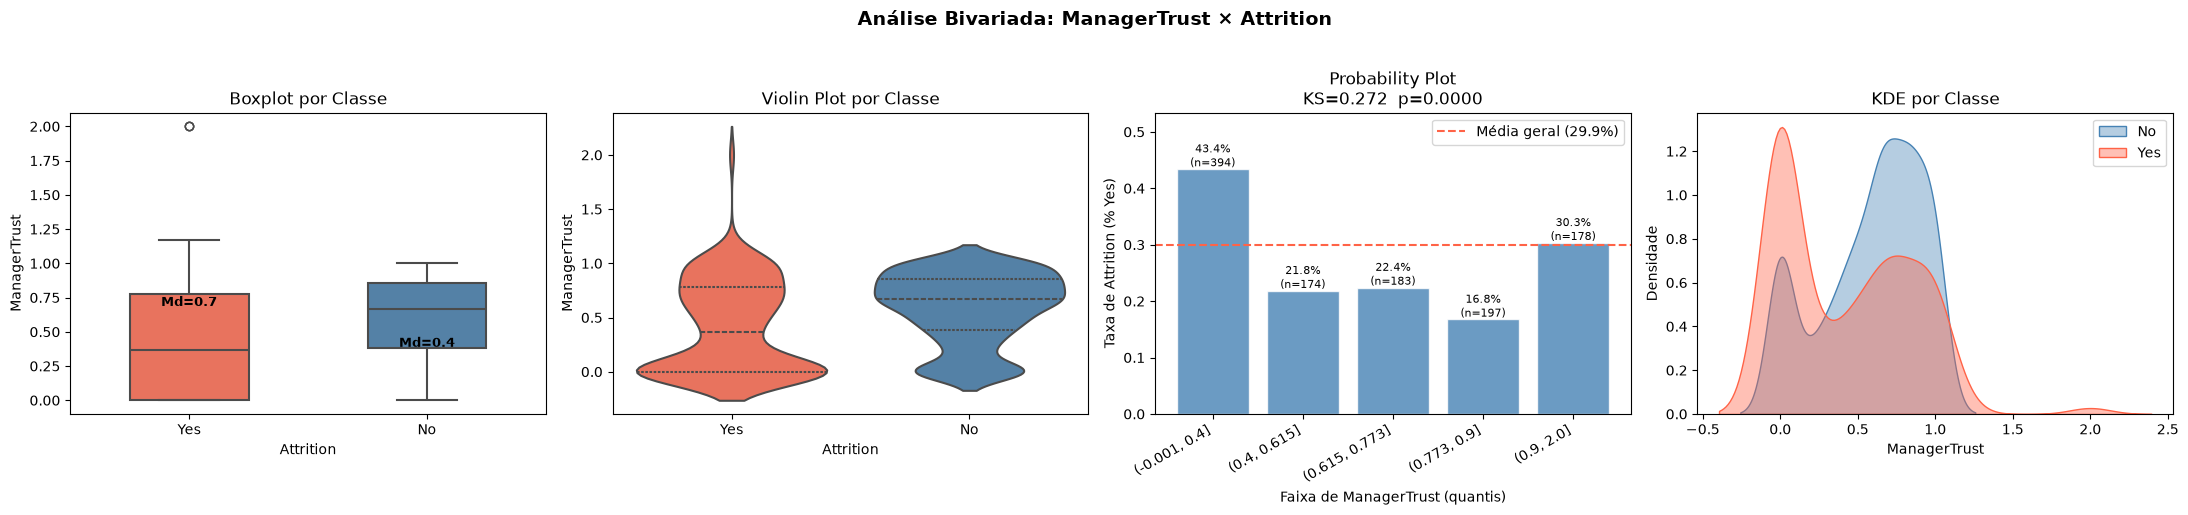

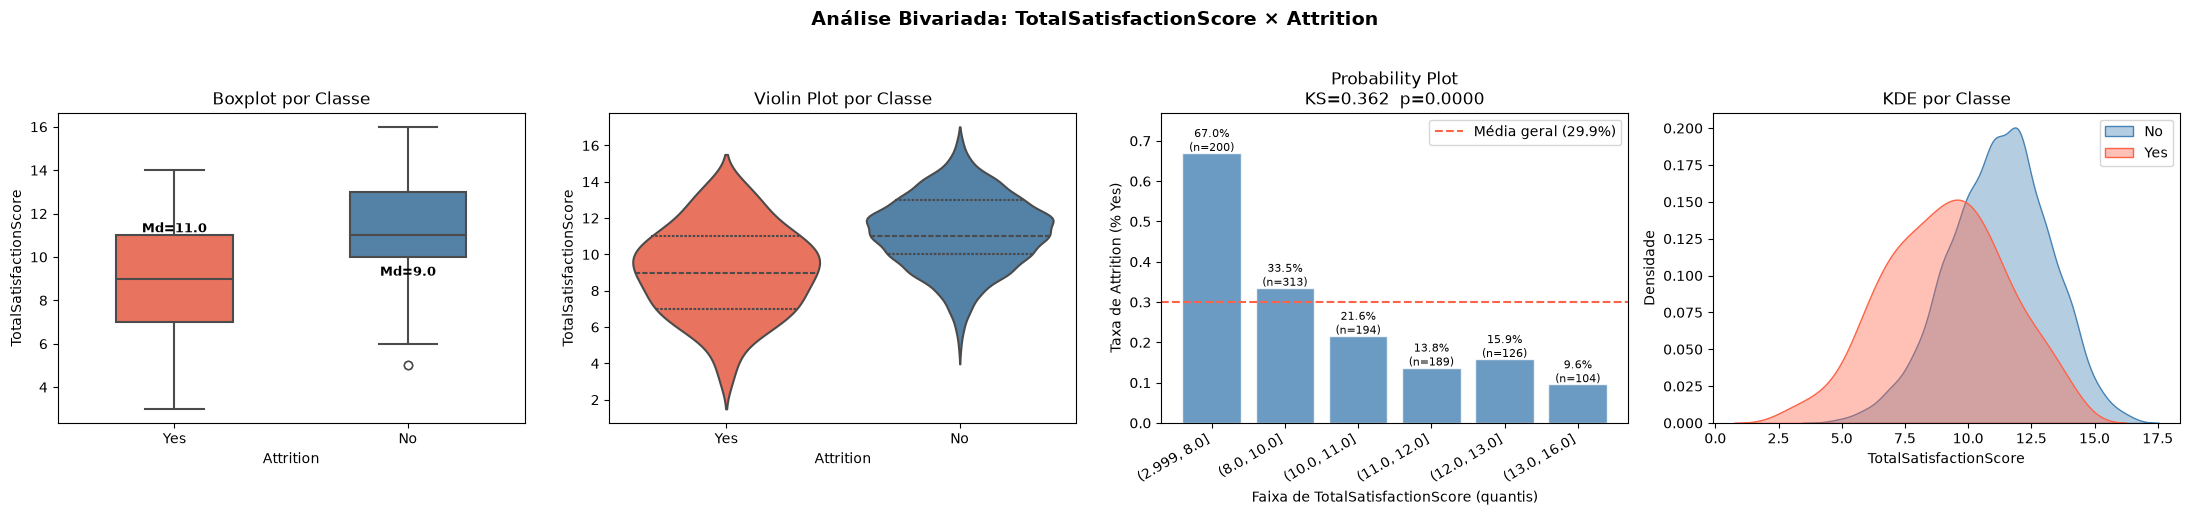

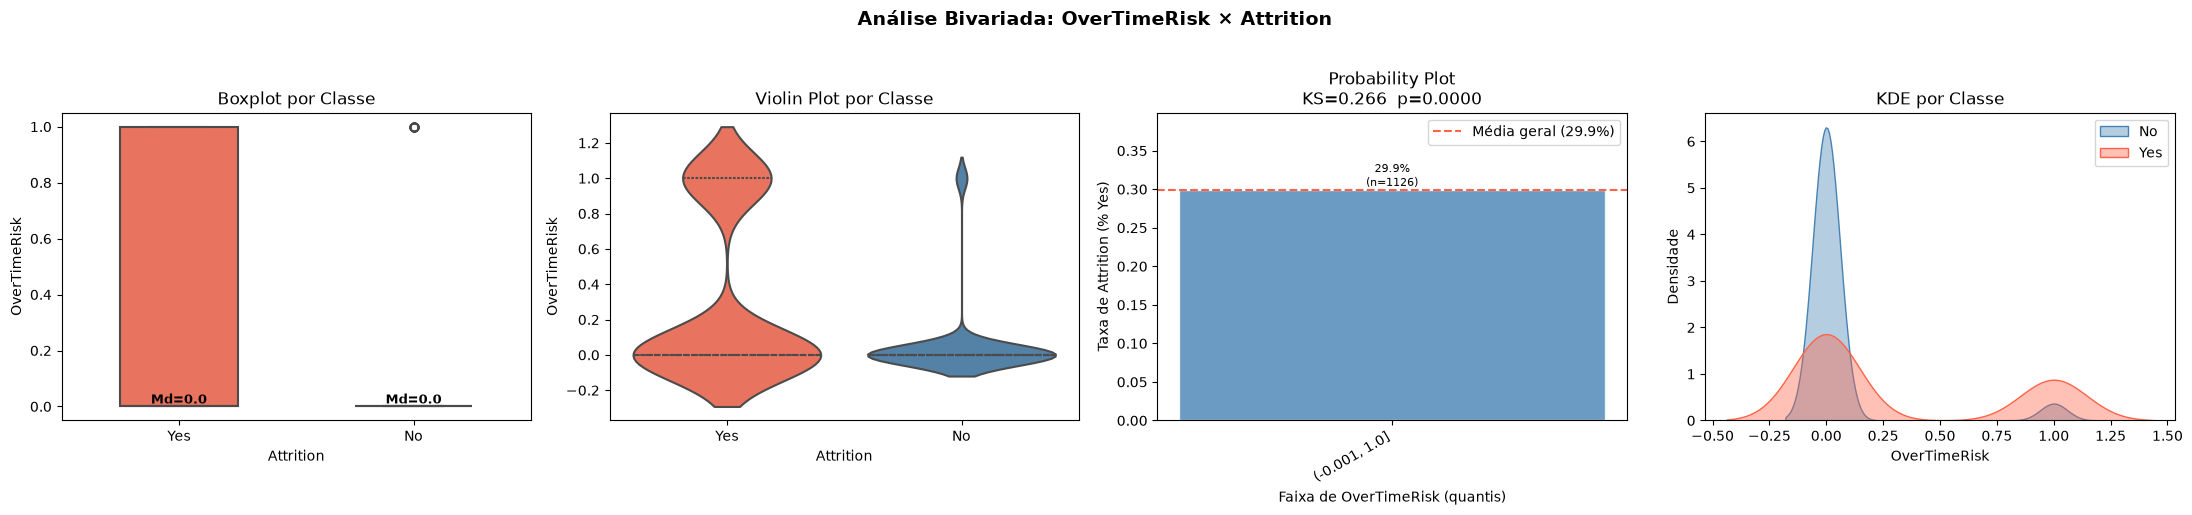

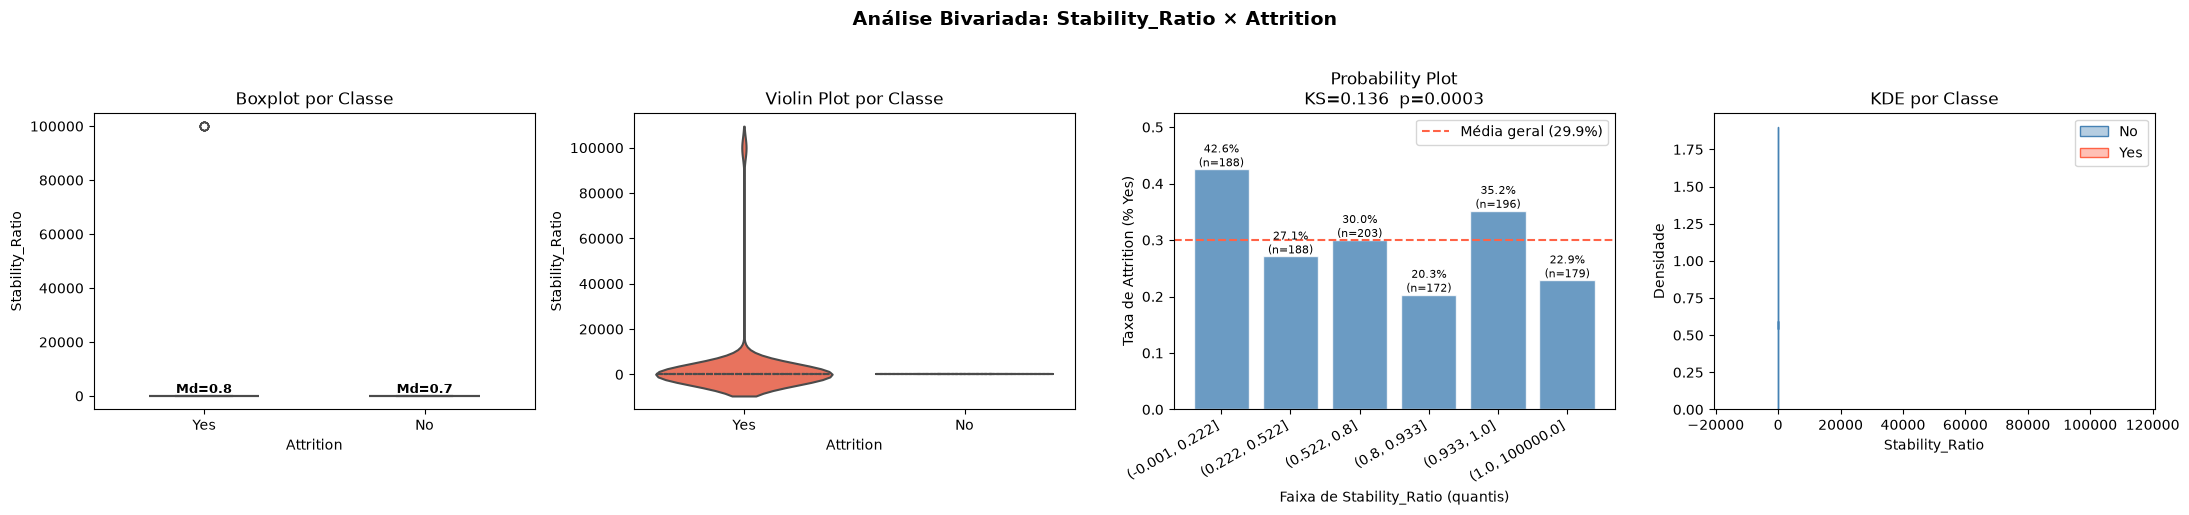

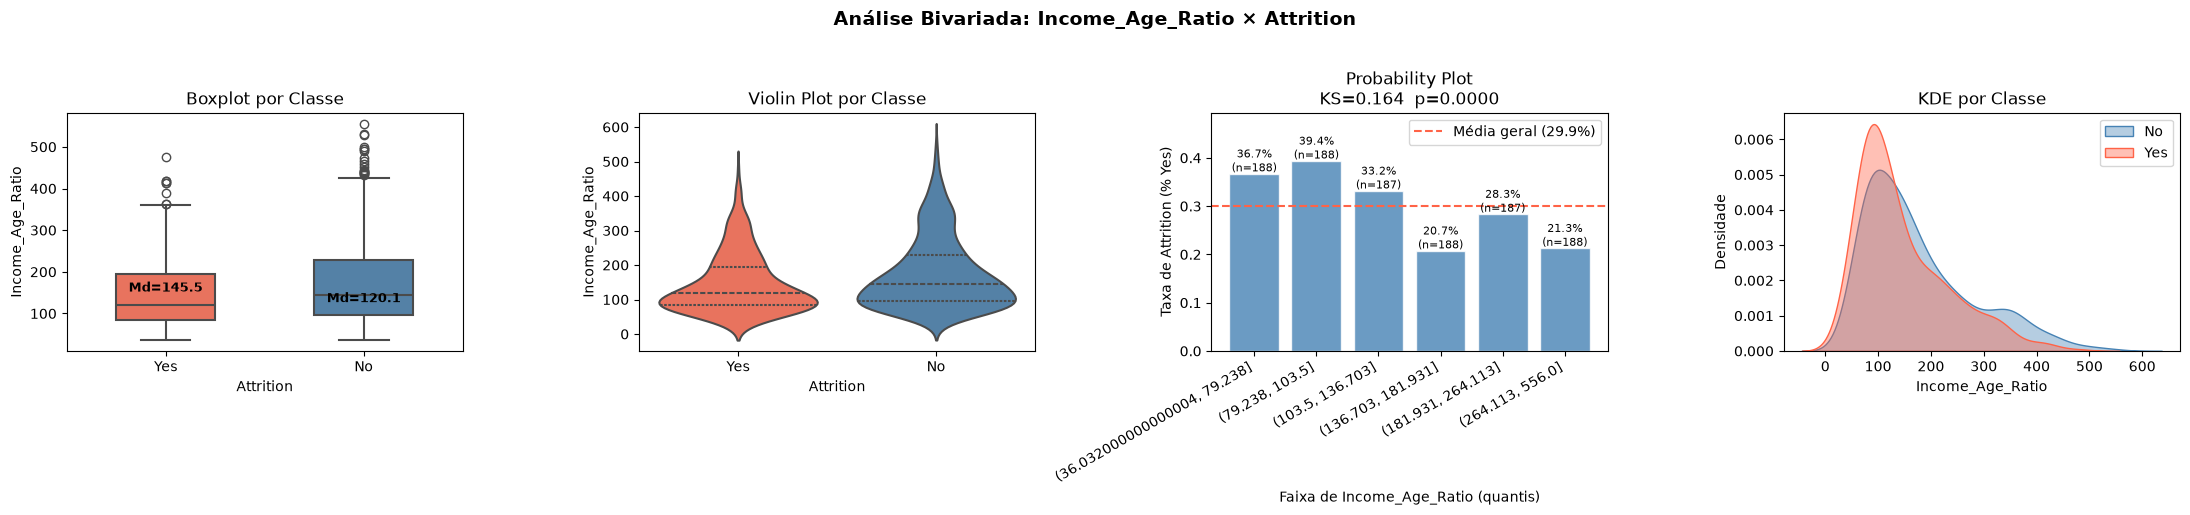

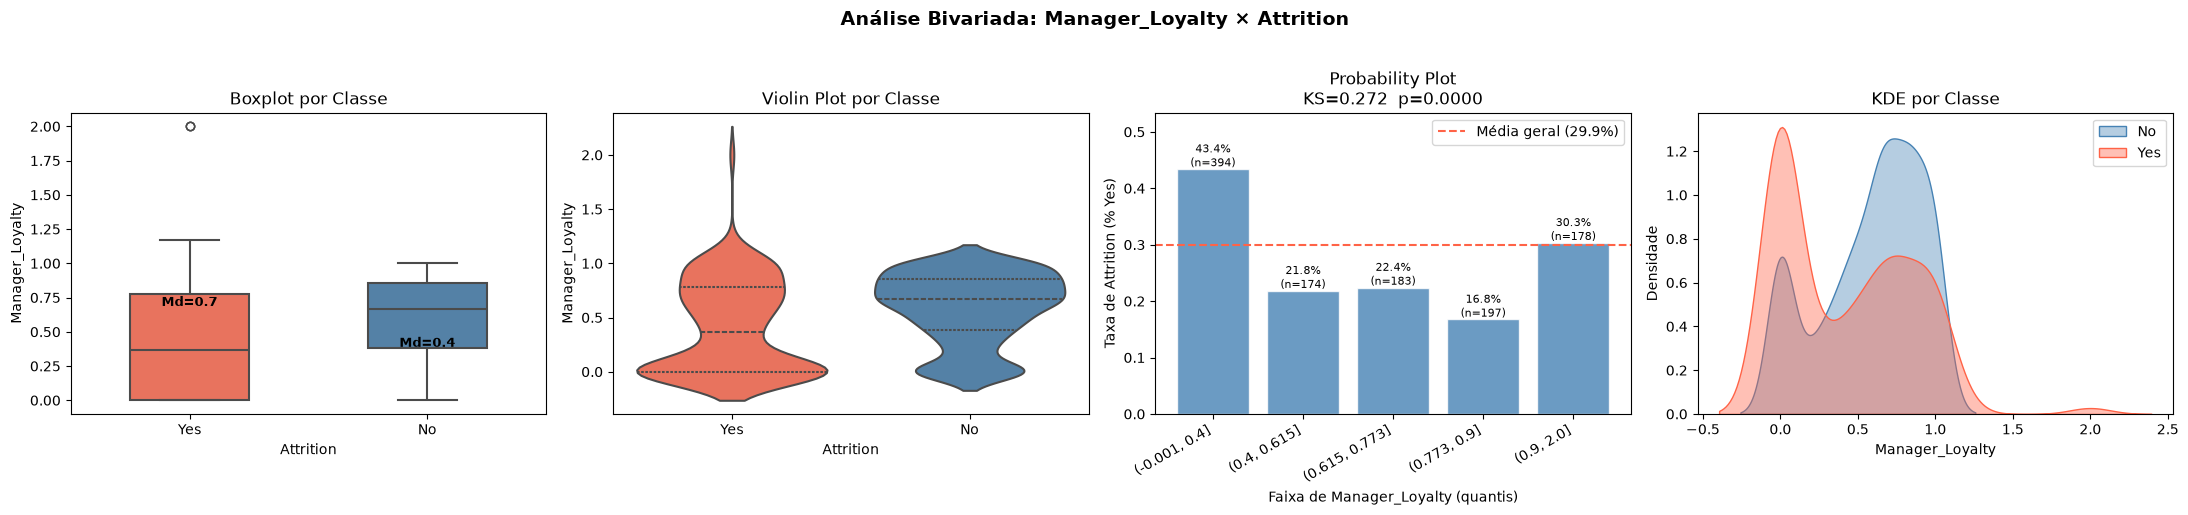

In [23]:
col_target = 'Attrition'

# Funciona tanto se Attrition for 'Yes'/'No' quanto 0/1
if df_train[col_target].dtype == object:
    y_binary = (df_train[col_target] == 'Yes').astype(int)
else:
    y_binary = df_train[col_target].astype(int)

# rótulo legível só para os gráficos (legenda Yes/No em vez de 1/0)
df_plot = df_train.copy()
df_plot['_classe'] = y_binary.map({0: 'No', 1: 'Yes'})

num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c != col_target]

palette = {'No': 'steelblue', 'Yes': 'tomato'}
taxa_geral = y_binary.mean()

for col in num_cols:
    # pula colunas constantes (ex.: EmployeeCount, StandardHours)
    if df_train[col].nunique(dropna=True) <= 1:
        print(f"[skip] {col}: coluna constante, sem análise bivariada.")
        continue

    g_no  = df_plot.loc[df_plot['_classe'] == 'No',  col].dropna()
    g_yes = df_plot.loc[df_plot['_classe'] == 'Yes', col].dropna()

    # KS só para exibir no título do probability plot
    ks_stat, ks_p = stats.ks_2samp(g_no, g_yes)

    # faixas por quantil para o probability plot
    df_prob = df_plot[[col]].copy()
    df_prob['y'] = y_binary.values
    try:
        df_prob['faixa'] = pd.qcut(df_prob[col], q=6, duplicates='drop')
    except ValueError:
        df_prob['faixa'] = pd.cut(df_prob[col], bins=6)

    prob_by_faixa = (
        df_prob.groupby('faixa', observed=True)['y']
        .agg(['mean', 'count']).reset_index()
    )
    prob_by_faixa.columns = ['Faixa', 'Taxa', 'N']
    prob_by_faixa['Faixa'] = prob_by_faixa['Faixa'].astype(str)

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {col_target}',
                 fontsize=14, fontweight='bold', y=1.02)

    # ── Plot 1: Boxplot por classe ──────────────────────────────────────
    sns.boxplot(data=df_plot, x='_classe', y=col, ax=axes[0], hue='_classe',
                palette=palette, width=0.5, linewidth=1.5, legend=False)
    for i, (group, label) in enumerate([(g_no, 'No'), (g_yes, 'Yes')]):
        med = group.median()
        axes[0].text(i, med, f'Md={med:.1f}', ha='center', va='bottom',
                     fontsize=9, fontweight='bold', color='black')
    axes[0].set_title('Boxplot por Classe')
    axes[0].set_xlabel(col_target); axes[0].set_ylabel(col)

    # ── Plot 2: Violin por classe ───────────────────────────────────────
    sns.violinplot(data=df_plot, x='_classe', y=col, ax=axes[1], hue='_classe',
                   palette=palette, inner='quartile', linewidth=1.5, legend=False)
    axes[1].set_title('Violin Plot por Classe')
    axes[1].set_xlabel(col_target); axes[1].set_ylabel(col)

    # ── Plot 3: Probability Plot (taxa de attrition por faixa) ──────────
    bars = axes[2].bar(prob_by_faixa['Faixa'], prob_by_faixa['Taxa'],
                       color='steelblue', alpha=0.8, edgecolor='white')
    axes[2].axhline(taxa_geral, color='tomato', linestyle='--', linewidth=1.5,
                    label=f'Média geral ({taxa_geral:.1%})')
    for bar, (_, row_data) in zip(bars, prob_by_faixa.iterrows()):
        axes[2].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.005,
                     f"{row_data['Taxa']:.1%}\n(n={int(row_data['N'])})",
                     ha='center', fontsize=8, color='black')
    axes[2].set_title(f'Probability Plot\nKS={ks_stat:.3f}  p={ks_p:.4f}')
    axes[2].set_xlabel(f'Faixa de {col} (quantis)')
    axes[2].set_ylabel('Taxa de Attrition (% Yes)')
    axes[2].set_xticks(range(len(prob_by_faixa)))
    axes[2].set_xticklabels(prob_by_faixa['Faixa'], rotation=30, ha='right')
    _ymax = prob_by_faixa['Taxa'].max()
    axes[2].set_ylim(0, (_ymax + 0.1) if pd.notna(_ymax) else 1)
    axes[2].legend()

    # ── Plot 4: KDE por classe ──────────────────────────────────────────
    sns.kdeplot(g_no,  ax=axes[3], label='No',  fill=True, alpha=0.4, color='steelblue')
    sns.kdeplot(g_yes, ax=axes[3], label='Yes', fill=True, alpha=0.4, color='tomato')
    axes[3].set_title('KDE por Classe')
    axes[3].set_xlabel(col); axes[3].set_ylabel('Densidade')
    axes[3].legend()

    plt.tight_layout()
    plt.show()
    plt.close(fig)


### 6.2.2 Cat Attributes

In [24]:
from scipy.stats import chi2_contingency


col_target = 'Attrition'

# Funciona tanto se Attrition for 'Yes'/'No' quanto 0/1
if df_train[col_target].dtype == object:
    y_binary = (df_train[col_target] == 'Yes').astype(int)
else:
    y_binary = df_train[col_target].astype(int)

cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != col_target]

def classify_cat(row):
    if row['AUC Univariado'] >= 0.60:
        return '🟢 Alta'
    elif row['AUC Univariado'] >= 0.55:
        return '🟡 Média'
    else:
        return '🔴 Baixa'

resultados_cat = []
for col in cat_cols:
    # pula colunas constantes (ex.: Over18)
    if df_train[col].nunique(dropna=True) <= 1:
        print(f"[skip] {col}: coluna constante.")
        continue

    # qui-quadrado e Cramér's V
    contingency = pd.crosstab(df_train[col], df_train[col_target])
    chi2, p_value, _, _ = chi2_contingency(contingency)
    cv = cramers_v(df_train[col], df_train[col_target])

    # AUC de uma logística univariada sobre a categórica encodada
    X_enc = LabelEncoder().fit_transform(df_train[col]).reshape(-1, 1)
    model = LogisticRegression(max_iter=300).fit(X_enc, y_binary)
    auc = roc_auc_score(y_binary, model.predict_proba(X_enc)[:, 1])
    auc = max(auc, 1 - auc)

    resultados_cat.append({
        'Feature': col,
        'Chi2': chi2,
        'Chi2_p': p_value,
        "Cramers_V": cv,
        'AUC Univariado': auc,
    })

df_train_cat_analysis = pd.DataFrame(resultados_cat)
df_train_cat_analysis['Discriminação'] = df_train_cat_analysis.apply(classify_cat, axis=1)

df_train_cat_analysis = (
    df_train_cat_analysis
    .sort_values('AUC Univariado', ascending=False)
    .reset_index(drop=True)
)
df_train_cat_analysis


[skip] Over18: coluna constante.


,Feature,Chi2,Chi2_p,Cramers_V,AUC Univariado,Discriminação
0,OverTime,125.624947,3.714503e-29,0.332832,0.671633,🟢 Alta
1,MaritalStatus,72.405357,1.893985e-16,0.250162,0.637565,🟢 Alta
2,JobRole,92.735985,1.292793e-16,0.274435,0.572804,🟡 Média
3,Department,21.244468,2.436814e-05,0.130785,0.551308,🟡 Média
4,AgeGroup,46.870149,6.641657e-11,0.199707,0.550968,🟡 Média
5,Gender,2.226327,1.356760e-01,0.033004,0.524747,🔴 Baixa
6,BusinessTravel,30.399607,2.505009e-07,0.158879,0.520773,🔴 Baixa
7,EducationField,21.981038,5.279620e-04,0.122843,0.507663,🔴 Baixa


In [25]:
# Lista das variáveis categóricas que têm Baixa discriminação
low_discrimination_train_cat_bivars = df_train_cat_analysis[
    df_train_cat_analysis['Discriminação'].str.contains('Baixa')
]['Feature'].tolist()



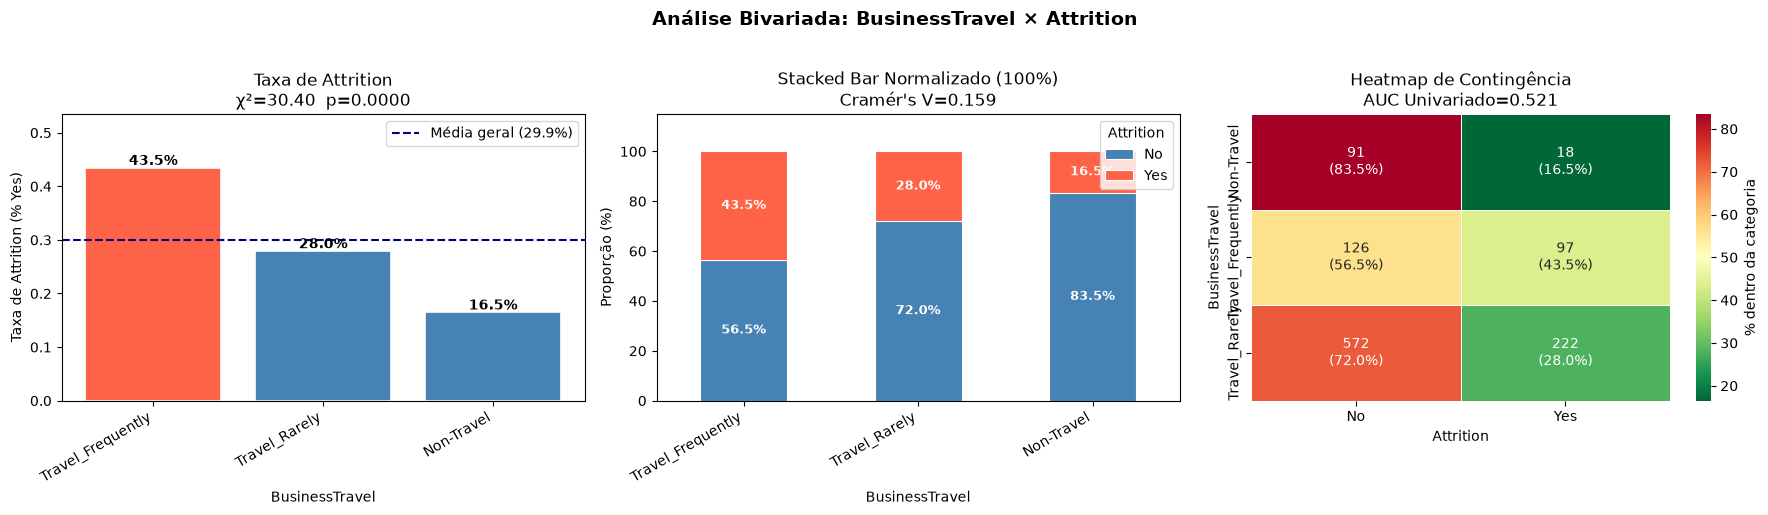

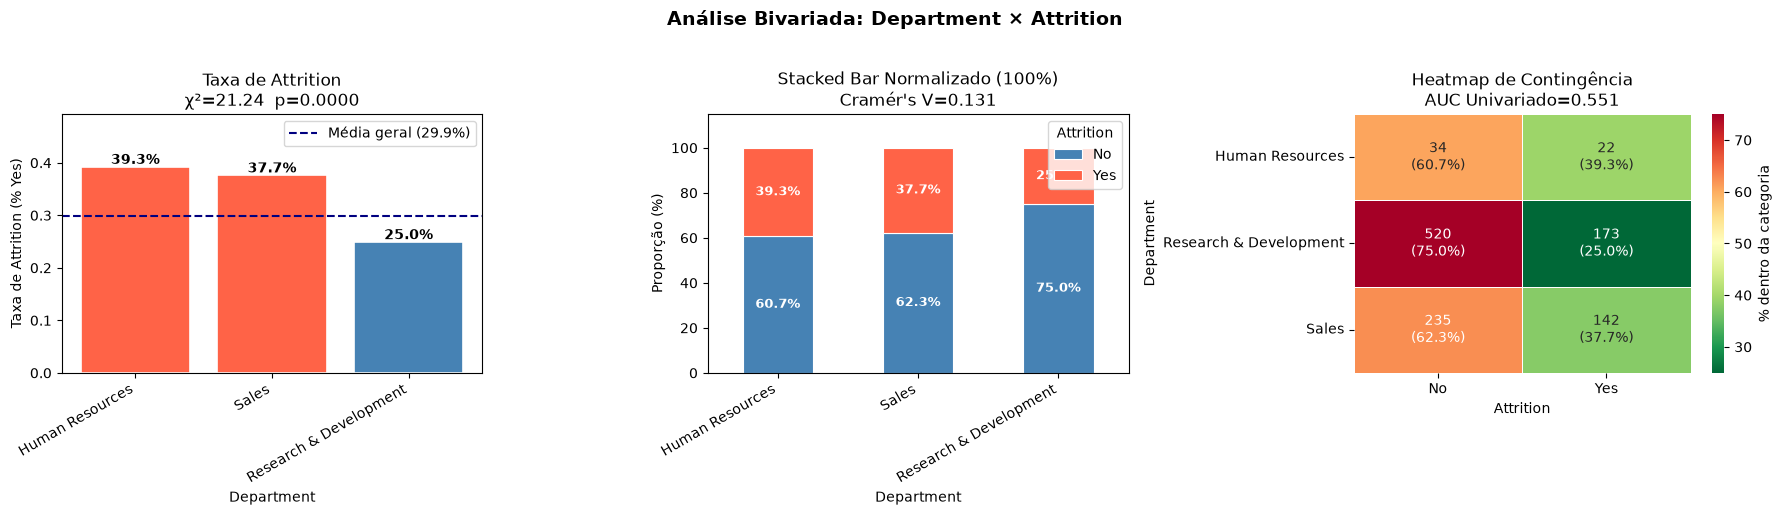

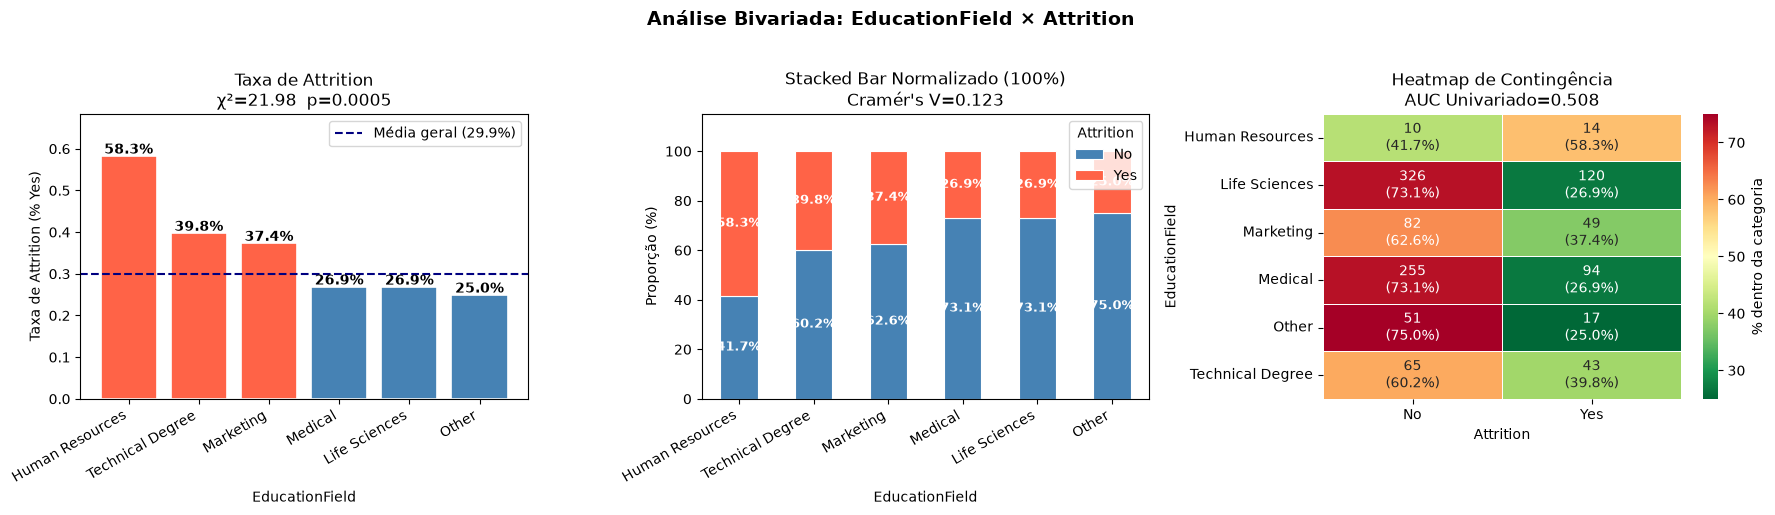

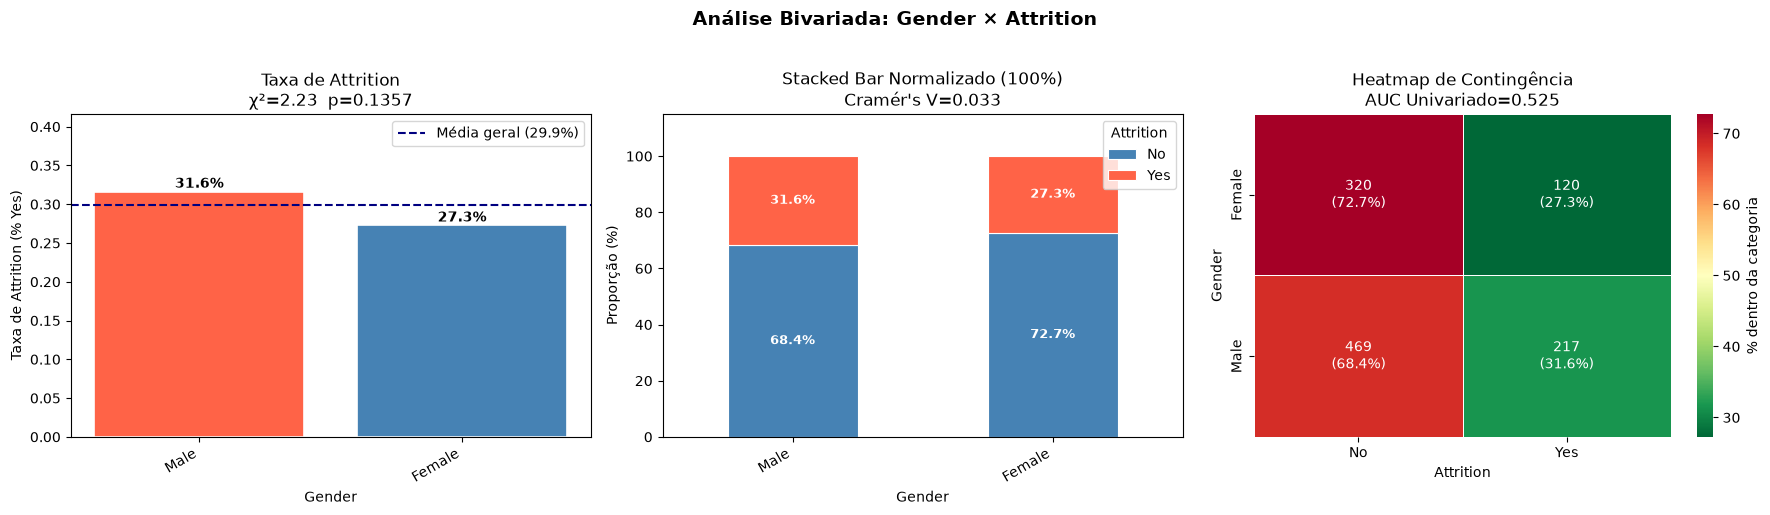

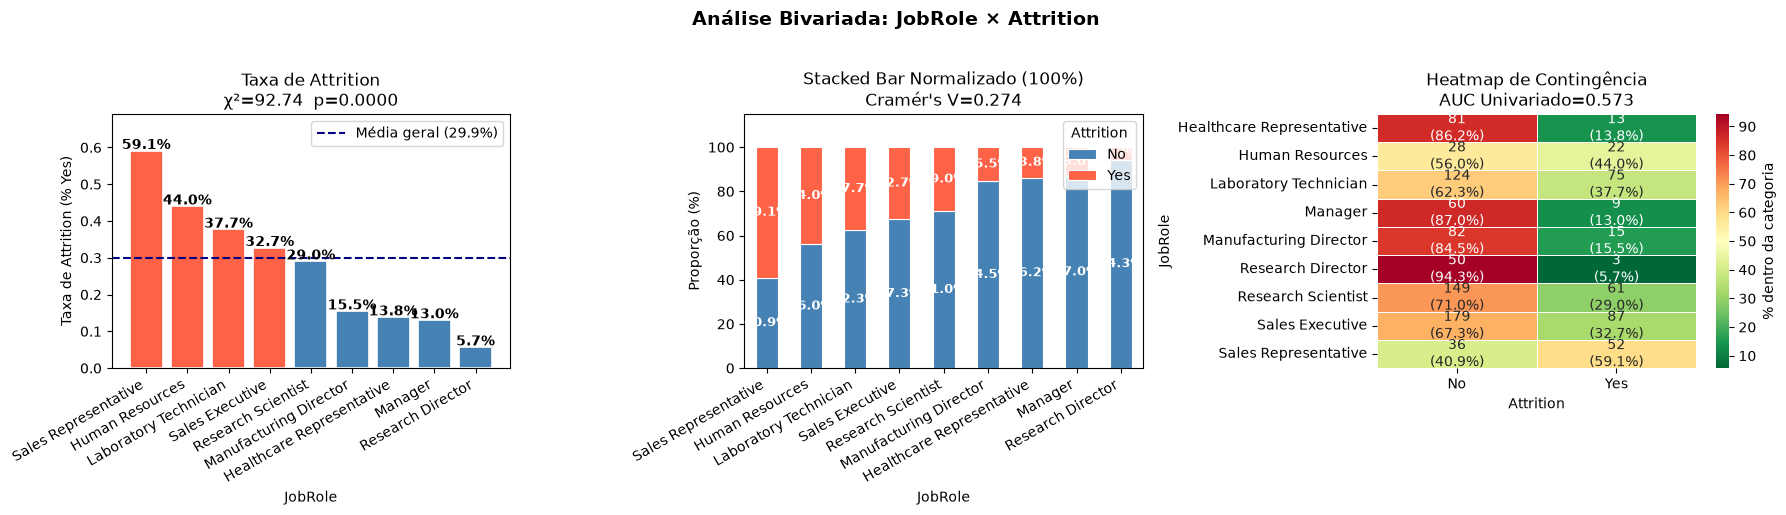

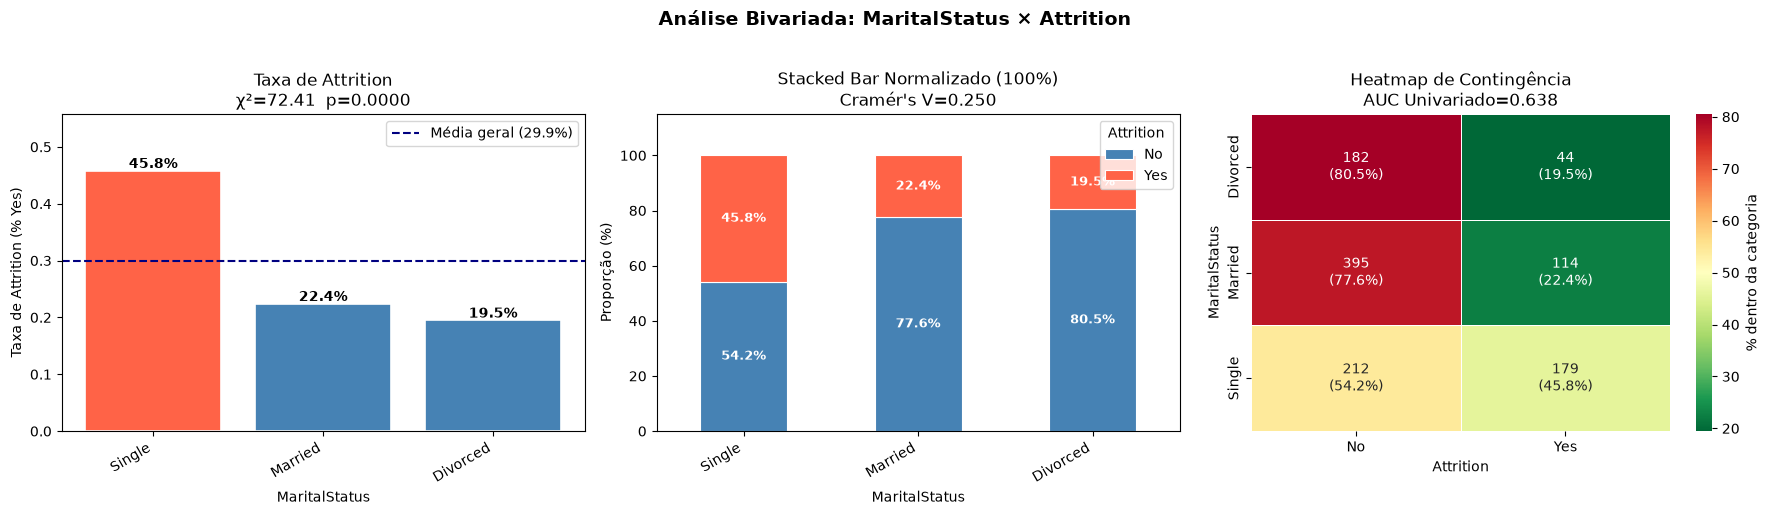

[skip] Over18: coluna constante, sem análise bivariada.


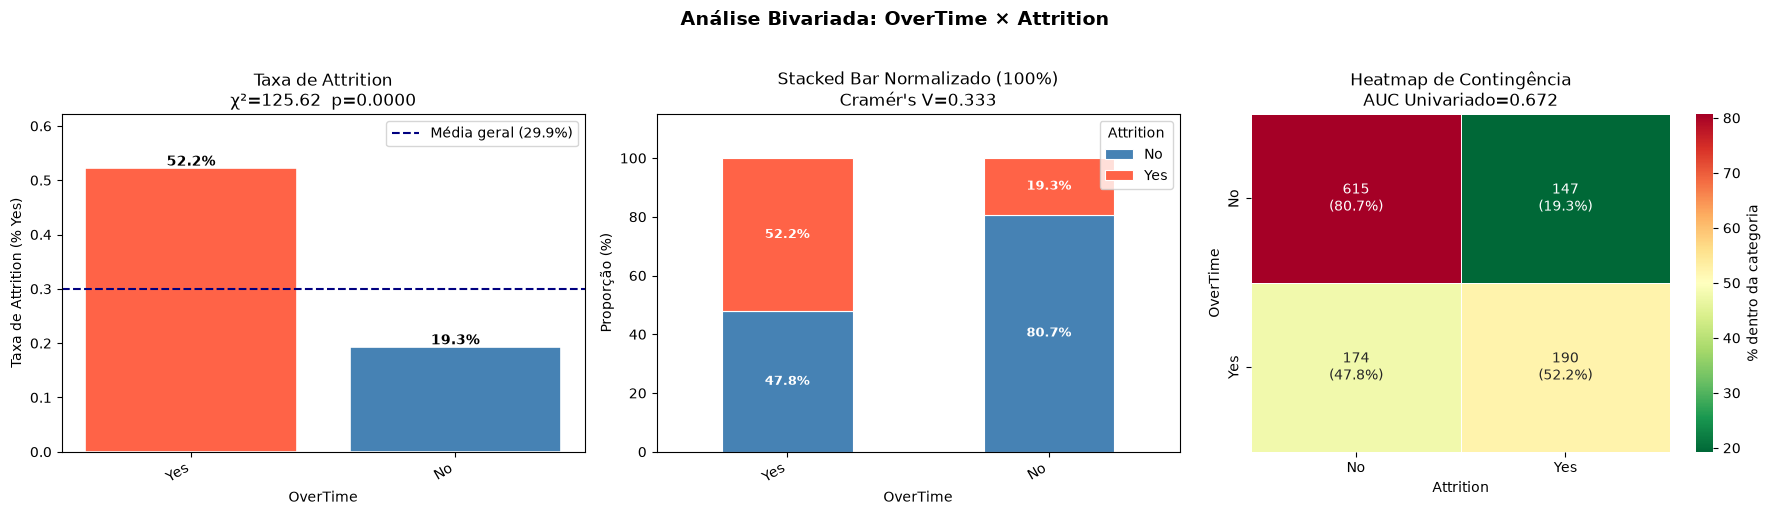

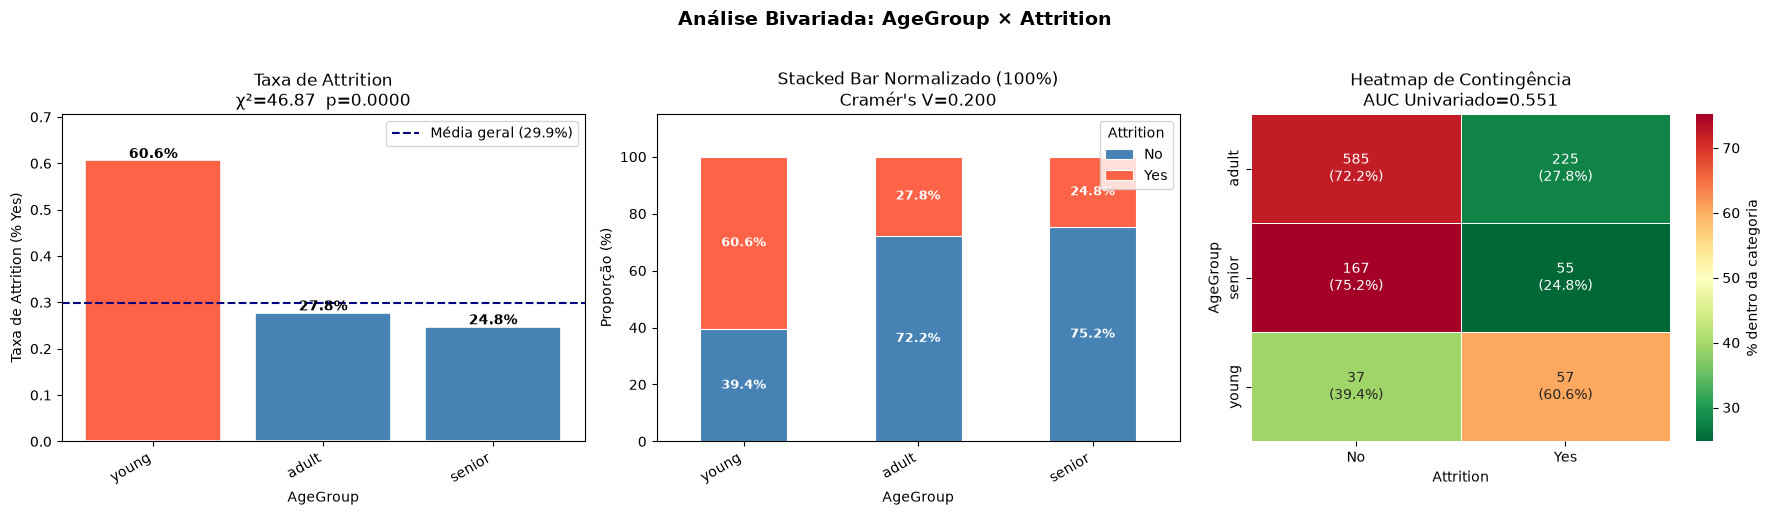

In [26]:
col_target = 'Attrition'

if df_train[col_target].dtype == object:
    y_binary = (df_train[col_target] == 'Yes').astype(int)
else:
    y_binary = df_train[col_target].astype(int)

# versão com rótulo legível No/Yes para os gráficos
df_plot = df_train.copy()
df_plot[col_target] = y_binary.map({0: 'No', 1: 'Yes'})

cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != col_target]

taxa_geral = y_binary.mean()

for col in cat_cols:
    if df_train[col].nunique(dropna=True) <= 1:
        print(f"[skip] {col}: coluna constante, sem análise bivariada.")
        continue

    # métricas só para exibir nos títulos
    contingency = pd.crosstab(df_plot[col], df_plot[col_target])
    chi2, p_value, _, _ = chi2_contingency(contingency)
    cv = cramers_v(df_plot[col], df_plot[col_target])

    X_enc = LabelEncoder().fit_transform(df_train[col]).reshape(-1, 1)
    model = LogisticRegression(max_iter=300).fit(X_enc, y_binary)
    auc = roc_auc_score(y_binary, model.predict_proba(X_enc)[:, 1])
    auc = max(auc, 1 - auc)

    attrition_rate = (
        df_plot.groupby(col)[col_target]
        .apply(lambda x: (x == 'Yes').mean())
        .sort_values(ascending=False)
        .reset_index()
    )
    attrition_rate.columns = [col, 'Taxa Attrition']

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {col_target}',
                 fontsize=14, fontweight='bold', y=1.02)

    # ── Plot 1: Taxa de Attrition por categoria ──────────────────────────
    bars = axes[0].bar(
        attrition_rate[col], attrition_rate['Taxa Attrition'],
        color=['tomato' if v > taxa_geral else 'steelblue'
               for v in attrition_rate['Taxa Attrition']],
        edgecolor='white', linewidth=1.2
    )
    axes[0].axhline(taxa_geral, color='navy', linestyle='--',
                    linewidth=1.5, label=f'Média geral ({taxa_geral:.1%})')
    for bar, val in zip(bars, attrition_rate['Taxa Attrition']):
        axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                     f'{val:.1%}', ha='center', fontsize=10, fontweight='bold')
    axes[0].set_title(f'Taxa de Attrition\nχ²={chi2:.2f}  p={p_value:.4f}')
    axes[0].set_xlabel(col); axes[0].set_ylabel('Taxa de Attrition (% Yes)')
    axes[0].set_ylim(0, attrition_rate['Taxa Attrition'].max() + 0.1)
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
    axes[0].legend()

    # ── Plot 2: Stacked Bar 100% normalizado ─────────────────────────────
    stacked = (
        pd.crosstab(df_plot[col], df_plot[col_target], normalize='index') * 100
    ).loc[attrition_rate[col]]   # mesma ordem do plot 1

    stacked[['No', 'Yes']].plot(
        kind='bar', stacked=True, ax=axes[1],
        color=['steelblue', 'tomato'], edgecolor='white', linewidth=0.8
    )
    for idx, (_, row_data) in enumerate(stacked.iterrows()):
        axes[1].text(idx, row_data['No'] / 2, f"{row_data['No']:.1f}%",
                     ha='center', va='center', color='white', fontsize=9, fontweight='bold')
        axes[1].text(idx, row_data['No'] + row_data['Yes'] / 2, f"{row_data['Yes']:.1f}%",
                     ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    axes[1].set_title(f"Stacked Bar Normalizado (100%)\nCramér's V={cv:.3f}")
    axes[1].set_xlabel(col); axes[1].set_ylabel('Proporção (%)')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')
    axes[1].legend(title='Attrition', loc='upper right')
    axes[1].set_ylim(0, 115)

    # ── Plot 3: Heatmap de contingência ──────────────────────────────────
    cont_abs = pd.crosstab(df_plot[col], df_plot[col_target])
    cont_pct = pd.crosstab(df_plot[col], df_plot[col_target], normalize='index') * 100
    annot = cont_abs.astype(str) + '\n(' + cont_pct.round(1).astype(str) + '%)'

    sns.heatmap(cont_pct, annot=annot, fmt='', cmap='RdYlGn_r',
                ax=axes[2], linewidths=0.5,
                cbar_kws={'label': '% dentro da categoria'},
                annot_kws={'size': 10})
    axes[2].set_title(f'Heatmap de Contingência\nAUC Univariado={auc:.3f}')
    axes[2].set_xlabel(col_target); axes[2].set_ylabel(col)

    plt.tight_layout()
    plt.show()
    plt.close(fig)


## 6.3 Multivariate Analysis

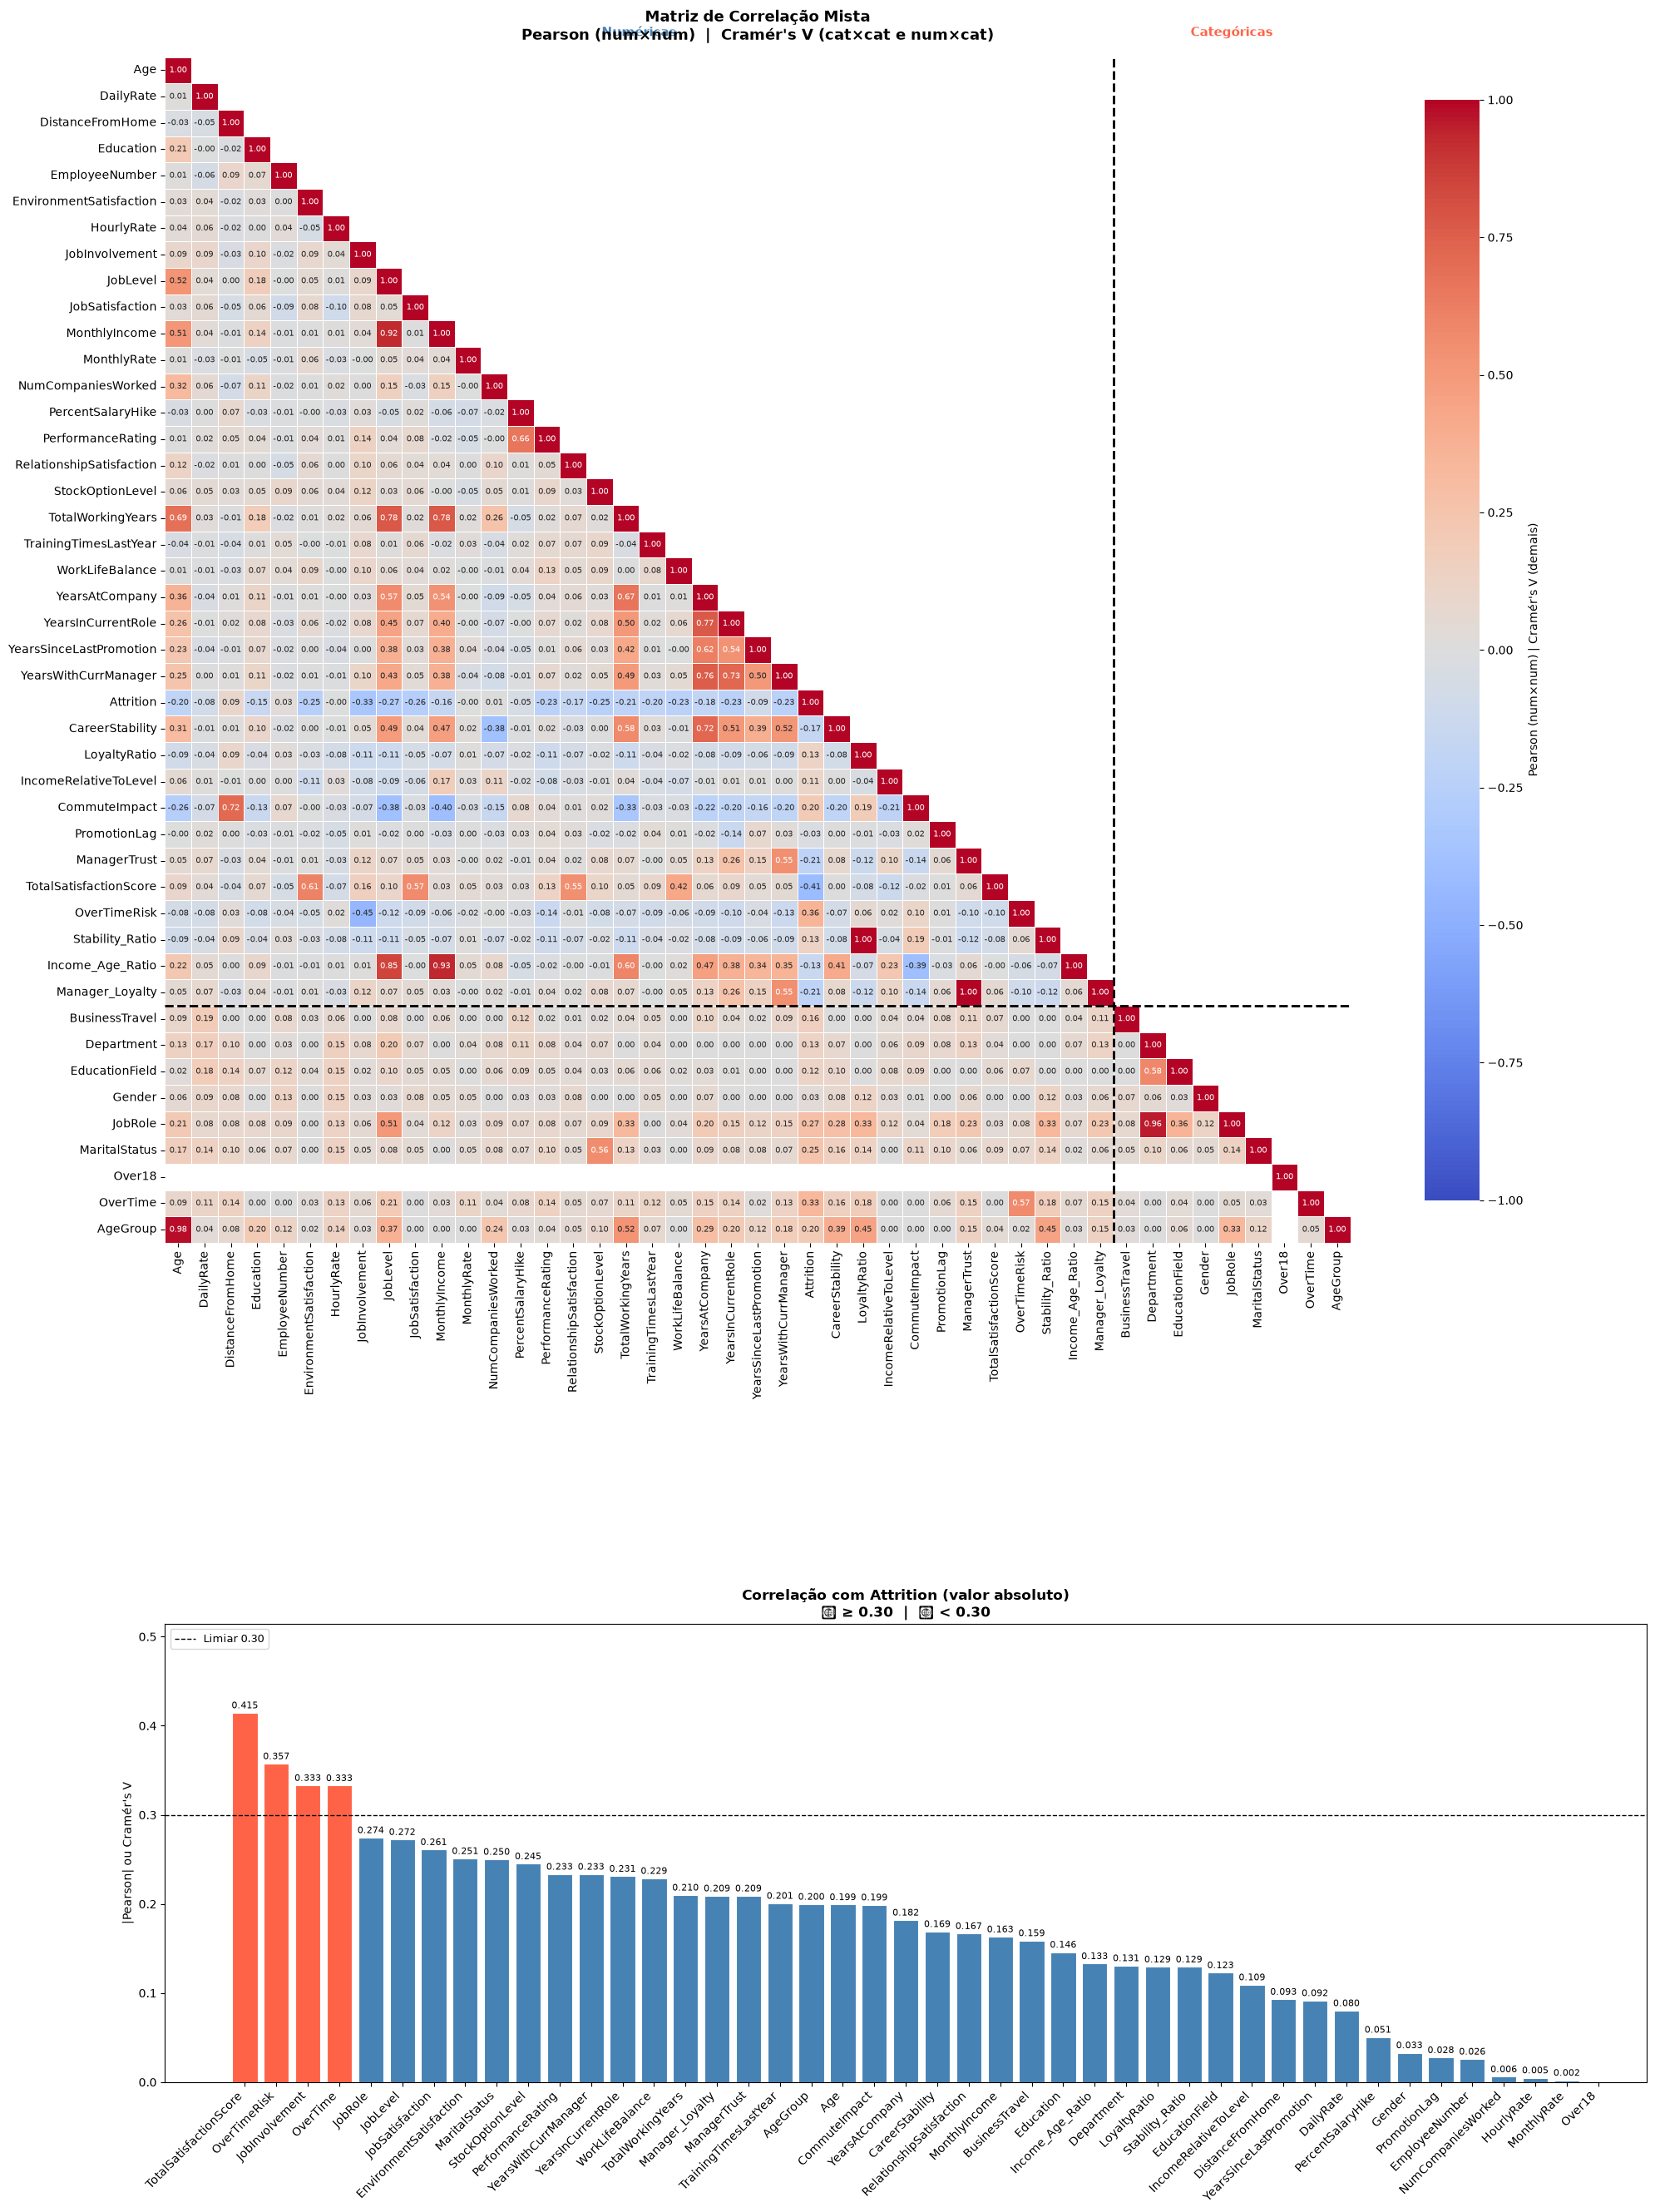


TOP CORRELAÇÕES COM ATTRITION
TotalSatisfactionScore      0.414594
OverTimeRisk                0.357441
JobInvolvement              0.333055
OverTime                    0.332832
JobRole                     0.274435
JobLevel                    0.272372
JobSatisfaction             0.261067
EnvironmentSatisfaction     0.251012
MaritalStatus               0.250162
StockOptionLevel            0.245164
PerformanceRating           0.233447
YearsWithCurrManager        0.233385
YearsInCurrentRole          0.231159
WorkLifeBalance             0.228730
TotalWorkingYears           0.210016
Manager_Loyalty             0.209088
ManagerTrust                0.209087
TrainingTimesLastYear       0.200772
AgeGroup                    0.199707
Age                         0.199262
CommuteImpact               0.198995
YearsAtCompany              0.181961
CareerStability             0.169098
RelationshipSatisfaction    0.166795
MonthlyIncome               0.163187
BusinessTravel              0.158879
Educati

In [27]:
# ================================================
# Matriz de Correlação Mista: Pearson + Cramér's V 
# Cramer's V para dados categóricos
# ================================================

num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
all_cols = num_cols + cat_cols

n = len(all_cols)
corr_matrix = pd.DataFrame(np.zeros((n, n)), index=all_cols, columns=all_cols)

for col_a in all_cols:
    for col_b in all_cols:

        a_is_num = col_a in num_cols
        b_is_num = col_b in num_cols

        if col_a == col_b:
            corr_matrix.loc[col_a, col_b] = 1.0

        elif a_is_num and b_is_num:
            corr_matrix.loc[col_a, col_b] = df_train[col_a].corr(df_train[col_b])

        else:
            v = cramers_v(df_train[col_a].astype(str), df_train[col_b].astype(str))
            corr_matrix.loc[col_a, col_b] = v
            corr_matrix.loc[col_b, col_a] = v

corr_matrix = corr_matrix.astype(float)

# ── Visualização: 2 linhas × 1 coluna ────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(20, 30),
                          gridspec_kw={'height_ratios': [4, 1]})

# ── Plot 1: Heatmap completo ──────────────────────────────────────────────
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    ax=axes[0],
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    annot=True, fmt='.2f',
    annot_kws={'size': 7},
    linewidths=0.4,
    square=True,
    cbar_kws={'label': "Pearson (num×num) | Cramér's V (demais)", 'shrink': 0.6}
)

n_num = len(num_cols)
axes[0].axhline(n_num, color='black', linewidth=2, linestyle='--')
axes[0].axvline(n_num, color='black', linewidth=2, linestyle='--')

axes[0].text(n_num / 2, -0.8, 'Numéricas', ha='center',
             fontsize=11, fontweight='bold', color='steelblue')
axes[0].text(n_num + len(cat_cols) / 2, -0.8, 'Categóricas', ha='center',
             fontsize=11, fontweight='bold', color='tomato')

axes[0].set_title("Matriz de Correlação Mista\nPearson (num×num)  |  Cramér's V (cat×cat e num×cat)",
                   fontsize=13, fontweight='bold', pad=15)
axes[0].tick_params(axis='x', rotation=90)
axes[0].tick_params(axis='y', rotation=0)

# ── Plot 2: Ranking de correlação com Attrition ───────────────────────────
if 'Attrition' in all_cols:
    attrition_corr = (
        corr_matrix['Attrition']
        .drop('Attrition')
        .abs()
        .sort_values(ascending=False)
    )

    colors = ['tomato' if v >= 0.3 else 'steelblue' for v in attrition_corr.values]

    axes[1].bar(attrition_corr.index, attrition_corr.values,
                color=colors, edgecolor='white', linewidth=0.8)
    axes[1].axhline(0.3, color='black', linestyle='--',
                    linewidth=1, label='Limiar 0.30')

    for i, (feat, val) in enumerate(attrition_corr.items()):
        axes[1].text(i, val + 0.005, f'{val:.3f}',
                     ha='center', fontsize=8, color='black')

    axes[1].set_title("Correlação com Attrition (valor absoluto)\n🔴 ≥ 0.30  |  🔵 < 0.30",
                       fontsize=12, fontweight='bold')
    axes[1].set_ylabel("|Pearson| ou Cramér's V")
    axes[1].set_xticks(range(len(attrition_corr)))
    axes[1].set_xticklabels(attrition_corr.index, rotation=45, ha='right')
    axes[1].set_ylim(0, attrition_corr.max() + 0.1)
    axes[1].legend(fontsize=9)

plt.tight_layout(h_pad=4)
plt.show()

# --- Resumo textual ---
print(f"\n{'='*50}")
print("TOP CORRELAÇÕES COM ATTRITION")
print(f"{'='*50}")
print(attrition_corr.to_string())


In [28]:
import numpy as np
import pandas as pd

col_target = 'Attrition'
LIMIAR = 0.75

# features numéricas, sem o alvo
num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c != col_target]

# matriz de correlação (absoluta)
corr = df_train[num_cols].corr().abs()

# pega só o triângulo superior para não repetir pares (A-B e B-A) nem a diagonal (A-A = 1)
triangulo_sup = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

# monta a lista de pares acima do limiar
pares_colineares = (
    triangulo_sup.stack()                       # vira série (feature1, feature2) -> corr
    .reset_index()
    .rename(columns={'level_0': 'Feature_1', 'level_1': 'Feature_2', 0: 'Correlacao'})
    .query('Correlacao >= @LIMIAR')
    .sort_values('Correlacao', ascending=False)
    .reset_index(drop=True)
)

pares_colineares


,Feature_1,Feature_2,Correlacao
0,ManagerTrust,Manager_Loyalty,1.000000
1,LoyaltyRatio,Stability_Ratio,1.000000
2,MonthlyIncome,Income_Age_Ratio,0.930215
3,JobLevel,MonthlyIncome,0.922731
4,JobLevel,Income_Age_Ratio,0.849602
5,JobLevel,TotalWorkingYears,0.779806
6,MonthlyIncome,TotalWorkingYears,0.775427
7,YearsAtCompany,YearsInCurrentRole,0.770130
8,YearsAtCompany,YearsWithCurrManager,0.758649


In [29]:
# correlação (absoluta) de cada feature com o alvo
# Attrition precisa estar numérico (0/1) para entrar no corr
if df_train[col_target].dtype == object:
    y_num = (df_train[col_target] == 'Yes').astype(int)
else:
    y_num = df_train[col_target].astype(int)

corr_com_alvo = df_train[num_cols].corrwith(y_num).abs()

# para cada par colinear, remove a de MENOR correlação com o alvo
colunas_multicolineares = set()
for _, row in pares_colineares.iterrows():
    f1, f2 = row['Feature_1'], row['Feature_2']
    corr1 = corr_com_alvo.get(f1, 0)
    corr2 = corr_com_alvo.get(f2, 0)
    # mantém a de maior correlação com o alvo, remove a menor
    colunas_multicolineares.add(f2 if corr1 >= corr2 else f1)

colunas_multicolineares = list(colunas_multicolineares)
colunas_multicolineares



['Stability_Ratio',
 'YearsAtCompany',
 'ManagerTrust',
 'Income_Age_Ratio',
 'MonthlyIncome',
 'TotalWorkingYears']

# 7.0 Feature Selection

- Seleção de features
- Eliminação de features com ruidos para o modelo

## 7.1 Filter method

In [30]:
# Remove variáveis com variância abaixo do threshold
selector = VarianceThreshold(threshold=0.01)
X_filtered = selector.fit_transform(df_train[train_num_attributes])

# Verificar variância manualmente
variances = df_train[train_num_attributes].var()
low_var_cols = variances[variances < 0.01].index.tolist()
print("Variáveis com variância quasi-zero:", low_var_cols)

Variáveis com variância quasi-zero: ['CommuteImpact']


In [31]:
# junta todas as fontes de features a remover e elimina duplicatas
drop_vars = list(set(
    low_var_cols
    + low_discrimination_train_num_univars
    + low_discrimination_train_cat_univars 
    + low_discrimination_train_num_bivars 
    + low_discrimination_train_cat_bivars
))

print(f"Total de features a remover: {len(drop_vars)}")
print(f"\nFeatures que serão removidas:\n{drop_vars}")


Total de features a remover: 12

Features que serão removidas:
['EmployeeNumber', 'BusinessTravel', 'Over18', 'Gender', 'MonthlyRate', 'PercentSalaryHike', 'EducationField', 'IncomeRelativeToLevel', 'DistanceFromHome', 'NumCompaniesWorked', 'HourlyRate', 'CommuteImpact']


## 7.2 Boruta

In [32]:
# preparacao dados
X = df_train.drop( columns='Attrition' )
y = df_train['Attrition'].apply( lambda x: 1 if x == 1 else 0 )

X_boruta = pd.get_dummies( X, prefix_sep='__SEP__' )

# algoritmo
rf_boruta = en.RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=42)

# boruta
boruta = BorutaPy( rf_boruta, 
                   n_estimators='auto',
                   verbose=2,
                   random_state=42
).fit( X_boruta.values, y.values )

# resultados
confirmed_boruta = X_boruta.columns[boruta.support_].tolist()
tentative_boruta = X_boruta.columns[boruta.support_weak_].tolist()
rejected_boruta = X_boruta.columns[~boruta.support_ & ~boruta.support_weak_].tolist()

# --- Reverter dummies para nome original
def to_original( col ):
    return col.split( '__SEP__' )[0] if '__SEP__' in col else col

confirmed_boruta = sorted( set( to_original( c ) for c in confirmed_boruta ) )
tentative_boruta = sorted( set( to_original( c ) for c in tentative_boruta ) )
rejected_boruta  = sorted( set( to_original( c ) for c in rejected_boruta ) )

# Categórica só é "rejeitada" se TODAS as suas dummies foram rejeitadas.
# Se ao menos uma dummy foi confirmada/tentativa, removemos a original da lista de rejeitadas.
rejected_boruta = [ c for c in rejected_boruta
                      if c not in confirmed_boruta and c not in tentative_boruta ]

print( f'Variaveis confirmadas (originais): {confirmed_boruta}' )
print( f'Variaveis tentativas (originais):  {tentative_boruta}' )
print( f'Variaveis rejeitadas (originais):  {rejected_boruta}' )


# --- 1) Filter Method
rejected_columns = ( drop_vars
                    + rejected_boruta )

Iteration: 	1 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	2 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	3 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	4 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	5 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	6 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	7 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	8 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	9 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	10 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	11 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	12 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	13 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	14 / 100
Confirmed: 	29
Tentative: 	8
Rejected: 	30
Iteration: 	15 / 100
Confirmed: 	29
Tentative: 	8
Rejected: 	30
Iteration: 	16 / 100
Confirmed: 	30
Tentative: 	7
Reject

In [33]:
# dropando as variaveis rejeitadas pelo boruta
df_train_cleaned = df_train.drop( columns=rejected_columns )
df_val_cleaned = df_val.drop(columns = rejected_columns)

## 7.3 RFE

In [34]:
from sklearn.feature_selection import RFE, RFECV
from sklearn.ensemble import RandomForestClassifier


# Preparação simplificada para o Boruta (Encoding Temporário)
X = df_train.drop(columns=['Attrition'])
y = df_train['Attrition'].apply(lambda x: 1 if x == 1 else 0)

X_rfe = pd.get_dummies(X)

# RFE com número fixo de features
rf_rfe = RandomForestClassifier(n_estimators=100, random_state=42)
rfe = RFE(estimator=rf_rfe, n_features_to_select=10, step=1)
rfe.fit(X_rfe, y)

features_selecionadas = X_rfe.columns[rfe.support_].tolist()
print("Features selecionadas pelo RFE:", features_selecionadas)

# RFECV: encontra automaticamente o número ótimo via cross-validation
rfecv = RFECV(
    estimator=rf_rfe,
    step=1,
    cv=5,
    scoring='roc_auc',
    min_features_to_select=5
)
rfecv.fit(X_rfe, y)

print(f"Número ótimo de features: {rfecv.n_features_}")
print("Features:", X_rfe.columns[rfecv.support_].tolist())

Features selecionadas pelo RFE: ['MonthlyIncome', 'PerformanceRating', 'StockOptionLevel', 'TotalWorkingYears', 'CareerStability', 'IncomeRelativeToLevel', 'CommuteImpact', 'TotalSatisfactionScore', 'OverTimeRisk', 'Income_Age_Ratio']
Número ótimo de features: 67
Features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'CareerStability', 'LoyaltyRatio', 'IncomeRelativeToLevel', 'CommuteImpact', 'PromotionLag', 'ManagerTrust', 'TotalSatisfactionScore', 'OverTimeRisk', 'Stability_Ratio', 'Income_Age_Ratio', 'Manager_Loyalty', 'BusinessTravel_Non-Travel', 'BusinessTravel_Travel_Fre

# 8.0 Data Preparation

In [35]:
X_train_processed = df_train_cleaned.drop('Attrition', axis=1)
y_train_processed = df_train_cleaned['Attrition']

X_val_processed = df_val_cleaned.drop('Attrition', axis=1)
y_val_processed = df_val_cleaned['Attrition']

In [36]:
train_num_cols = X_train_processed.select_dtypes( include=['int64', 'float64'] ).columns.tolist()
train_cat_cols = X_train_processed.select_dtypes( include=['object'] ).columns.tolist()

## 8.1 Normalização e Rescala de dados númericos

### 8.1.1 Teste de normalidade

In [37]:
results_norm = []
for col in train_num_cols:
    series = X_train_processed[col].dropna()   # <- DataFrame, não a lista

    # Shapiro-Wilk
    _, sw_p = stats.shapiro(series)

    # Kolmogorov-Smirnov vs normal padronizada
    z = (series - series.mean()) / series.std(ddof=0)
    _, ks_p = stats.kstest(z, 'norm')

    results_norm.append({
        'Feature': col,
        'Shapiro_p': sw_p,
        'KS_p': ks_p,
        'Normal_alpha_0.05': 'Yes' if (sw_p > 0.05) and (ks_p > 0.05) else 'No'
    })

df_normality = pd.DataFrame(results_norm).sort_values(by='Shapiro_p', ascending=False)

df_normality.style.format({
    'Shapiro_p': '{:.4f}',
    'KS_p': '{:.4f}'
}).background_gradient(subset=['Shapiro_p', 'KS_p'], cmap='RdYlGn')


,Feature,Shapiro_p,KS_p,Normal_alpha_0.05
0,Age,0.0000,0.0000,No
19,TotalSatisfactionScore,0.0000,0.0000,No
1,DailyRate,0.0000,0.0000,No
11,TrainingTimesLastYear,0.0000,0.0000,No
10,TotalWorkingYears,0.0000,0.0000,No
23,Manager_Loyalty,0.0000,0.0000,No
18,ManagerTrust,0.0000,0.0000,No
22,Income_Age_Ratio,0.0000,0.0000,No
14,YearsInCurrentRole,0.0000,0.0000,No
15,YearsWithCurrManager,0.0000,0.0000,No


- Shapiro_p ≈ 0.0 (ou < 0.05) → rejeita a hipótese de normalidade → não é normal.
- Normal_alpha_0.05 = 'No' → confirma: não é normal.

- Todas variáveis nao normais - Aplicar um Robust Scaler 

### 8.1.2 Scalers

In [38]:
rs = pp.RobustScaler()

# train_num_cols já pega int64 E float64 (definido na célula anterior)
X_train_processed[train_num_cols] = rs.fit_transform(X_train_processed[train_num_cols])
X_val_processed[train_num_cols]   = rs.transform(X_val_processed[train_num_cols])


## 8.2 Encoders de dados categóricos

In [39]:
# Ver quais os nomes de todas as classes em train_cat_cols

df_train_cleaned[train_cat_cols].describe().T

,count,unique,top,freq
MaritalStatus,1126,3,Married,509
OverTime,1126,2,No,762


In [40]:
# One hot Encoder
one_hot_cols = train_cat_cols
ohe = pp.OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='if_binary') # Drop binário dropa colunas 0 ou 1, reduzindo uma coluna, pois coluna de 0 e 1 nao precisam serem convertidas em 2 colunas

X_train_encoded = ohe.fit_transform(X_train_processed[one_hot_cols])

X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=ohe.get_feature_names_out(one_hot_cols),
    index=X_train_processed.index
)

X_val_encoded = ohe.transform(X_val[one_hot_cols])
X_val_encoded_df = pd.DataFrame(
    X_val_encoded,
    columns=ohe.get_feature_names_out(one_hot_cols),
    index=X_val.index
)

X_train_processed = pd.concat([X_train_processed.drop(columns=one_hot_cols), X_train_encoded_df], axis=1)
X_val_processed = pd.concat([X_val_processed.drop(columns=one_hot_cols), X_val_encoded_df], axis=1)

# 9.0 Machine Learning Modeling

In [41]:
def ml_metrics( model_name, y_true, y_prob, threshold=0.5):
    y_pred = [ 1 if x > threshold else 0 for x in y_prob ]
    acc = mt.accuracy_score( y_true, y_pred )
    f1 = mt.f1_score( y_true, y_pred, zero_division=0 )
    prec = mt.precision_score( y_true, y_pred, zero_division=0 )
    rec = mt.recall_score( y_true, y_pred, zero_division=0 )
    auc = mt.roc_auc_score( y_true, y_prob )

    return pd.DataFrame({
        'Model Name': model_name,
        'Accuracy': acc,
        'F1-Score': f1,
        'Precision': prec,
        'Recall': rec,
        'AUC': auc
    }, index=[0] )

## 9.1 Baseline Model

O baseline é o **piso de desempenho**: um modelo "burro" que não aprende padrão nenhum dos dados. Ele serve de referência — qualquer modelo de verdade (Logistic Regression, Random Forest, etc.) só justifica sua complexidade se ficar **claramente acima** do baseline.

Usamos o `DummyClassifier` do sklearn, que implementa justamente esses chutes de referência:

- **`strategy='stratified'`**: gera previsões **aleatórias, mas respeitando a proporção das classes do treino**. Como ~30% da base é turnover, ele sorteia "vai sair" com ~30% de probabilidade e "fica" com ~70%. É o equivalente a um chute honesto que conhece só a frequência das classes, nada mais.
- **`fit(X_train, y_train)`**: o Dummy não olha para as features `X` — ele apenas **memoriza a proporção das classes** em `y_train`. É isso que o `fit` faz aqui.
- **`predict_proba(...)[:, 1]`**: retorna a probabilidade da **classe positiva** (sair = 1), no mesmo formato dos outros modelos, para o `ml_metrics` conseguir calcular AUC.
- **`random_state=42`**: fixa a semente do sorteio para o resultado ser **reprodutível** (sem isso, as métricas mudariam a cada execução).

**Como ler o resultado:** espera-se um **AUC próximo de 0.50**, que é a assinatura do acaso — o modelo não separa quem sai de quem fica. Esse 0.50 é a linha de corte: na comparação final, todo modelo útil tem que ter AUC bem acima disso.

> Alternativas de `strategy`: `'most_frequent'` (prevê sempre a classe majoritária — accuracy alta mas **recall 0**, bom para mostrar como accuracy engana em base desbalanceada) e `'prior'` (probabilidade constante igual à taxa de eventos, ~0.30 para todos).

In [42]:
# Definição
# strategy='stratified' -> sorteia respeitando a proporção das classes do treino
# (alternativas: 'prior'/'most_frequent' -> sempre a classe majoritária)
dummy = DummyClassifier(strategy='stratified', random_state=42)

# Treinamento
dummy.fit(X_train_processed, y_train_processed)

# Previsão (probabilidade da classe positiva) no treino e na validação
yhat_baseline_train = dummy.predict_proba(X_train_processed)[:, 1]
yhat_baseline_val = dummy.predict_proba(X_val_processed)[:, 1]

# Desempenho
baseline_train = ml_metrics('Baseline Train', y_train_processed, yhat_baseline_train)
baseline_val = ml_metrics('Baseline Val', y_val_processed, yhat_baseline_val)

baseline = pd.concat( [baseline_train, baseline_val] )
baseline

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Baseline Train,0.564831,0.270833,0.271642,0.270030,0.480389
0,Baseline Val,0.567376,0.298851,0.292135,0.305882,0.493043


## 9.2 Logistic Regression

**Regressão Logística** - modelo linear, o mais simples e interpretável dos classificadores.

- **Ideia:** combina as features em uma soma ponderada (`w₁·x₁ + w₂·x₂ + ... + b`) e passa o resultado pela função **sigmoide**, que esmaga qualquer número para o intervalo 0-1, virando probabilidade.
- **O que aprende:** os pesos `w` de cada feature. Peso positivo empurra a probabilidade de sair para cima, negativo para baixo.
- **Fronteira de decisão:** é uma **reta** (ou hiperplano). Só separa bem o que é linearmente separável — não captura interações complexas sozinha.
- **Pré-requisitos:** sensível à escala das features (por isso o scaler importa) e assume que o efeito de cada variável é aproximadamente linear no log-odds.
- **Forças:** rápida, interpretável (dá para ler a importância pelos pesos), ótimo baseline "de verdade".
- **Fraquezas:** limitada em padrões não-lineares; costuma perder para modelos de árvore em dados tabulares complexos.

In [43]:
# Definição
lr_model = LogisticRegression(           # C = 1/λ → inverso da regularização L2
    solver='lbfgs',     # otimizador (quasi-Newton)
    max_iter=1000,      # máximo de iterações
    class_weight = "balanced",
    random_state=42
)

# Treinamento
lr_model.fit(X_train_processed, y_train_processed)

# # Acessar os coeficientes aprendidos
# print("Pesos (W):", lr_model.coef_)
# print("Bias (b):", lr_model.intercept_)
# print("#"*60)

# Previsão
y_hat_lr_train  = lr_model.predict_proba(X_train_processed)[:, 1]  # P(y=1)
y_hat_lr_val  = lr_model.predict_proba(X_val_processed)    [:,1]          # classe predita

# Desempenho
lr_train = ml_metrics("Logistic Regression Train", y_train_processed, y_hat_lr_train, threshold=0.5022)
lr_val = ml_metrics("Logistic Regression Val", y_val_processed, y_hat_lr_val, threshold=0.5022)

lr = pd.concat([lr_train, lr_val])
lr

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Logistic Regression Train,0.849911,0.766252,0.717617,0.821958,0.909482
0,Logistic Regression Val,0.826241,0.737968,0.676471,0.811765,0.889221


## 9.3 Random Forest

**Random Forest** - ensemble de muitas árvores de decisão treinadas **em paralelo** (técnica de *bagging*).

- **Ideia:** treina N árvores independentes, cada uma em uma amostra aleatória dos dados (*bootstrap*) e usando um subconjunto aleatório de features. A previsão final é a **média/voto** de todas as árvores.
- **Por que funciona:** cada árvore sozinha erra de um jeito diferente; ao combinar muitas, os erros aleatórios se cancelam e **reduz a variância** (menos overfitting que uma árvore só).
- **Fronteira de decisão:** não-linear, feita de cortes retangulares - captura interações entre variáveis sem precisar que você as crie na mão.
- **Escala:** **não precisa** de normalização - árvores só comparam "maior/menor que um limiar".
- **Forças:** robusta, pouca necessidade de tuning, lida bem com features irrelevantes, dá importância de variáveis.
- **Fraquezas:** modelo "caixa-preta" (menos interpretável), pode ficar pesado em memória, e com árvores sem limite de profundidade memoriza o treino (veja o train = 1.0).

In [44]:
# Definição
rf = RandomForestClassifier(
    n_jobs=-1, 
    n_estimators = 100,
    class_weight = 'balanced',
    random_state=42)

# Treinamento
rf.fit(X_train_processed, y_train_processed)

# Previsão
y_hat_rf_train  = rf.predict_proba(X_train_processed)[:, 1]  # P(y=1)
y_hat_rf_val  = rf.predict_proba(X_val_processed)    [:,1]          # classe predita

# Desempenho
rf_train = ml_metrics("Random Forest Train", y_train_processed, y_hat_rf_train, threshold=0.5)
rf_val = ml_metrics("Random Forest Val", y_val_processed, y_hat_rf_val, threshold=0.5)

rf = pd.concat([rf_train, rf_val])
rf

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Random Forest Train,1.000000,1.000000,1.000000,1.000000,1.000000
0,Random Forest Val,0.861702,0.757764,0.802632,0.717647,0.901642


## 9.4 XGBOOST

**XGBoost** - ensemble de árvores treinadas **em sequência** (técnica de *boosting*).

- **Ideia:** ao contrário da Random Forest (paralela), aqui cada nova árvore é treinada para **corrigir os erros** (resíduos) das árvores anteriores. O modelo vai refinando a previsão passo a passo.
- **Como aprende:** usa o **gradiente** da função de perda para saber onde está errando e quanto corrigir; cada árvore é somada ao conjunto com um peso pequeno (*learning rate*) para aprender devagar e não exagerar.
- **Foco:** reduz o **viés** (bias) - aprende padrões difíceis que modelos simples não pegam.
- **Escala:** não precisa de normalização (é baseado em árvores).
- **Forças:** costuma ser o **melhor desempenho** em dados tabulares; regularização embutida; trata valores ausentes nativamente.
- **Fraquezas:** mais sensível a overfitting (precisa de tuning cuidadoso), treino mais lento que a RF por ser sequencial, muitos hiperparâmetros.

In [45]:
ratio = float((y_train_processed == 0).sum() / (y_train_processed == 1).sum()) # Proporção das classes para evitar overvitting

# Definição
xgb_model = xgb.XGBClassifier(
    random_state=42,
    scale_pos_weight = ratio,
    n_jobs=-1
)

# Treinamento
xgb_model.fit(X_train_processed, y_train_processed)

# Previsão
y_hat_xgboost_train  = xgb_model.predict_proba(X_train_processed)[:, 1]  # P(y=1)
y_hat_xgboost_val  = xgb_model.predict_proba(X_val_processed)    [:,1]          # classe predita

# Desempenho
xgboost_train = ml_metrics("XGBOOST Train", y_train_processed, y_hat_xgboost_train)
xgboost_val = ml_metrics("XGBOOST Val", y_val_processed, y_hat_xgboost_val)

xgboost = pd.concat([xgboost_train, xgboost_val])
xgboost

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,XGBOOST Train,1.000000,1.00,1.0,1.000000,1.000000
0,XGBOOST Val,0.858156,0.75,0.8,0.705882,0.890475


## 9.5 LGBM

**LightGBM** - também é *gradient boosting* de árvores (mesma família do XGBoost), mas otimizado para ser **mais rápido**.

- **Mesma ideia do XGBoost:** árvores em sequência, cada uma corrigindo os erros da anterior via gradiente.
- **Diferença principal:** cresce as árvores por **folha** (*leaf-wise*), expandindo sempre a folha que mais reduz o erro, enquanto o XGBoost cresce por **nível**. Isso o deixa mais rápido e geralmente mais preciso, mas com maior risco de overfitting em bases pequenas.
- **Truques de velocidade:** agrupa valores contínuos em *bins* (histogramas), o que acelera muito a busca pelo melhor corte.
- **Escala:** não precisa de normalização (árvores).
- **Forças:** treino muito veloz, ótimo com datasets grandes e muitas features; aceita `class_weight='balanced'` nativamente.
- **Fraquezas:** o crescimento *leaf-wise* pode overfittar em bases pequenas (controle com `num_leaves`, `min_child_samples`); sensível a tuning como o XGBoost.

In [46]:
# Definição
lgbm = LGBMClassifier(
    class_weight = 'balanced',
    metric='auc',
    n_jobs=-1,
    random_state=42,
    verbose=-1
)

# Treinamento
lgbm.fit(X_train_processed, y_train_processed)


# Previsão
y_hat_lgbm_train  = lgbm.predict_proba(X_train_processed)[:, 1]  # P(y=1)
y_hat_lgbm_val  = lgbm.predict_proba(X_val_processed)    [:,1]          # classe predita

# Desempenho
lgbm_train = ml_metrics("LGBM Train", y_train_processed, y_hat_lgbm_train)
lgbm_val = ml_metrics("LGBM Val", y_val_processed, y_hat_lgbm_val)

lgbm = pd.concat([lgbm_train, lgbm_val])
lgbm

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,LGBM Train,1.000000,1.0000,1.000000,1.000000,1.000000
0,LGBM Val,0.851064,0.7375,0.786667,0.694118,0.881338


## 9.6 Model Comparison

In [47]:
print("------ Training metrics --------")
display(pd.concat([baseline_train, lr_train, rf_train, xgboost_train, lgbm_train], ignore_index=True))


print("------ Validation metrics --------")
display(pd.concat([baseline_val, lr_val, rf_val, xgboost_val, lgbm_val], ignore_index=True))

------ Training metrics --------


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Baseline Train,0.564831,0.270833,0.271642,0.270030,0.480389
1,Logistic Regression Train,0.849911,0.766252,0.717617,0.821958,0.909482
2,Random Forest Train,1.000000,1.000000,1.000000,1.000000,1.000000
3,XGBOOST Train,1.000000,1.000000,1.000000,1.000000,1.000000
4,LGBM Train,1.000000,1.000000,1.000000,1.000000,1.000000


------ Validation metrics --------


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Baseline Val,0.567376,0.298851,0.292135,0.305882,0.493043
1,Logistic Regression Val,0.826241,0.737968,0.676471,0.811765,0.889221
2,Random Forest Val,0.861702,0.757764,0.802632,0.717647,0.901642
3,XGBOOST Val,0.858156,0.750000,0.800000,0.705882,0.890475
4,LGBM Val,0.851064,0.737500,0.786667,0.694118,0.881338


# 10.0 Fine-Tuning de Hiperparametros

Nesta etapa saimos dos modelos com configuracao padrao (secao 9) para modelos **otimizados**. Comparamos tres estrategias de busca de hiperparametros sobre o **mesmo modelo, mesmo espaco de busca, mesmo esquema de validacao cruzada e mesmo orcamento**, para a comparacao ser justa:

1. **Random Search** - amostra aleatoria de combinacoes.
2. **Grid Search** - busca exaustiva em um grid enxuto.
3. **Bayesian Search (Optuna)** - TPE, aprende com os trials anteriores.

> Toda a busca acontece **dentro do treino** (`X_train`), via cross-validation. A validacao (`X_val`) so e usada para medir o desempenho final de cada estrategia em dados que o tuning nao viu.

## 10.1 Setup: StratifiedKFold e modelo base

O **StratifiedKFold** e o esquema de CV compartilhado pelas tres buscas. Ele preserva a proporcao de turnover em cada fold (essencial em base desbalanceada). A metrica otimizada e a **AUC** (`roc_auc`), com atencao ao Recall (objetivo de negocio).

Tunamos o **XGBoost** (costuma liderar em dados tabulares). O `ratio` de desbalanceamento (`scale_pos_weight`) e um parametro fixo, calculado so no treino.

In [48]:
# Esquema de validacao cruzada compartilhado pelas tres estrategias
N_AVALIACOES = 40                 # orcamento identico (n_iter / n_trials)
SEED = 42
SCORING = 'roc_auc'               # metrica otimizada em todas as buscas
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# ratio de desbalanceamento (negativos/positivos) calculado SO no treino
ratio = float((y_train_processed == 0).sum() / (y_train_processed == 1).sum())

# parametros fixos do estimador base (iguais nas tres buscas)
PARAMS_FIXOS = dict(
    scale_pos_weight=ratio,
    eval_metric='auc',
    random_state=SEED,
    n_jobs=-1,
)
print(f'ratio (scale_pos_weight): {ratio:.4f}')

ratio (scale_pos_weight): 2.3412


## 10.2 Random Search

Amostra `N_AVALIACOES` combinacoes aleatorias do espaco de busca. Rapido e eficiente para varrer espacos amplos com orcamento limitado.

In [56]:
def tunar_random_search(estimador, param_dist, nome_modelo,
                        X_tr=X_train_processed, y_tr=y_train_processed,
                        X_vl=X_val_processed, y_vl=y_val_processed):
    """
    Random Search genérico para qualquer modelo compatível com a API sklearn.

    Parâmetros
    ----------
    estimador    : instância do modelo já configurado (ex.: xgb.XGBClassifier(**PARAMS_FIXOS))
    param_dist   : dict com o espaço de busca (nomes de hiperparâmetros do modelo)
    nome_modelo  : str usada no rótulo da tabela de métricas
    X_tr/y_tr    : dados de treino (default: conjuntos processados)
    X_vl/y_vl    : dados de validação (default: conjuntos processados)

    Retorna
    -------
    search  : o objeto RandomizedSearchCV já ajustado (acessa best_params_, etc.)
    metrics : DataFrame do ml_metrics na validação
    """
    search = RandomizedSearchCV(
        estimador,
        param_distributions=param_dist,
        n_iter=N_AVALIACOES,
        scoring=SCORING,
        cv=cv,
        random_state=SEED,
        n_jobs=-1,
        verbose=1,
    )
    search.fit(X_tr, y_tr)

    print(f'[{nome_modelo}] melhor {SCORING} (CV): {search.best_score_:.4f}')
    print(f'[{nome_modelo}] melhores params: {search.best_params_}')

    prob_val = search.predict_proba(X_vl)[:, 1]
    metrics = ml_metrics(f'{nome_modelo} Random Search Val', y_vl, prob_val)
    return search, metrics


In [ ]:
## Para XGBOOST

In [49]:
param_dist = {
    'n_estimators':     [100, 300, 500, 800, 1200],
    'learning_rate':    [0.01, 0.03, 0.05, 0.1, 0.2],
    'max_depth':        [3, 4, 5, 6, 8],
    'min_child_weight': [1, 3, 5, 10],
    'subsample':        [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'reg_lambda':       [0.1, 1.0, 5.0, 10.0],
    'reg_alpha':        [0.0, 0.1, 0.5, 1.0],
}

random_search = RandomizedSearchCV(
    xgb.XGBClassifier(**PARAMS_FIXOS),
    param_distributions=param_dist,
    n_iter=N_AVALIACOES,
    scoring=SCORING,
    cv=cv,
    random_state=SEED,
    n_jobs=-1,
    verbose=1,
)
random_search.fit(X_train_processed, y_train_processed)

print(f'[Random] melhor AUC (CV): {random_search.best_score_:.4f}')
print(f'[Random] melhores params: {random_search.best_params_}')

rs_prob_val = random_search.predict_proba(X_val_processed)[:, 1]
rs_val = ml_metrics('XGB Random Search Val', y_val_processed, rs_prob_val)
rs_val

Fitting 5 folds for each of 40 candidates, totalling 200 fits
[Random] melhor AUC (CV): 0.9334
[Random] melhores params: {'subsample': 0.7, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,XGB Random Search Val,0.85461,0.751515,0.775,0.729412,0.897342


In [57]:
# Para Logistic Regression

PARAMS_FIXOS_LR = dict(
    class_weight='balanced',   # desbalanceamento (LR usa class_weight)
    max_iter=1000,             # garante convergência
    random_state=SEED,
)

param_dist_lr = {
    'C':       [0.01, 0.1, 1.0, 10.0, 100.0],   # inverso da regularização (1/λ)
    'penalty': ['l1', 'l2'],                     # tipo de regularização
    'solver':  ['liblinear', 'saga'],            # otimizadores que suportam l1 e l2
}

rs_lr, rs_lr_val = tunar_random_search(
    LogisticRegression(**PARAMS_FIXOS_LR),
    param_dist_lr,
    'LR'
)
rs_lr_val


Fitting 5 folds for each of 20 candidates, totalling 100 fits
[LR] melhor roc_auc (CV): 0.8974
[LR] melhores params: {'solver': 'liblinear', 'penalty': 'l1', 'C': 10.0}


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,LR Random Search Val,0.826241,0.737968,0.676471,0.811765,0.887011


## 10.3 Grid Search

Busca **exaustiva** em todas as combinacoes de um grid. Garante cobertura completa, mas o custo cresce exponencialmente com o numero de parametros - por isso o grid e mantido **enxuto** (poucos valores por hiperparametro).

In [50]:
# grid enxuto: poucos valores por parametro para o custo ser viavel
param_grid = {
    'n_estimators':     [300, 500],
    'learning_rate':    [0.03, 0.1],
    'max_depth':        [3, 5],
    'subsample':        [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
}

grid_search = GridSearchCV(
    xgb.XGBClassifier(**PARAMS_FIXOS),
    param_grid=param_grid,
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    verbose=1,
)
grid_search.fit(X_train_processed, y_train_processed)

print(f'[Grid] melhor AUC (CV): {grid_search.best_score_:.4f}')
print(f'[Grid] melhores params: {grid_search.best_params_}')

gs_prob_val = grid_search.predict_proba(X_val_processed)[:, 1]
gs_val = ml_metrics('XGB Grid Search Val', y_val_processed, gs_prob_val)
gs_val

Fitting 5 folds for each of 32 candidates, totalling 160 fits
[Grid] melhor AUC (CV): 0.9346
[Grid] melhores params: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 500, 'subsample': 1.0}


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,XGB Grid Search Val,0.85461,0.751515,0.775,0.729412,0.892923


In [58]:
# Para Regressao logistica

PARAMS_FIXOS_LR = dict(
    class_weight='balanced',
    max_iter=1000,
    random_state=SEED,
)

# LISTA de grids: cada bloco só combina solver+penalty compatíveis
param_grid_lr = [
    # liblinear e saga suportam l1 e l2
    {
        'solver':  ['liblinear', 'saga'],
        'penalty': ['l1', 'l2'],
        'C':       [0.01, 0.1, 1.0, 10.0],
    },
    # lbfgs só suporta l2
    {
        'solver':  ['lbfgs'],
        'penalty': ['l2'],
        'C':       [0.01, 0.1, 1.0, 10.0],
    },
]

grid_search_lr = GridSearchCV(
    LogisticRegression(**PARAMS_FIXOS_LR),
    param_grid=param_grid_lr,
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    verbose=1,
)
grid_search_lr.fit(X_train_processed, y_train_processed)

print(f'[Grid LR] melhor {SCORING} (CV): {grid_search_lr.best_score_:.4f}')
print(f'[Grid LR] melhores params: {grid_search_lr.best_params_}')

gs_lr_prob_val = grid_search_lr.predict_proba(X_val_processed)[:, 1]
gs_lr_val = ml_metrics('LR Grid Search Val', y_val_processed, gs_lr_prob_val)
gs_lr_val


Fitting 5 folds for each of 20 candidates, totalling 100 fits
[Grid LR] melhor roc_auc (CV): 0.8976
[Grid LR] melhores params: {'C': 1.0, 'penalty': 'l2', 'solver': 'lbfgs'}


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,LR Grid Search Val,0.822695,0.734043,0.669903,0.811765,0.889221


## 10.4 Bayesian Search (Optuna)

O **Optuna** usa o sampler TPE (Tree-structured Parzen Estimator), que aprende com os trials anteriores em vez de sortear as cegas - tende a achar bons pontos com menos avaliacoes. A `objective` sugere hiperparametros, treina via `cross_val_score` com o **mesmo StratifiedKFold** e retorna a AUC media. Mesmo orcamento do Random Search (`N_AVALIACOES`).

In [51]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 1200),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth':        trial.suggest_int('max_depth', 3, 8),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_lambda':       trial.suggest_float('reg_lambda', 0.1, 10.0, log=True),
        'reg_alpha':        trial.suggest_float('reg_alpha', 0.001, 1.0, log=True),
    }
    model = xgb.XGBClassifier(**PARAMS_FIXOS, **params)
    scores = cross_val_score(model, X_train_processed, y_train_processed, scoring=SCORING, cv=cv, n_jobs=-1)
    return scores.mean()

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
study.optimize(objective, n_trials=N_AVALIACOES, show_progress_bar=True)

print(f'[Optuna] melhor AUC (CV): {study.best_value:.4f}')
print(f'[Optuna] melhores params: {study.best_params}')

# retreina com os FIXOS + melhores params (senao perde o scale_pos_weight)
best_xgb = xgb.XGBClassifier(**PARAMS_FIXOS, **study.best_params)
best_xgb.fit(X_train_processed, y_train_processed)

op_prob_val = best_xgb.predict_proba(X_val_processed)[:, 1]
op_val = ml_metrics('XGB Optuna Val', y_val_processed, op_prob_val)
op_val

Best trial: 34. Best value: 0.936401: 100%|██████████| 40/40 [00:44<00:00,  1.11s/it]


[Optuna] melhor AUC (CV): 0.9364
[Optuna] melhores params: {'n_estimators': 564, 'learning_rate': 0.02403774771725173, 'max_depth': 6, 'min_child_weight': 1, 'subsample': 0.8915578667405231, 'colsample_bytree': 0.6604211441147537, 'reg_lambda': 0.3905139951621907, 'reg_alpha': 0.10017096177061442}


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,XGB Optuna Val,0.861702,0.757764,0.802632,0.717647,0.894894


In [ ]:
# Para Regressao Logistica

optuna.logging.set_verbosity(optuna.logging.WARNING)

PARAMS_FIXOS_LR = dict(
    class_weight='balanced',
    max_iter=1000,
    random_state=SEED,
)

def objective_lr(trial):
    # 1) sorteia o solver primeiro
    solver = trial.suggest_categorical('solver', ['liblinear', 'saga', 'lbfgs'])

    # 2) a penalty depende do solver (lbfgs só aceita l2)
    if solver == 'lbfgs':
        penalty = 'l2'
    else:
        penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])

    params = {
        'C':       trial.suggest_float('C', 0.001, 100.0, log=True),
        'solver':  solver,
        'penalty': penalty,
    }
    model = LogisticRegression(**PARAMS_FIXOS_LR, **params)
    scores = cross_val_score(model, X_train_processed, y_train_processed,
                             scoring=SCORING, cv=cv, n_jobs=-1)
    return scores.mean()

study_lr = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
study_lr.optimize(objective_lr, n_trials=N_AVALIACOES, show_progress_bar=True)

print(f'[Optuna LR] melhor {SCORING} (CV): {study_lr.best_value:.4f}')
print(f'[Optuna LR] melhores params: {study_lr.best_params}')

# retreina com os FIXOS + melhores params (senao perde o class_weight)
best_lr = LogisticRegression(**PARAMS_FIXOS_LR, **study_lr.best_params)
best_lr.fit(X_train_processed, y_train_processed)

op_lr_prob_val = best_lr.predict_proba(X_val_processed)[:, 1]
op_lr_val = ml_metrics('LR Optuna Val', y_val_processed, op_lr_prob_val)
op_lr_val


Best trial: 14. Best value: 0.897823: 100%|██████████| 40/40 [00:07<00:00,  5.48it/s]

[Optuna LR] melhor roc_auc (CV): 0.897823142705923
[Optuna LR] melhores params: {'solver': 'lbfgs', 'C': 1.4827569392690187}


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,LR Optuna Val,0.819149,0.727273,0.666667,0.8,0.889519


## 10.5 Comparacao das estrategias

Comparamos as tres estrategias pela metrica na **validacao** (`X_val`), que e o numero honesto - o AUC do CV e otimista (vies de selecao ao pegar o melhor de N trials). Incluimos tambem o XGBoost sem tuning (secao 9) como referencia, para ver o ganho do fine-tuning.

In [52]:
comparacao_tuning = pd.concat([
    xgboost_val,   # XGBoost sem tuning (secao 9) - referencia
    rs_val,        # Random Search
    gs_val,        # Grid Search
    op_val,        # Optuna
], ignore_index=True)

comparacao_tuning.sort_values('AUC', ascending=False)

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
1,XGB Random Search Val,0.854610,0.751515,0.775000,0.729412,0.897342
3,XGB Optuna Val,0.861702,0.757764,0.802632,0.717647,0.894894
2,XGB Grid Search Val,0.854610,0.751515,0.775000,0.729412,0.892923
0,XGBOOST Val,0.858156,0.750000,0.800000,0.705882,0.890475


In [61]:
# com Regression Logistic

comparacao_tuning_lr = pd.concat([
    lr_val,        # Logistic Regression sem tuning (secao 9) - referencia
    rs_lr_val,     # Random Search
    gs_lr_val,     # Grid Search
    op_lr_val,     # Optuna
], ignore_index=True)

comparacao_tuning_lr.sort_values('AUC', ascending=False)

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
3,LR Optuna Val,0.819149,0.727273,0.666667,0.800000,0.889519
0,Logistic Regression Val,0.826241,0.737968,0.676471,0.811765,0.889221
2,LR Grid Search Val,0.822695,0.734043,0.669903,0.811765,0.889221
1,LR Random Search Val,0.826241,0.737968,0.676471,0.811765,0.887011


# 11.0 Model Evaluation - Best Threshold

- Para Logistic Regression

In [53]:
# Calcular a curva
precisions, recalls, thresholds = mt.precision_recall_curve(y_val_processed, y_hat_lr_val)
av_precision = mt.average_precision_score(y_val_processed, y_hat_lr_val)
baseline = y_val_processed.mean()  # precision de um modelo aleatório

print(f"Average Precision (AUC-PR): {av_precision:.4f}")
print(f"Baseline (taxa de eventos): {baseline:.4f}")
print(f"Ganho sobre baseline:       {av_precision/baseline:.2f}x")

Average Precision (AUC-PR): 0.8240
Baseline (taxa de eventos): 0.3014
Ganho sobre baseline:       2.73x


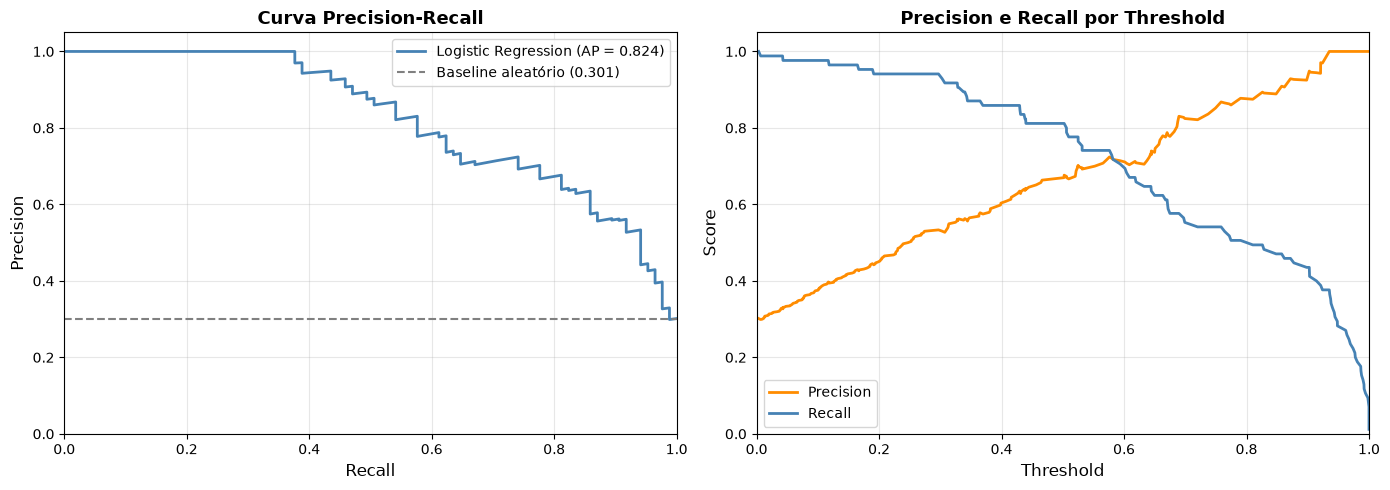

In [54]:
# Plotar
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Curva PR ---
ax1 = axes[0]
ax1.plot(recalls, precisions, color='steelblue', lw=2,
         label=f'Logistic Regression (AP = {av_precision:.3f})')
ax1.axhline(y=baseline, color='gray', linestyle='--', lw=1.5,
            label=f'Baseline aleatório ({baseline:.3f})')
ax1.set_xlabel('Recall', fontsize=12)
ax1.set_ylabel('Precision', fontsize=12)
ax1.set_title('Curva Precision-Recall', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1.05])
ax1.grid(alpha=0.3)

# --- Precision e Recall por threshold ---
ax2 = axes[1]
ax2.plot(thresholds, precisions[:-1], color='darkorange', lw=2, label='Precision')
ax2.plot(thresholds, recalls[:-1],    color='steelblue',  lw=2, label='Recall')
ax2.set_xlabel('Threshold', fontsize=12)
ax2.set_ylabel('Score', fontsize=12)
ax2.set_title('Precision e Recall por Threshold', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.set_xlim([0, 1])
ax2.set_ylim([0, 1.05])
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('precision_recall_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [55]:
# -------------------------------------------------------
# Critério 1: maximizar F1-Score
# (equilíbrio harmônico entre Precision e Recall)
# -------------------------------------------------------
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (
    precisions[:-1] + recalls[:-1] + 1e-10
)
best_idx_f1 = np.argmax(f1_scores)
threshold_f1 = thresholds[best_idx_f1]

print("=== Threshold ótimo pelo F1-Score ===")
print(f"Threshold:  {threshold_f1:.4f}")
print(f"F1-Score:   {f1_scores[best_idx_f1]:.4f}")
print(f"Precision:  {precisions[best_idx_f1]:.4f}")
print(f"Recall:     {recalls[best_idx_f1]:.4f}")

# -------------------------------------------------------
# Critério 2: Recall mínimo garantido pelo negócio
# Ex: "quero capturar pelo menos 80% dos fraudes"
# -------------------------------------------------------
recall_minimo = 0.80
mask_recall = recalls[:-1] >= recall_minimo
if mask_recall.any():
    # Dentre os thresholds que atingem o recall mínimo,
    # escolher o que maximiza Precision
    precisions_filtradas = np.where(mask_recall, precisions[:-1], 0)
    best_idx_recall = np.argmax(precisions_filtradas)
    threshold_recall = thresholds[best_idx_recall]

    print(f"\n=== Threshold com Recall ≥ {recall_minimo} ===")
    print(f"Threshold:  {threshold_recall:.4f}")
    print(f"Precision:  {precisions[best_idx_recall]:.4f}")
    print(f"Recall:     {recalls[best_idx_recall]:.4f}")
    print(f"F1-Score:   {f1_scores[best_idx_recall]:.4f}")

# -------------------------------------------------------
# Critério 3: Precision mínima garantida pelo negócio
# Ex: "quero que pelo menos 70% dos alertas sejam verdadeiros"
# -------------------------------------------------------
precision_minima = 0.70
mask_prec = precisions[:-1] >= precision_minima
if mask_prec.any():
    recalls_filtrados = np.where(mask_prec, recalls[:-1], 0)
    best_idx_prec = np.argmax(recalls_filtrados)
    threshold_prec = thresholds[best_idx_prec]

    print(f"\n=== Threshold com Precision ≥ {precision_minima} ===")
    print(f"Threshold:  {threshold_prec:.4f}")
    print(f"Precision:  {precisions[best_idx_prec]:.4f}")
    print(f"Recall:     {recalls[best_idx_prec]:.4f}")
    print(f"F1-Score:   {f1_scores[best_idx_prec]:.4f}")

=== Threshold ótimo pelo F1-Score ===
Threshold:  0.5022
F1-Score:   0.7380
Precision:  0.6765
Recall:     0.8118

=== Threshold com Recall ≥ 0.8 ===
Threshold:  0.5022
Precision:  0.6765
Recall:     0.8118
F1-Score:   0.7380

=== Threshold com Precision ≥ 0.7 ===
Threshold:  0.5250
Precision:  0.7021
Recall:     0.7765
F1-Score:   0.7374
